# 3.4. Tiền xử lý và đánh giá chất lượng dữ liệu FinIntel

Notebook sử dụng bản sao thực nghiệm 375 doanh nghiệp trong `data/go_live_nfr_run`.
Mốc thông tin được lấy từ manifest của thực nghiệm, không phải ngày chạy máy.
Toàn bộ bảng và biểu đồ bên dưới được tính lại từ dữ liệu thật bằng các hàm hiện có
trong dự án. Không tải dữ liệu mạng, không sửa kho nguồn và không huấn luyện lại mô hình.

**Cách sử dụng:** các ô đã có kết quả để chụp trực tiếp. Ảnh PNG và bản HTML độc lập
nằm trong `notebooks/outputs/3_4/`. Mở notebook tại dự án và dùng Run All nếu muốn tính lại.
Kernel cần truy cập các thư viện đang có trong `.venv`; việc chọn/cài kernel Jupyter
thuộc môi trường trình soạn thảo, không làm thay đổi dependency của ứng dụng.

Các kết quả ở bước dữ liệu chuẩn hóa, sau cổng chất lượng và tập học máy có mẫu số khác nhau.
Giá trị NULL không được tự đổi thành 0. Không coi mọi dòng cùng doanh nghiệp/kỳ là trùng lặp:
phải xét khoản mục, phạm vi, taxonomy và phiên bản báo cáo.


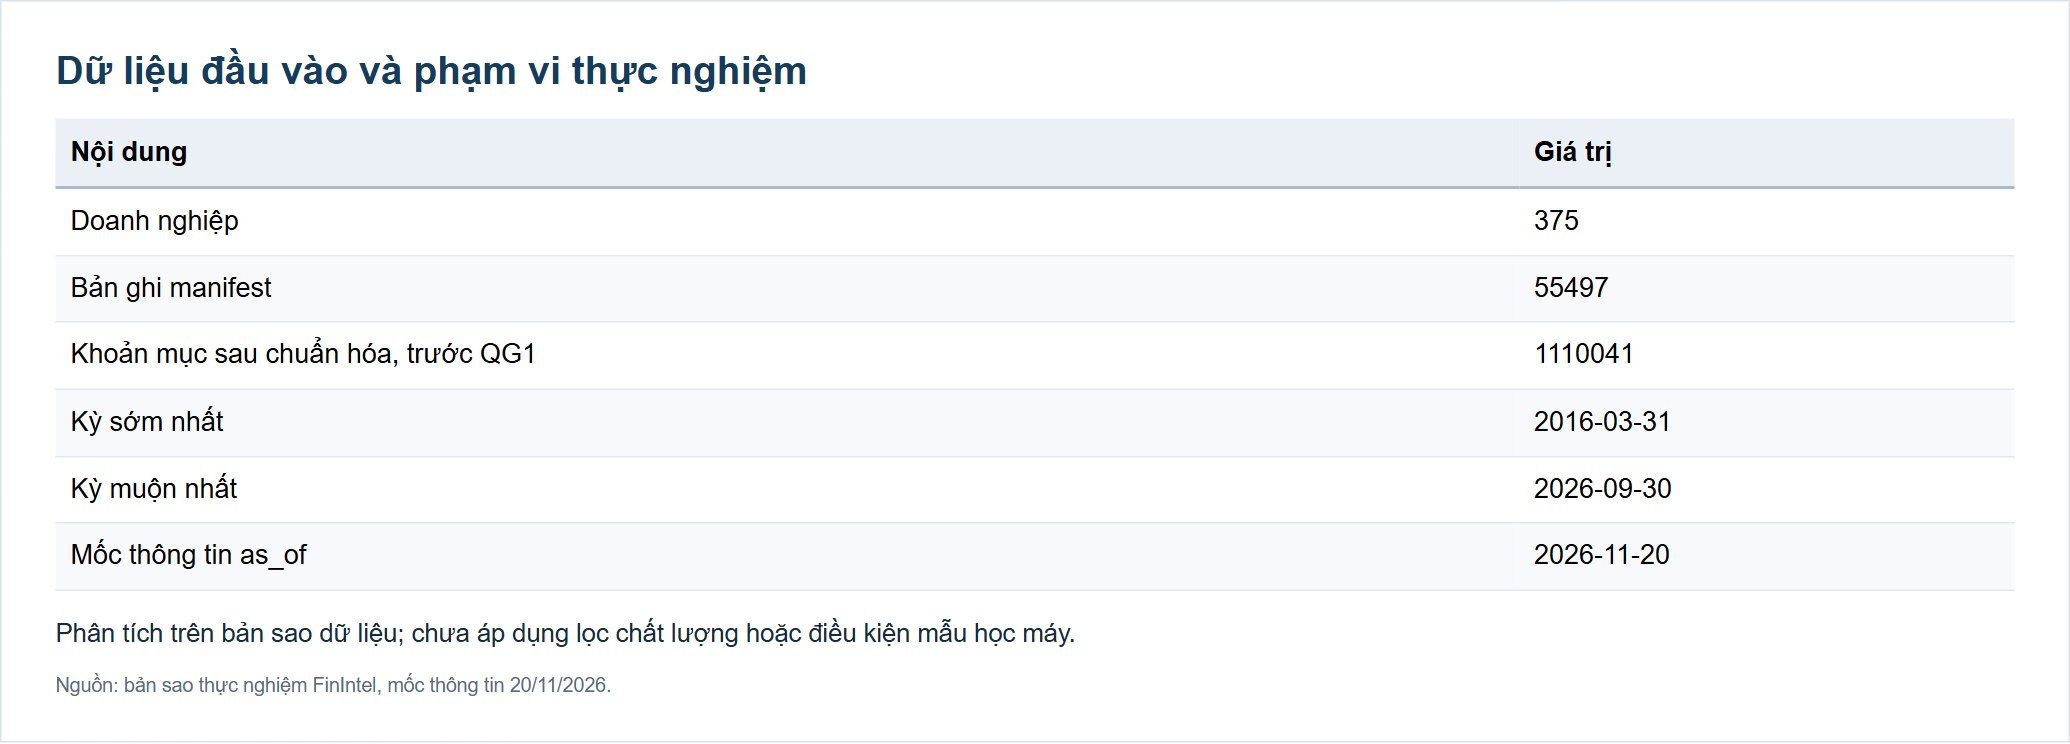

In [1]:
from pathlib import Path
from datetime import date, datetime, timezone
from concurrent.futures import ThreadPoolExecutor
from dataclasses import fields
import hashlib, html, json, math, sqlite3, sys
import numpy as np
import polars as pl
import plotly.graph_objects as go


def find_project():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "src/finintel").is_dir() and (
            candidate / "pyproject.toml"
        ).is_file():
            return candidate
    raise RuntimeError("Mở notebook bên trong thư mục dự án FinIntel.")


ROOT = find_project()
sys.path.insert(0, str(ROOT / "src"))
from finintel.storage.schemas import (
    FINANCIAL_FACTS_KEY,
    FINANCIAL_FACTS_SCHEMA,
    canonicalize_financial_facts,
)
from finintel.quality.gate import evaluate_quality_gate
from finintel.normalization.mapper import TaxonomyMapper
from finintel.domain.schemas import FilingMetadata
from finintel.analytics.intermediates import prepare_periods
from finintel.analytics.ratios import calculate_ratios
from finintel.ml.classical_scores import add_classical_scores
from finintel.ml.supervised.target import build_distress_targets
from finintel.ml.supervised.temporal_split import build_pit_ml_splits
from finintel.ml.supervised.train import BASE_FEATURES, SECTOR_ADJUSTED_FEATURES
from finintel.ml.unsupervised import CrossSectionalPreprocessor

# Chỉ đọc bản sao thực nghiệm. Không tự tìm/chuyển sang kho thu thập gốc.
DATA_ROOT = ROOT / "data/go_live_nfr_run"
FACTS_PATH = (
    DATA_ROOT
    / "curated/financial_facts/b6_norm_full_nfr_after_20261120T155606Z/financial_facts.parquet"
)
ISSUERS_PATH = DATA_ROOT / "curated/issuers.parquet"
STATE_PATH = DATA_ROOT / "metadata/state.sqlite"
MANIFEST_PATH = (
    DATA_ROOT
    / "metadata/ml_runs/e221ee76-98a1-4510-92ba-cb6a950e36f9/ml_run_manifest.json"
)
for path in (FACTS_PATH, ISSUERS_PATH, STATE_PATH, MANIFEST_PATH):
    if not path.is_file():
        raise FileNotFoundError(
            f"Thiếu đầu vào đã chỉ định: {path}. Không thay bằng dữ liệu giả."
        )
RUN_MANIFEST = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
AS_OF = date.fromisoformat(RUN_MANIFEST["as_of"])
VALIDATION_START = date.fromisoformat(RUN_MANIFEST["validation_start"])
TEST_START = date.fromisoformat(RUN_MANIFEST["test_start"])
SCOPE = RUN_MANIFEST["statement_scope"]
FEATURES = (
    SECTOR_ADJUSTED_FEATURES
    if RUN_MANIFEST["feature_set"] == "sector_adjusted"
    else BASE_FEATURES
)
SOURCE_NOTE = f"Nguồn: bản sao thực nghiệm FinIntel, mốc thông tin {AS_OF:%d/%m/%Y}."
COLORS = ["#245A81", "#168B83", "#E4A33A", "#C05252", "#7C65A9"]

CSS = """<style>
.fi-card{background:white;color:#172B3A;font-family:Arial,sans-serif;padding:30px 36px;max-width:1380px;border:1px solid #d9e2eb;box-sizing:border-box;}
.fi-card h2{font-size:26px;line-height:1.3;margin:0 0 14px;color:#153c5a;}
.fi-card table{border-collapse:collapse;width:100%;font-size:18px;line-height:1.42;}
.fi-card th{background:#eaf0f6;text-align:left;border-bottom:2px solid #a7bbce;padding:10px;}
.fi-card td{border-bottom:1px solid #e1e7ed;padding:9px 10px;overflow-wrap:anywhere;}
.fi-card tr:nth-child(even) td{background:#f7f9fc;}
.fi-card .caption{font-size:17px;line-height:1.5;margin:16px 0 8px;}
.fi-card .source{font-size:13px;color:#586a7c;margin-top:14px;}
</style>"""


def fmt(value):
    if value is None:
        return "NULL"
    if isinstance(value, (date, datetime)):
        return value.strftime("%d/%m/%Y")
    if isinstance(value, (bool, np.bool_)):
        return "Có" if value else "Không"
    if isinstance(value, (int, np.integer)):
        return f"{int(value):,}".replace(",", ".")
    if isinstance(value, (float, np.floating)):
        if not math.isfinite(float(value)):
            return str(value)
        return (
            f"{float(value):,.4f}".replace(",", "_").replace(".", ",").replace("_", ".")
        )
    if isinstance(value, (list, tuple)):
        return ", ".join(map(str, value))
    return str(value)


def publish(payload):
    if "_CAPTURE" in globals():
        _CAPTURE(payload)
    else:
        from IPython.display import HTML, display

        if payload["kind"] == "table":
            display(HTML(payload["html"]))
        else:
            fig = go.Figure(payload["figure"])
            display(HTML(fig.to_html(include_plotlyjs=True, full_html=False)))
            display(HTML(f"<p>{html.escape(payload['caption'])}</p>"))


def show_table(title, frame, caption="", limit=18):
    df = frame if isinstance(frame, pl.DataFrame) else pl.DataFrame(frame)
    visible = df.head(limit)
    head = "".join(f"<th>{html.escape(x)}</th>" for x in visible.columns)
    rows = "".join(
        "<tr>" + "".join(f"<td>{html.escape(fmt(v))}</td>" for v in row) + "</tr>"
        for row in visible.iter_rows()
    )
    extra = f" Hiển thị {visible.height}/{df.height} dòng." if df.height > limit else ""
    card = (
        CSS
        + f'<div class="fi-card"><h2>{html.escape(title)}</h2><table><thead><tr>{head}</tr></thead><tbody>{rows}</tbody></table><p class="caption">{html.escape(caption + extra)}</p><div class="source">{html.escape(SOURCE_NOTE)}</div></div>'
    )
    publish({"kind": "table", "title": title, "html": card, "caption": caption + extra})


def show_figure(title, fig, caption="", height=620):
    fig.update_layout(
        template="plotly_white",
        width=1200,
        height=height,
        font=dict(family="Arial", size=18, color="#172B3A"),
        title=dict(text=title, x=0.04, font=dict(size=25)),
        margin=dict(
            l=300
            if any(getattr(t, "orientation", None) == "h" for t in fig.data)
            else 100,
            r=70,
            t=100,
            b=125,
        ),
        legend=dict(orientation="h", y=-0.18),
        paper_bgcolor="white",
        plot_bgcolor="white",
    )
    publish(
        {
            "kind": "figure",
            "title": title,
            "figure": json.loads(fig.to_json()),
            "caption": caption,
        }
    )


def bar(title, labels, values, caption="", horizontal=False, percent=False):
    text = [f"{x:.2f}%" if percent else f"{int(x):,}".replace(",", ".") for x in values]
    if horizontal:
        fig = go.Figure(
            go.Bar(
                y=labels,
                x=values,
                orientation="h",
                text=text,
                textposition="outside",
                marker_color=COLORS[0],
                cliponaxis=False,
            )
        )
        fig.update_yaxes(autorange="reversed")
        fig.update_xaxes(title="Tỷ lệ (%)" if percent else "Số lượng")
        fig.update_layout(margin=dict(l=270))
    else:
        fig = go.Figure(
            go.Bar(
                x=labels,
                y=values,
                text=text,
                textposition="outside",
                marker_color=COLORS[: len(values)] if len(values) <= 5 else COLORS[0],
                cliponaxis=False,
            )
        )
        fig.update_yaxes(
            title="Tỷ lệ (%)" if percent else "Số lượng", rangemode="tozero"
        )
    show_figure(title, fig, caption)


facts = pl.read_parquet(FACTS_PATH)
issuers = pl.read_parquet(ISSUERS_PATH)
with sqlite3.connect(STATE_PATH.as_uri() + "?mode=ro", uri=True) as conn:
    manifest = pl.read_database("SELECT * FROM filings_manifest", conn)
MANIFEST_ORIGINAL = manifest.clone()
for name in (
    "period_start_date",
    "period_end_date",
    "fiscal_year_start_date",
    "published_at",
    "effective_available_at",
):
    if name in manifest.columns:
        manifest = manifest.with_columns(pl.col(name).str.to_date(strict=False))
SOURCE_HASHES = {
    str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
    for p in (FACTS_PATH, ISSUERS_PATH, MANIFEST_PATH)
}
show_table(
    "Dữ liệu đầu vào và phạm vi thực nghiệm",
    [
        {"Nội dung": "Doanh nghiệp", "Giá trị": str(issuers.height)},
        {"Nội dung": "Bản ghi manifest", "Giá trị": str(manifest.height)},
        {
            "Nội dung": "Khoản mục sau chuẩn hóa, trước QG1",
            "Giá trị": str(facts.height),
        },
        {"Nội dung": "Kỳ sớm nhất", "Giá trị": str(facts["period_end_date"].min())},
        {"Nội dung": "Kỳ muộn nhất", "Giá trị": str(facts["period_end_date"].max())},
        {"Nội dung": "Mốc thông tin as_of", "Giá trị": str(AS_OF)},
    ],
    "Phân tích trên bản sao dữ liệu; chưa áp dụng lọc chất lượng hoặc điều kiện mẫu học máy.",
)


## 3.4.1. Kiểm tra dữ liệu thiếu, trùng lặp và sai định dạng

Kiểm tra riêng từng tầng: cú pháp/hash các tệp JSON nguồn; kiểu và miền giá trị
trong bảng đã chuẩn hóa; NULL theo cột; khóa ghép nghiệp vụ; sau đó chạy QG1 thật.
Các ví dụ sai định dạng không được tạo giả để làm đẹp kết quả. Kiểu đúng ở Parquet
không có nghĩa toàn bộ nội dung nghiệp vụ đều đúng. Số dòng trùng là số dòng dư
so với số khóa duy nhất; các phiên bản điều chỉnh hợp lệ không bị tính là trùng.


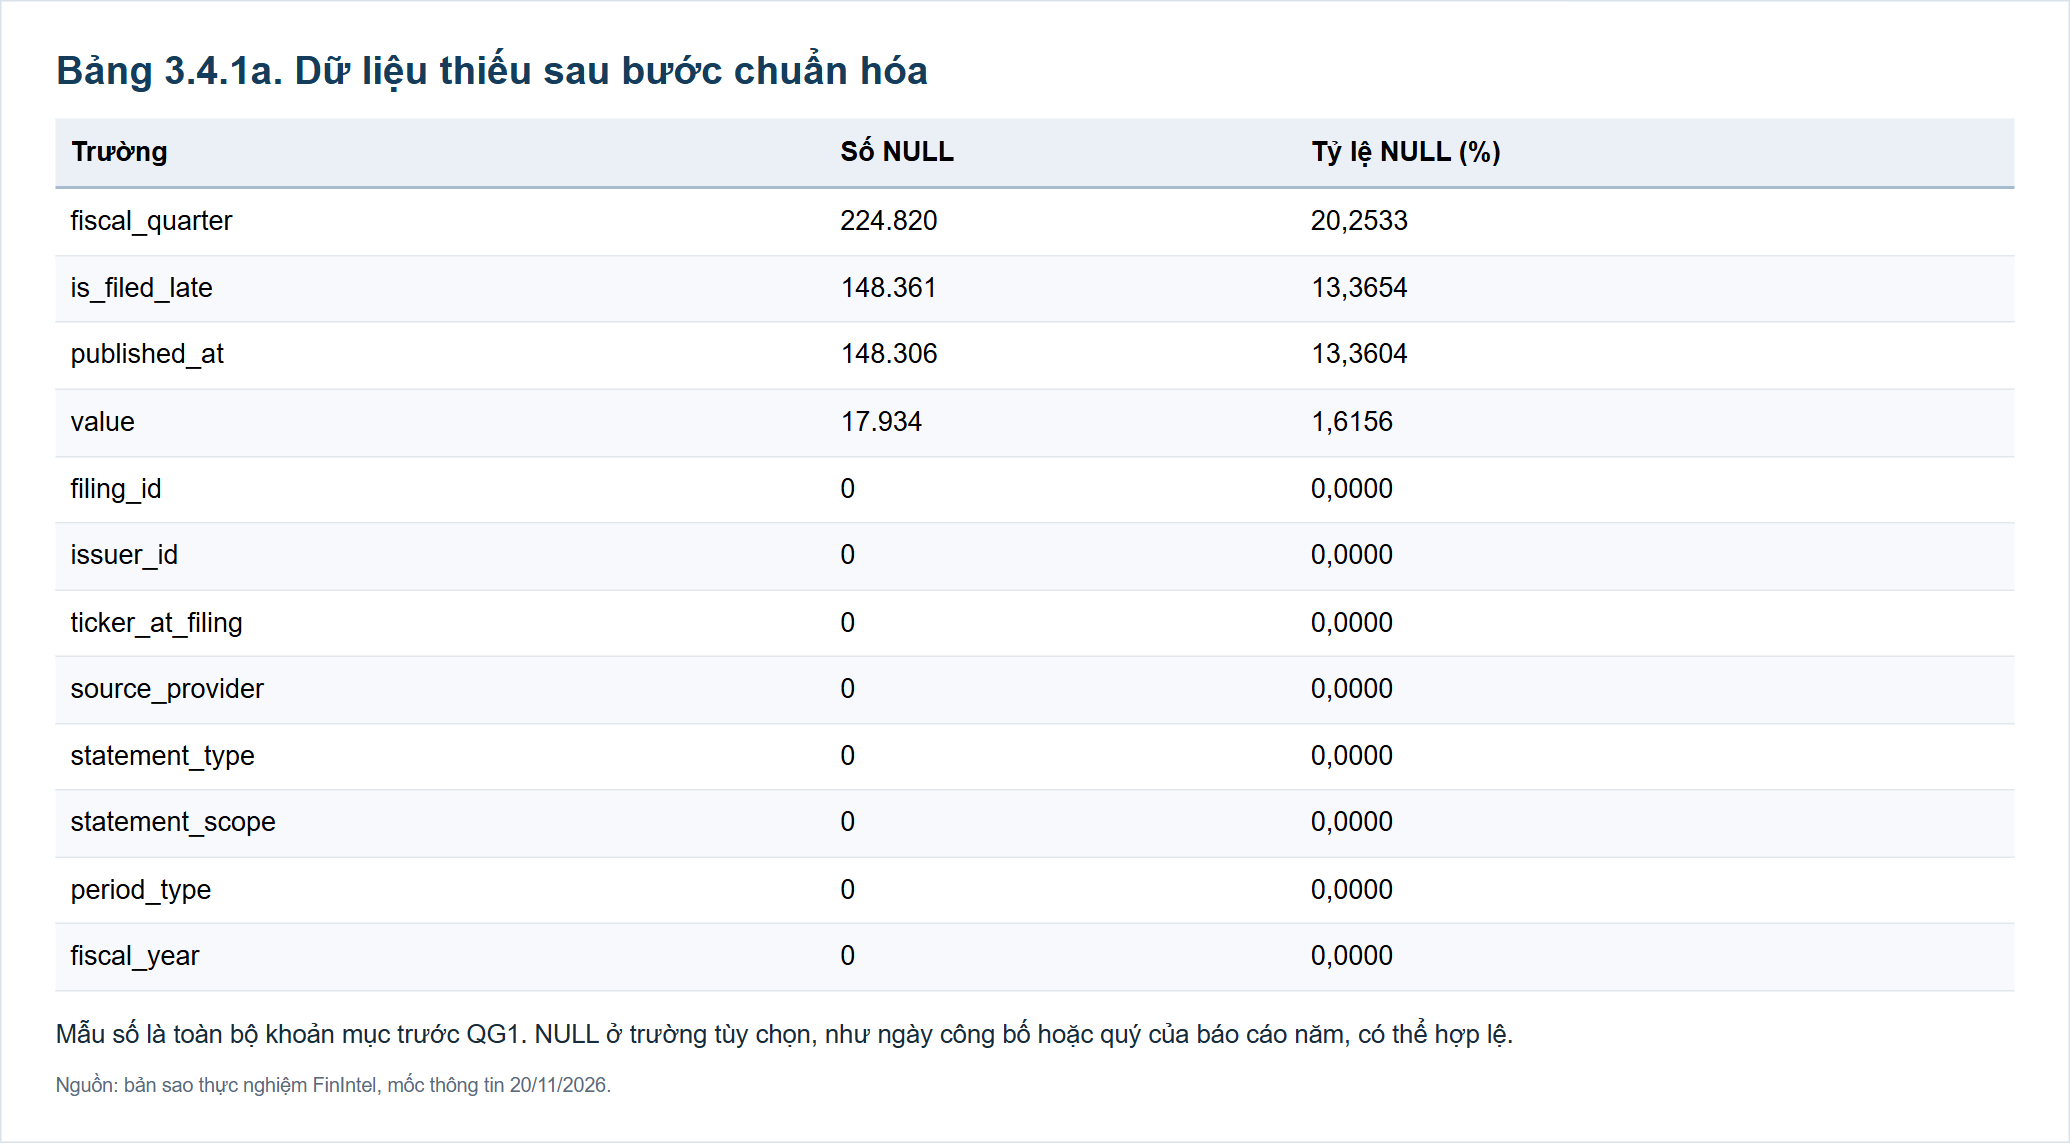

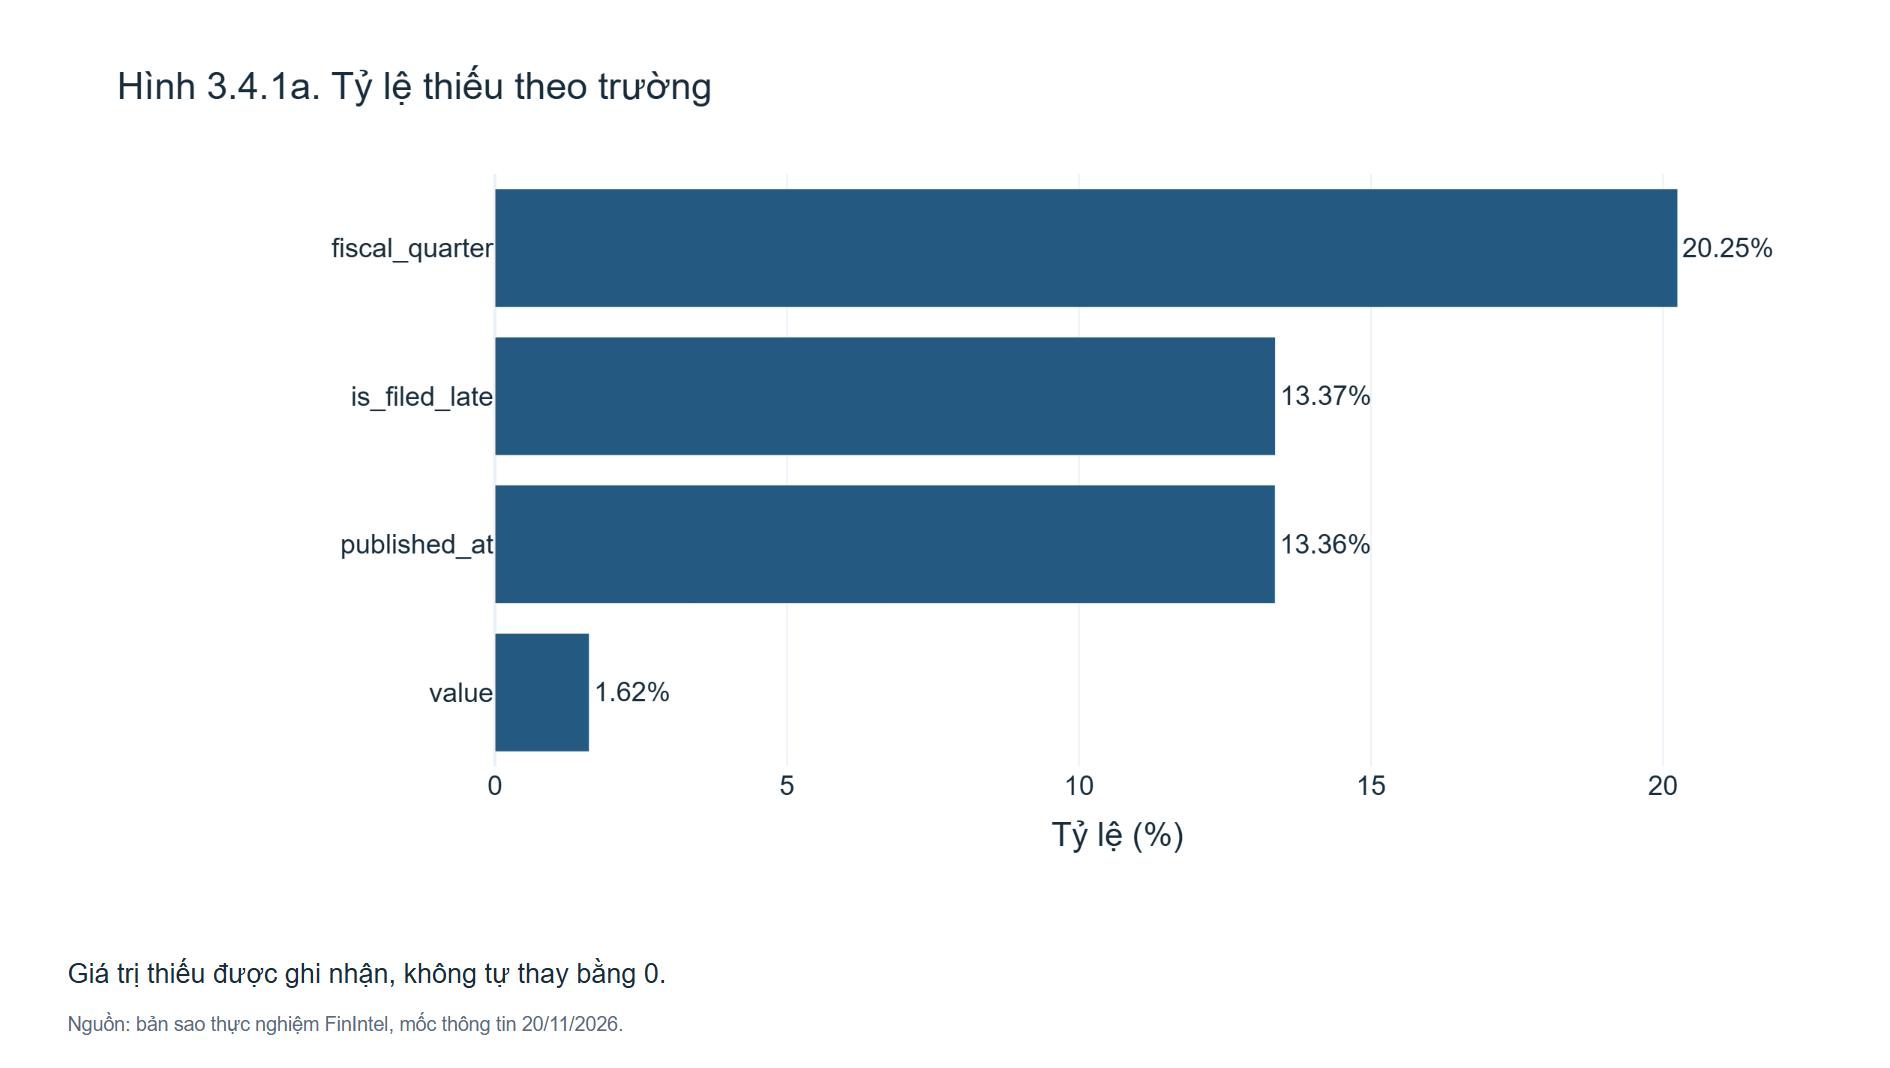

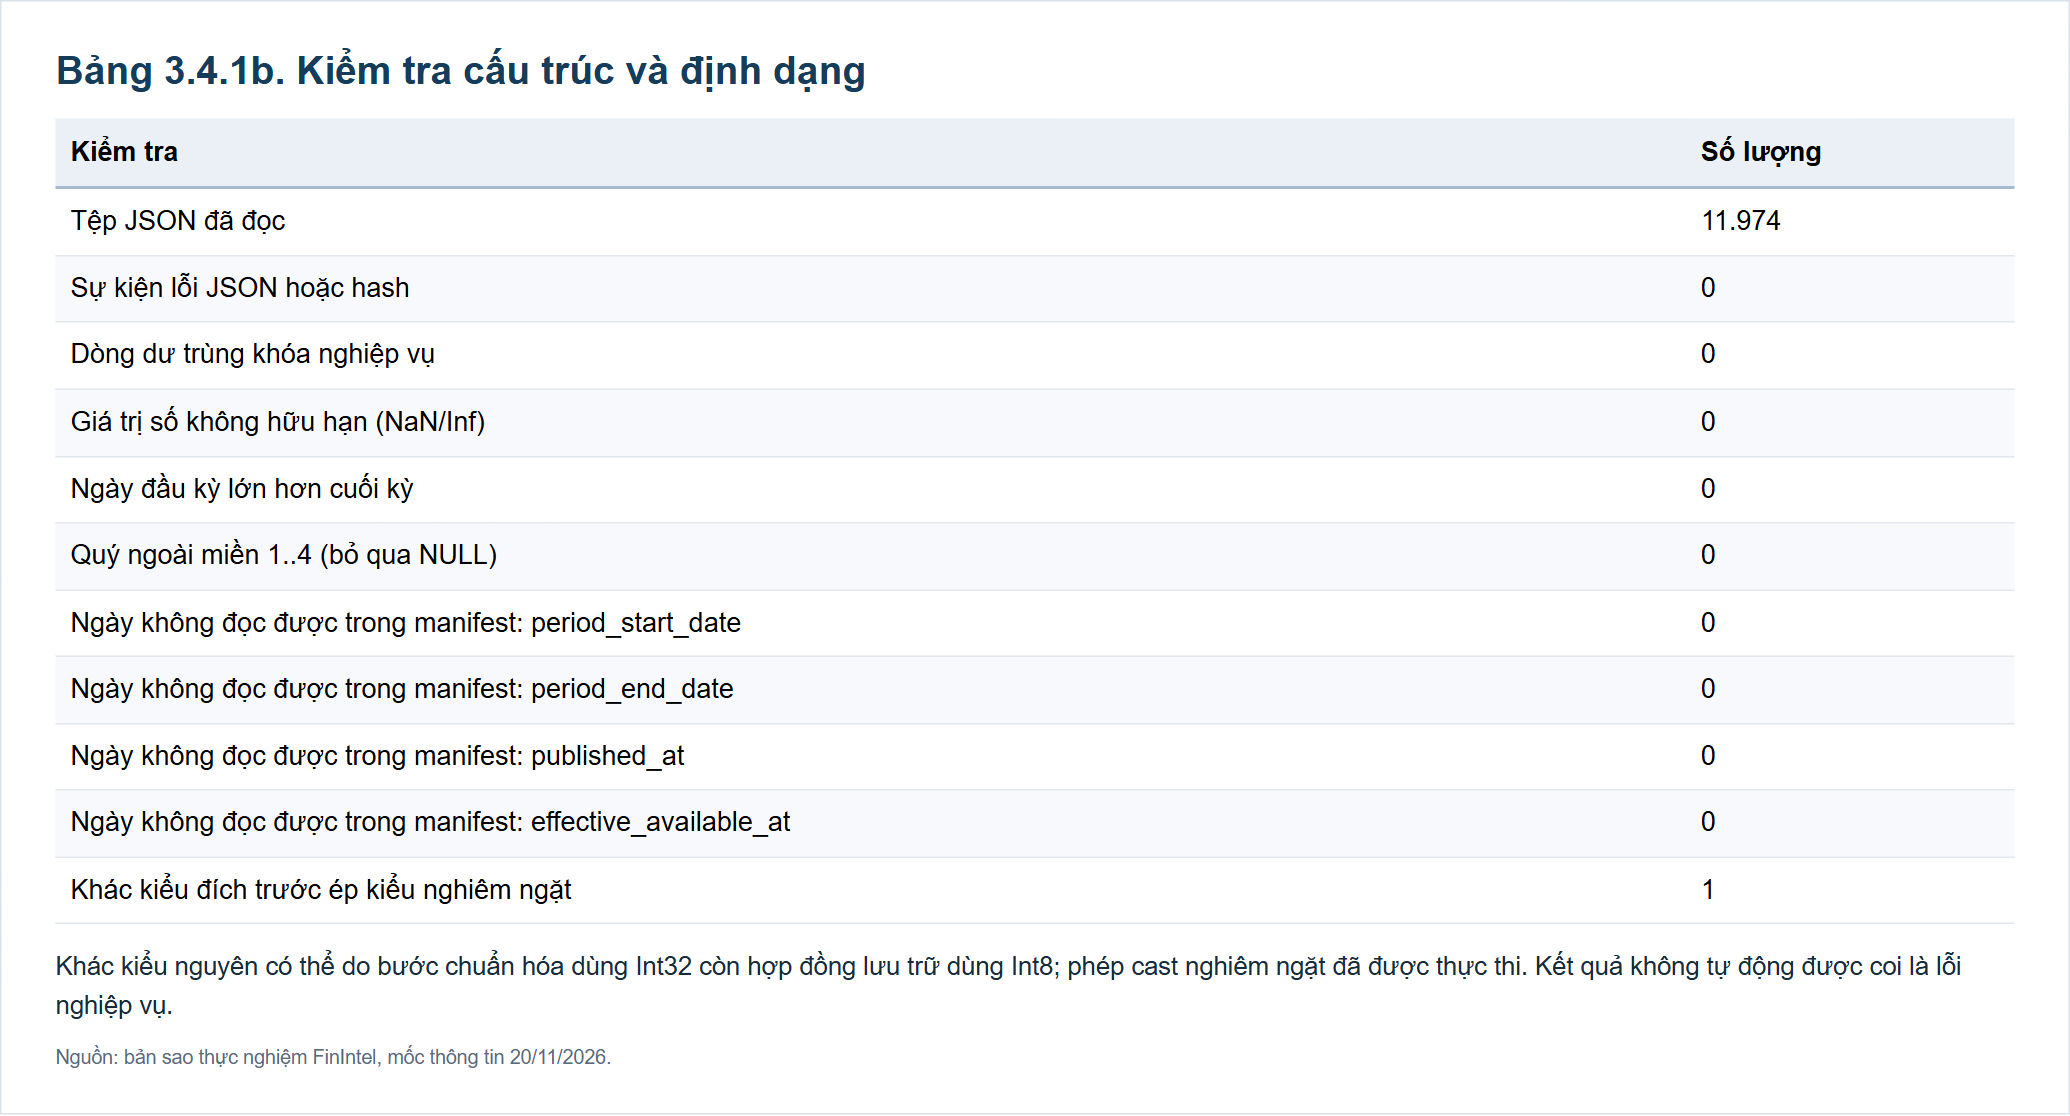

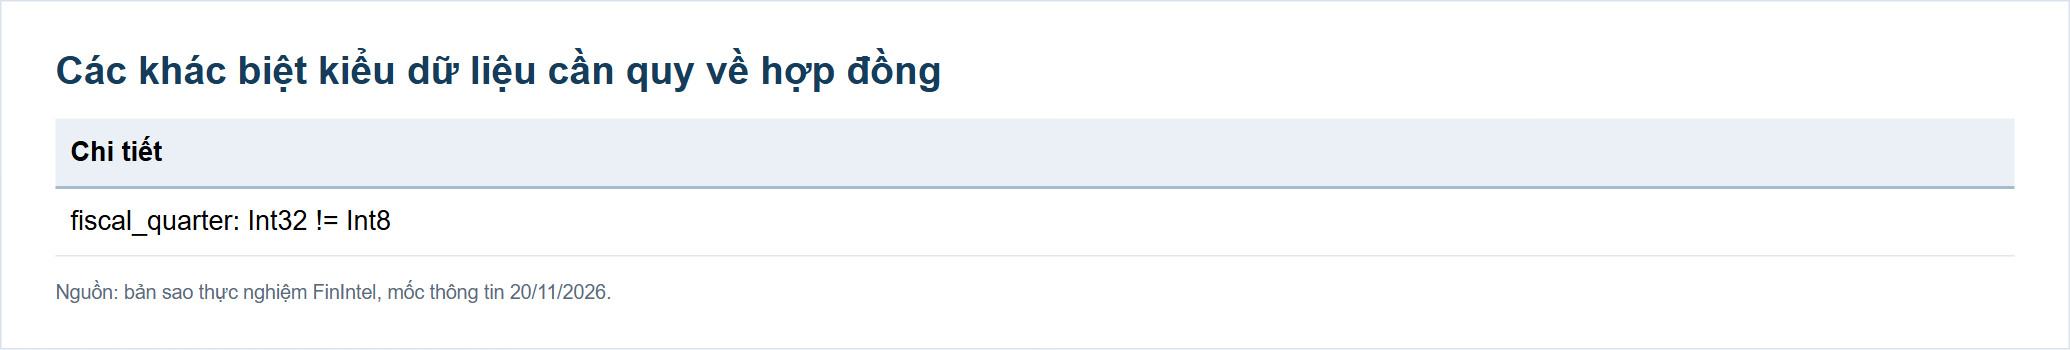

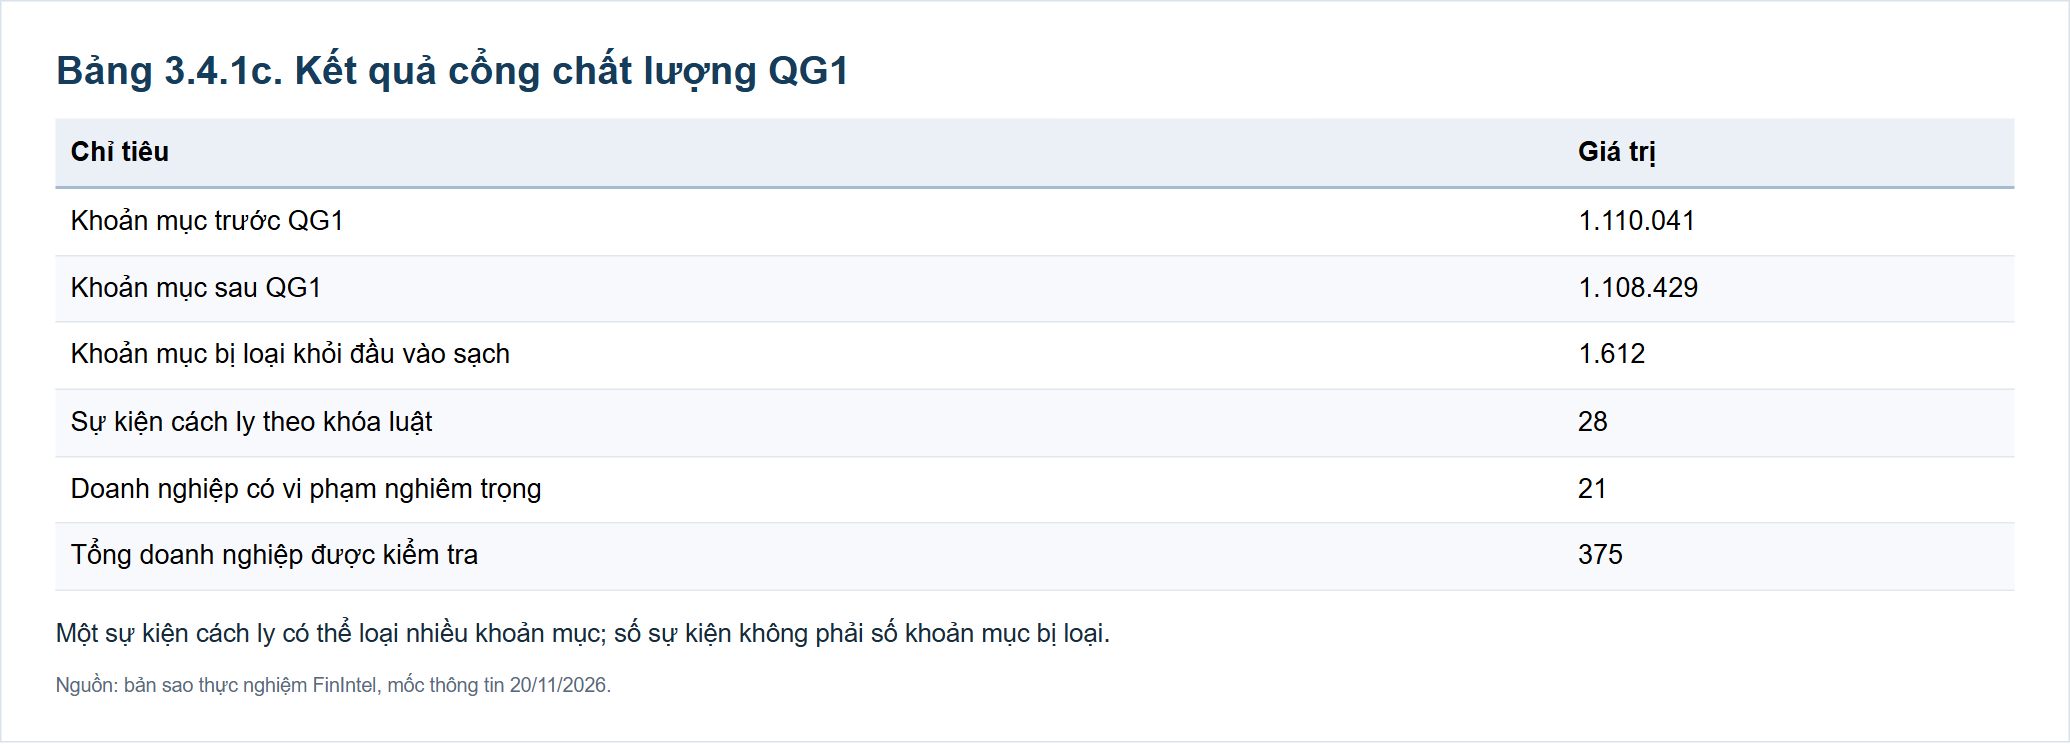

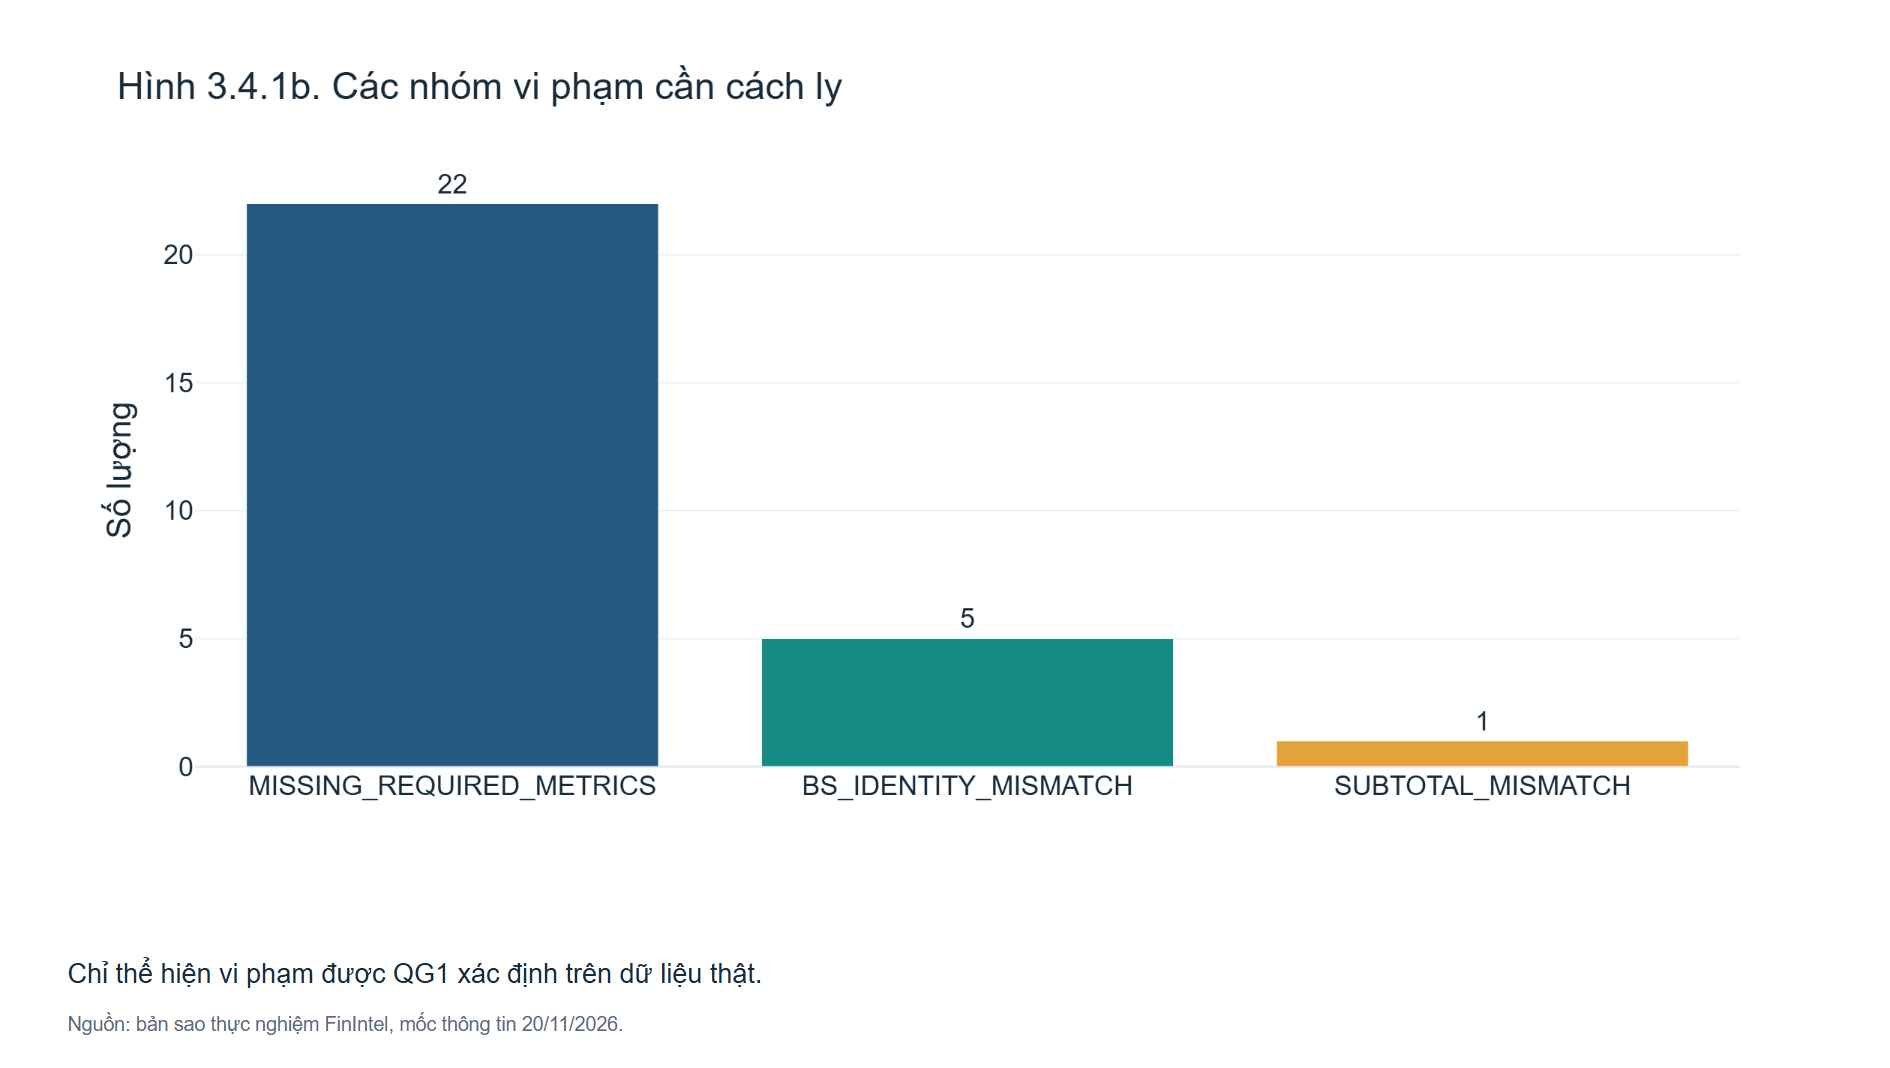

In [2]:
raw_paths = sorted((DATA_ROOT / "raw/sha256").glob("*/*.json"))
if not raw_paths:
    raise RuntimeError("Không có tệp JSON nguồn trong bản sao thực nghiệm.")


def inspect_raw_json(p):
    errors = []
    content = p.read_bytes()
    try:
        json.loads(content)
    except (ValueError, UnicodeError) as exc:
        errors.append({"Tệp": p.name, "Lỗi": "JSON: " + str(exc)[:90]})
    if hashlib.sha256(content).hexdigest() != p.stem:
        errors.append({"Tệp": p.name, "Lỗi": "SHA-256 nội dung không khớp tên tệp"})
    return errors


with ThreadPoolExecutor(max_workers=8) as pool:
    raw_errors = [
        error for errors in pool.map(inspect_raw_json, raw_paths) for error in errors
    ]

key_cols = list(FINANCIAL_FACTS_KEY)
duplicate_excess = facts.height - facts.select(key_cols).unique().height
null_rows = [
    {
        "Trường": c,
        "Số NULL": facts[c].null_count(),
        "Tỷ lệ NULL (%)": 100 * facts[c].null_count() / facts.height,
    }
    for c in facts.columns
]
null_summary = pl.DataFrame(null_rows).sort("Số NULL", descending=True)
show_table(
    "Bảng 3.4.1a. Dữ liệu thiếu sau bước chuẩn hóa",
    null_summary.head(12),
    "Mẫu số là toàn bộ khoản mục trước QG1. NULL ở trường tùy chọn, như ngày công bố hoặc quý của báo cáo năm, có thể hợp lệ.",
)
top_null = null_summary.filter(pl.col("Số NULL") > 0).head(10)
bar(
    "Hình 3.4.1a. Tỷ lệ thiếu theo trường",
    top_null["Trường"].to_list(),
    top_null["Tỷ lệ NULL (%)"].to_list(),
    "Giá trị thiếu được ghi nhận, không tự thay bằng 0.",
    horizontal=True,
    percent=True,
)

format_checks = [
    {"Kiểm tra": "Tệp JSON đã đọc", "Số lượng": len(raw_paths)},
    {"Kiểm tra": "Sự kiện lỗi JSON hoặc hash", "Số lượng": len(raw_errors)},
    {"Kiểm tra": "Dòng dư trùng khóa nghiệp vụ", "Số lượng": duplicate_excess},
    {
        "Kiểm tra": "Giá trị số không hữu hạn (NaN/Inf)",
        "Số lượng": facts.filter(
            pl.col("value").is_not_null() & ~pl.col("value").is_finite()
        ).height,
    },
    {
        "Kiểm tra": "Ngày đầu kỳ lớn hơn cuối kỳ",
        "Số lượng": facts.filter(
            pl.col("period_start_date") > pl.col("period_end_date")
        ).height,
    },
    {
        "Kiểm tra": "Quý ngoài miền 1..4 (bỏ qua NULL)",
        "Số lượng": facts.filter(
            pl.col("fiscal_quarter").is_not_null()
            & ~pl.col("fiscal_quarter").is_between(1, 4)
        ).height,
    },
]
for column in (
    "period_start_date",
    "period_end_date",
    "published_at",
    "effective_available_at",
):
    invalid_dates = MANIFEST_ORIGINAL.filter(
        pl.col(column).is_not_null()
        & pl.col(column).str.to_date(strict=False).is_null()
    ).height
    format_checks.append(
        {
            "Kiểm tra": f"Ngày không đọc được trong manifest: {column}",
            "Số lượng": invalid_dates,
        }
    )
dtype_issues = [
    f"{c}: {facts.schema.get(c)} != {dt}"
    for c, dt in FINANCIAL_FACTS_SCHEMA.items()
    if c in facts.columns and facts.schema[c].base_type() != dt.base_type()
]
# Canonicalize dùng phép ép kiểu nghiêm ngặt và kiểm tra miền của thư viện dự án.
canonical = canonicalize_financial_facts(facts)
format_checks.append(
    {
        "Kiểm tra": "Khác kiểu đích trước ép kiểu nghiêm ngặt",
        "Số lượng": len(dtype_issues),
    }
)
show_table(
    "Bảng 3.4.1b. Kiểm tra cấu trúc và định dạng",
    format_checks,
    "Khác kiểu nguyên có thể do bước chuẩn hóa dùng Int32 còn hợp đồng lưu trữ dùng Int8; phép cast nghiêm ngặt đã được thực thi. Kết quả không tự động được coi là lỗi nghiệp vụ.",
)
if raw_errors:
    show_table("Các lỗi tệp nguồn thực tế", raw_errors, limit=10)
if dtype_issues:
    show_table(
        "Các khác biệt kiểu dữ liệu cần quy về hợp đồng",
        [{"Chi tiết": v} for v in dtype_issues],
    )

qg = evaluate_quality_gate(
    canonical, issuers=issuers, checked_at=datetime(2026, 11, 20, tzinfo=timezone.utc)
)
clean_facts = qg.clean_facts
quarantine = qg.audit_quarantine
quality = qg.quality_summary
show_table(
    "Bảng 3.4.1c. Kết quả cổng chất lượng QG1",
    [
        {"Chỉ tiêu": "Khoản mục trước QG1", "Giá trị": canonical.height},
        {"Chỉ tiêu": "Khoản mục sau QG1", "Giá trị": clean_facts.height},
        {
            "Chỉ tiêu": "Khoản mục bị loại khỏi đầu vào sạch",
            "Giá trị": canonical.height - clean_facts.height,
        },
        {"Chỉ tiêu": "Sự kiện cách ly theo khóa luật", "Giá trị": quarantine.height},
        {
            "Chỉ tiêu": "Doanh nghiệp có vi phạm nghiêm trọng",
            "Giá trị": qg.critical_issuers,
        },
        {"Chỉ tiêu": "Tổng doanh nghiệp được kiểm tra", "Giá trị": qg.total_issuers},
    ],
    "Một sự kiện cách ly có thể loại nhiều khoản mục; số sự kiện không phải số khoản mục bị loại.",
)
if quarantine.height:
    qrules = quarantine.group_by("rule_code").len().sort("len", descending=True)
    bar(
        "Hình 3.4.1b. Các nhóm vi phạm cần cách ly",
        qrules["rule_code"].to_list(),
        qrules["len"].to_list(),
        "Chỉ thể hiện vi phạm được QG1 xác định trên dữ liệu thật.",
    )


## 3.4.2. Chuẩn hóa khoản mục, đơn vị tính và kỳ báo cáo

Tái chạy `TaxonomyMapper.map_metrics` trên một báo cáo FPT thật và so với dòng
chuẩn hóa tương ứng. Tệp nguồn được đọc ở bản sao dù đường dẫn trong manifest
còn trỏ về vị trí lịch sử. Chỉ đưa vào ví dụ đơn vị những hệ số thực sự xuất hiện.
Nếu dữ liệu dùng hệ số 1, không tạo tình huống nhân triệu/nhân nghìn giả.


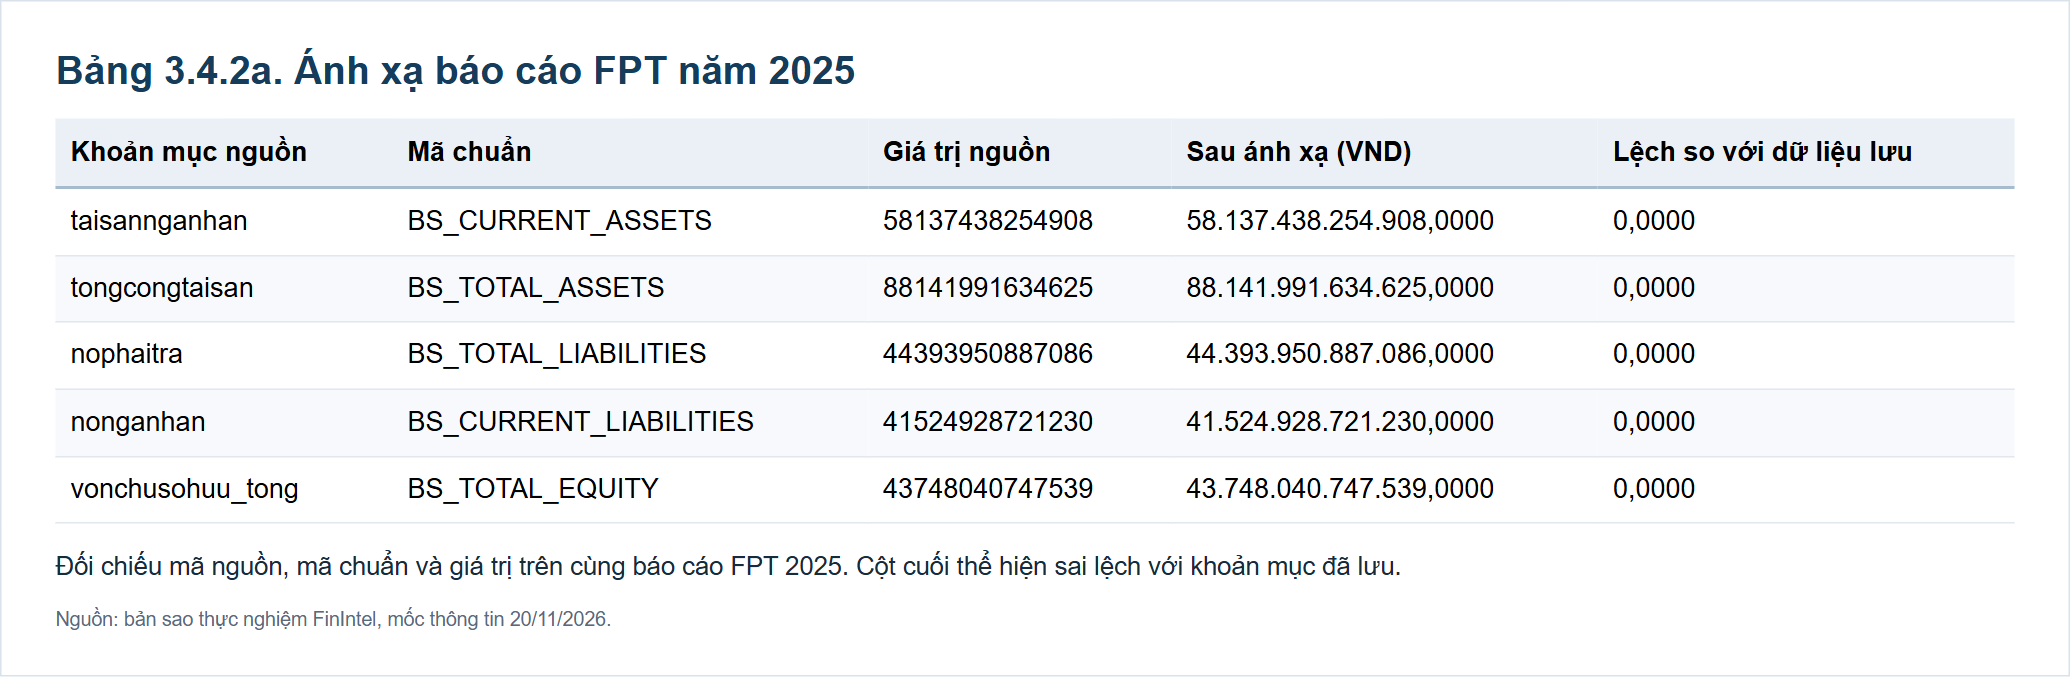

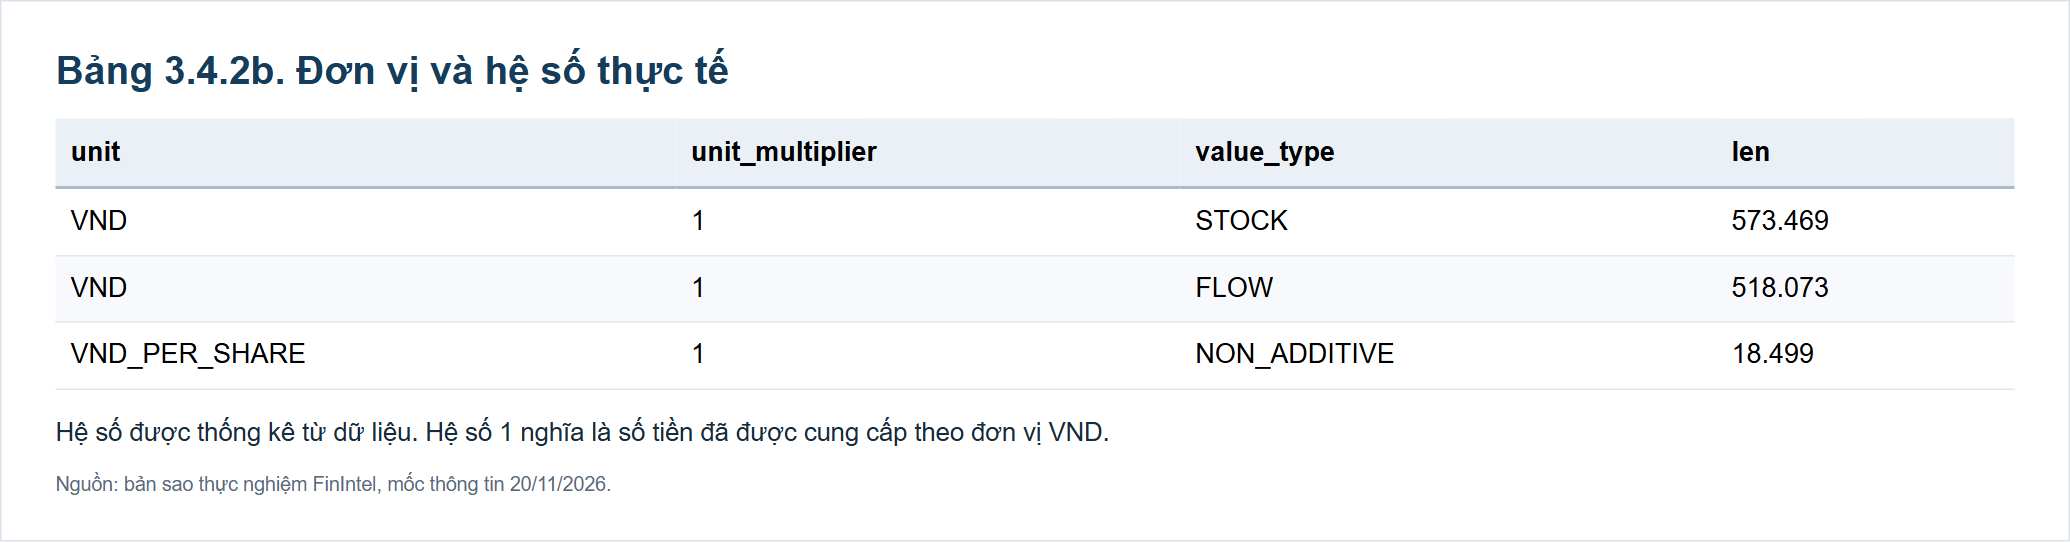

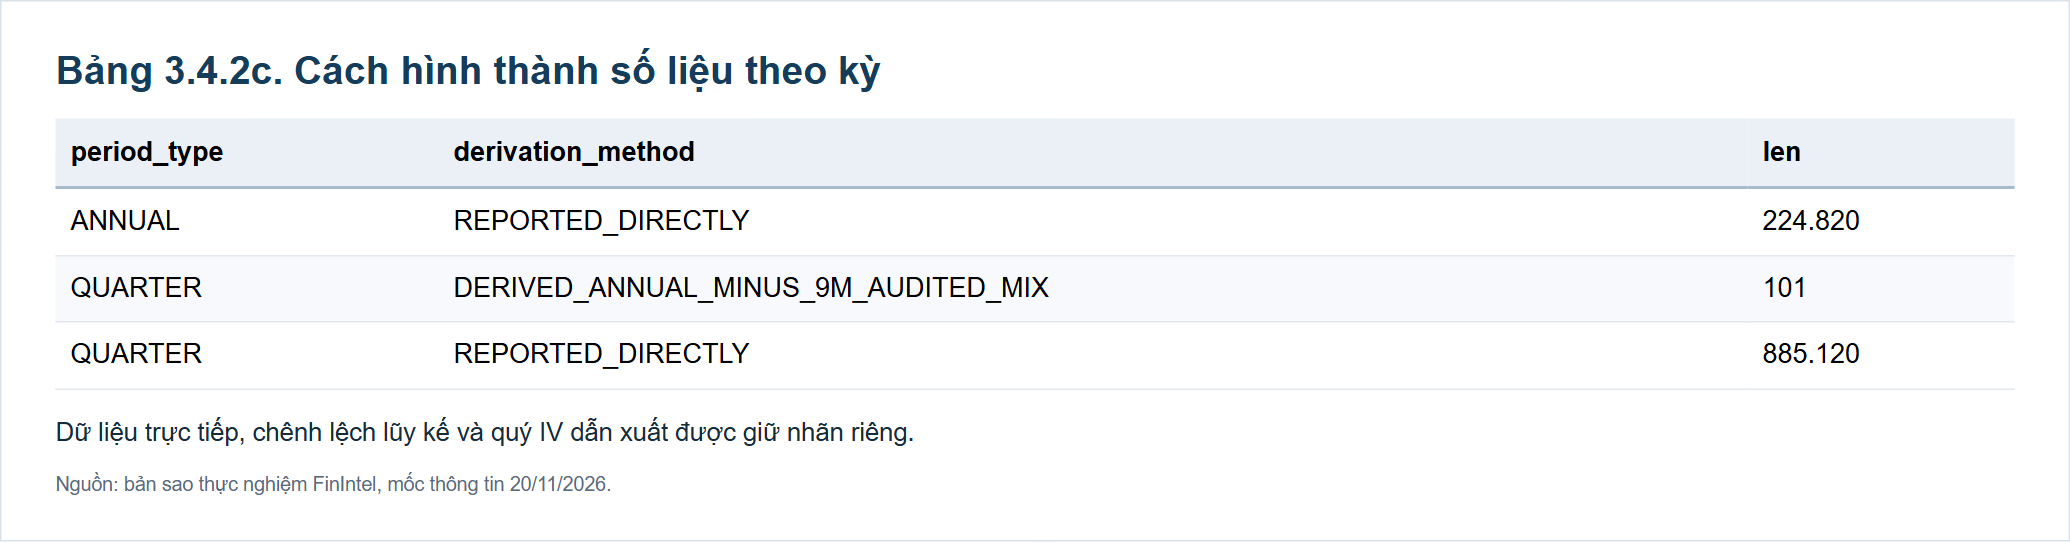

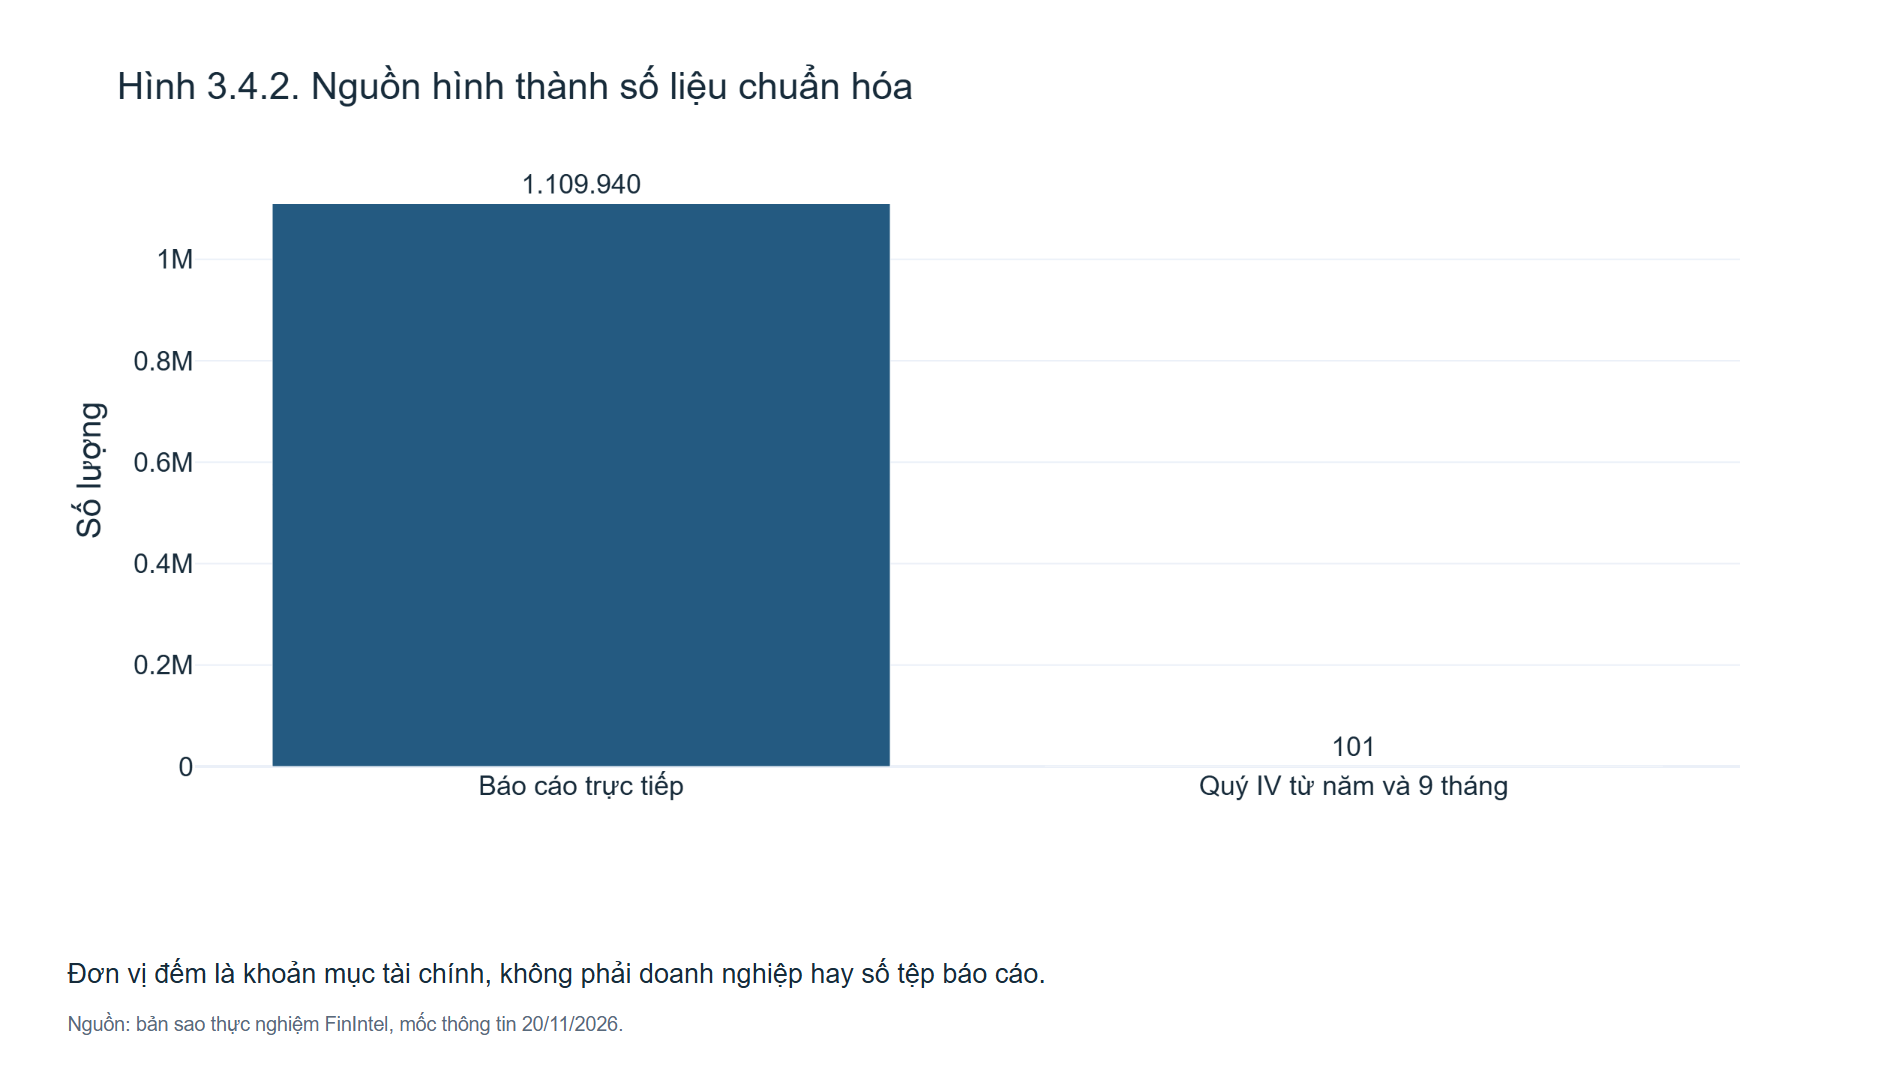

In [3]:
fpt_manifest = manifest.filter(
    (pl.col("ticker_at_filing") == "FPT")
    & (pl.col("period_type") == "ANNUAL")
    & (pl.col("fiscal_year") == 2025)
    & (pl.col("statement_type") == "BALANCE_SHEET")
).sort("revision_no", descending=True)
if fpt_manifest.is_empty():
    raise RuntimeError("Không tìm thấy báo cáo FPT 2025 để đối chiếu thực tế.")
source_row = fpt_manifest.row(0, named=True)
old_path = source_row["raw_archive_path"].replace("\\", "/")
suffix = (
    old_path.split("/raw/", 1)[1]
    if "/raw/" in old_path
    else old_path.removeprefix("raw/")
)
source_path = (DATA_ROOT / "raw" / suffix).resolve()
if not source_path.is_relative_to((DATA_ROOT / "raw").resolve()):
    raise RuntimeError("Đường dẫn nguồn vượt bản sao được phép đọc.")
body = json.loads(source_path.read_text(encoding="utf-8"))
locator = source_row["raw_record_locator"]
raw_record = dict(body["data"][int(locator.rsplit("/", 1)[1])])
raw_record.pop("year", None)
raw_record.pop("quarter", None)
metadata = FilingMetadata.from_mapping(
    {
        field.name: source_row[field.name]
        for field in fields(FilingMetadata)
        if field.name in source_row
    }
)
mapped, unmapped_example = TaxonomyMapper(ROOT / "config").map_metrics(
    raw_record,
    metadata,
    filing_id=source_row["filing_id"],
    source_provider=source_row["source_provider"],
    revision_no=source_row["revision_no"],
    unit_multiplier=1,
)
compare = []
for r in mapped.filter(
    pl.col("metric_id").is_in(
        [
            "BS_TOTAL_ASSETS",
            "BS_TOTAL_LIABILITIES",
            "BS_TOTAL_EQUITY",
            "BS_CURRENT_ASSETS",
            "BS_CURRENT_LIABILITIES",
        ]
    )
).iter_rows(named=True):
    stored = facts.filter(
        (pl.col("filing_id") == r["filing_id"])
        & (pl.col("metric_id") == r["metric_id"])
        & (pl.col("derivation_method") == "REPORTED_DIRECTLY")
    )
    stored_value = stored["value"][0] if stored.height else None
    compare.append(
        {
            "Khoản mục nguồn": r["raw_metric_key"],
            "Mã chuẩn": r["metric_id"],
            "Giá trị nguồn": str(raw_record.get(r["raw_metric_key"])),
            "Sau ánh xạ (VND)": r["value"],
            "Lệch so với dữ liệu lưu": None
            if stored_value is None
            else r["value"] - stored_value,
        }
    )
show_table(
    "Bảng 3.4.2a. Ánh xạ báo cáo FPT năm 2025",
    compare,
    "Đối chiếu mã nguồn, mã chuẩn và giá trị trên cùng báo cáo FPT 2025. Cột cuối thể hiện sai lệch với khoản mục đã lưu.",
)
unit_summary = (
    facts.group_by("unit", "unit_multiplier", "value_type")
    .len()
    .sort("len", descending=True)
)
show_table(
    "Bảng 3.4.2b. Đơn vị và hệ số thực tế",
    unit_summary,
    "Hệ số được thống kê từ dữ liệu. Hệ số 1 nghĩa là số tiền đã được cung cấp theo đơn vị VND.",
)
period_summary = (
    facts.group_by("period_type", "derivation_method")
    .len()
    .sort(["period_type", "derivation_method"])
)
show_table(
    "Bảng 3.4.2c. Cách hình thành số liệu theo kỳ",
    period_summary,
    "Dữ liệu trực tiếp, chênh lệch lũy kế và quý IV dẫn xuất được giữ nhãn riêng.",
)
derivation = facts.group_by("derivation_method").len().sort("len", descending=True)
derivation_names = {
    "REPORTED_DIRECTLY": "Báo cáo trực tiếp",
    "DERIVED_YTD_DIFF": "Chênh lệch lũy kế",
    "DERIVED_ANNUAL_MINUS_9M_AUDITED_MIX": "Quý IV từ năm và 9 tháng",
}
bar(
    "Hình 3.4.2. Nguồn hình thành số liệu chuẩn hóa",
    [derivation_names.get(v, v) for v in derivation["derivation_method"]],
    derivation["len"].to_list(),
    "Đơn vị đếm là khoản mục tài chính, không phải doanh nghiệp hay số tệp báo cáo.",
)


## 3.4.3. Xử lý lịch sử điều chỉnh và thời điểm công bố

Nhóm phiên bản theo nguồn, doanh nghiệp, loại báo cáo, phạm vi và kỳ. Báo cáo
kiểm toán hoặc điều chỉnh là phiên bản hợp lệ, không tự loại bằng deduplicate.
Ngày công bố chính xác và thời điểm ước tính được trình bày riêng.


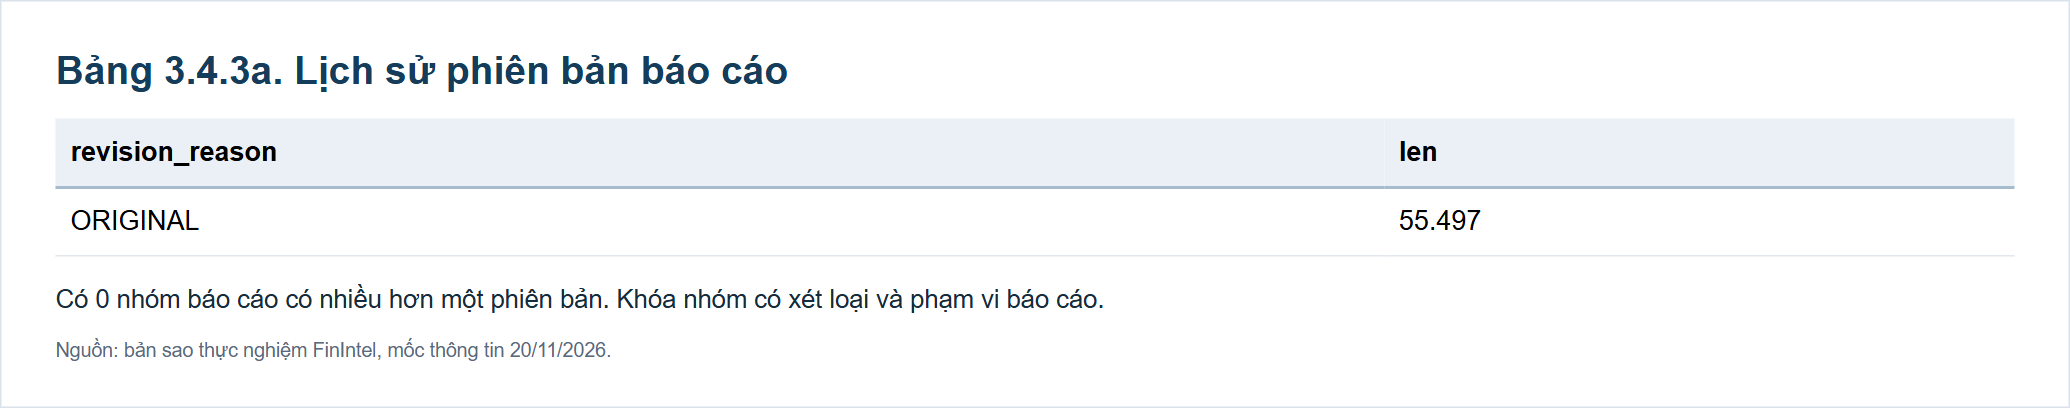

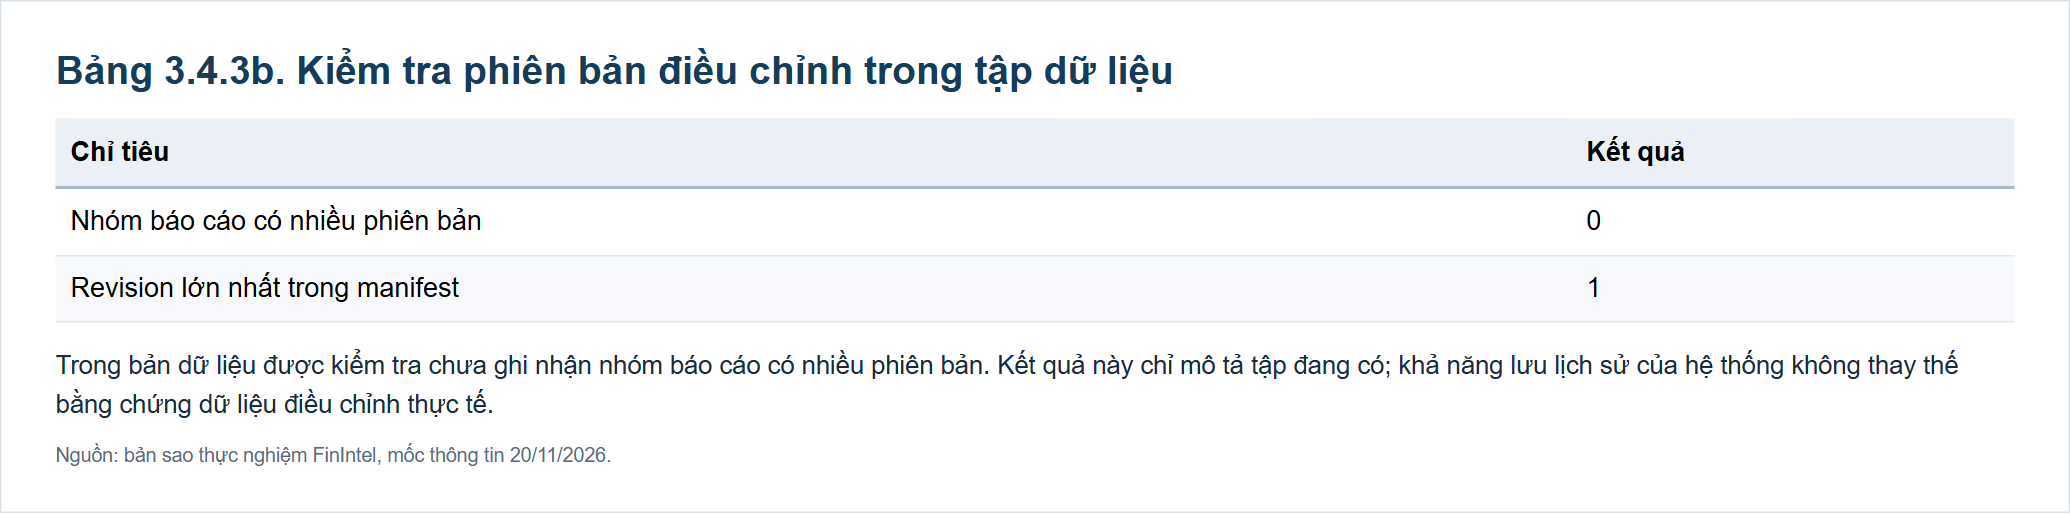

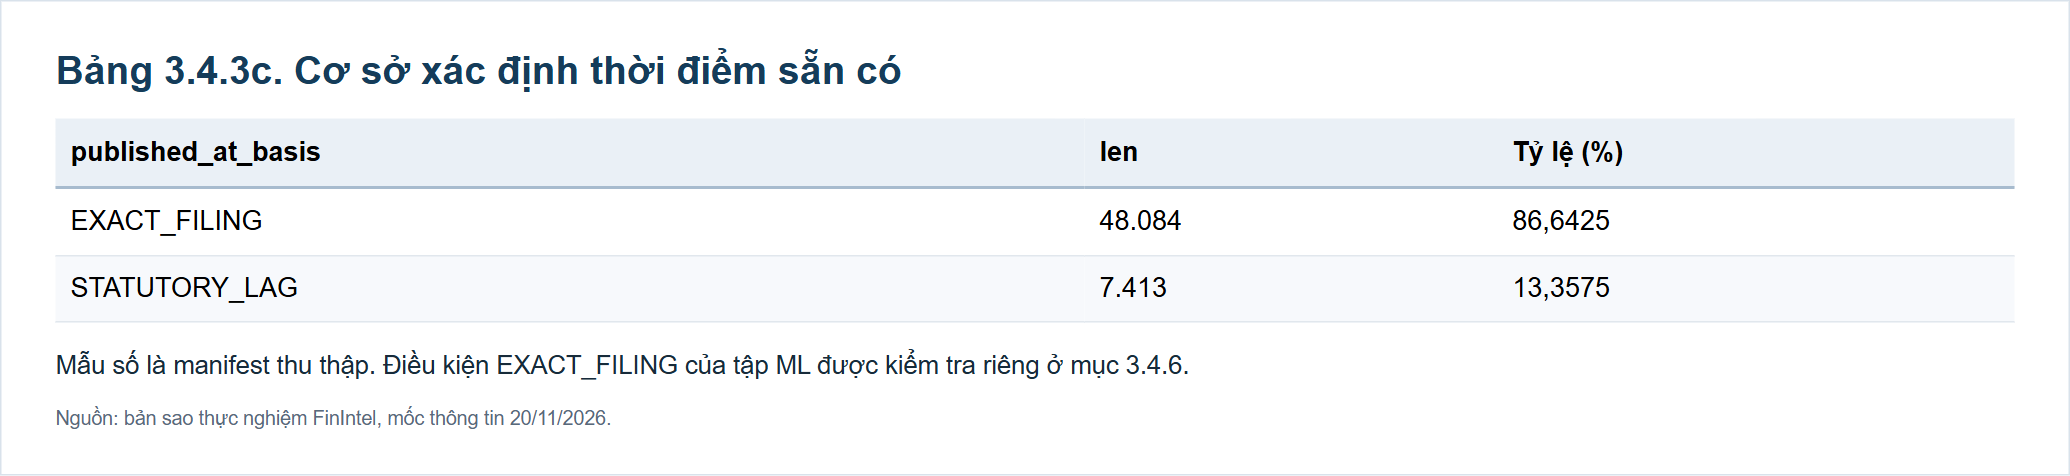

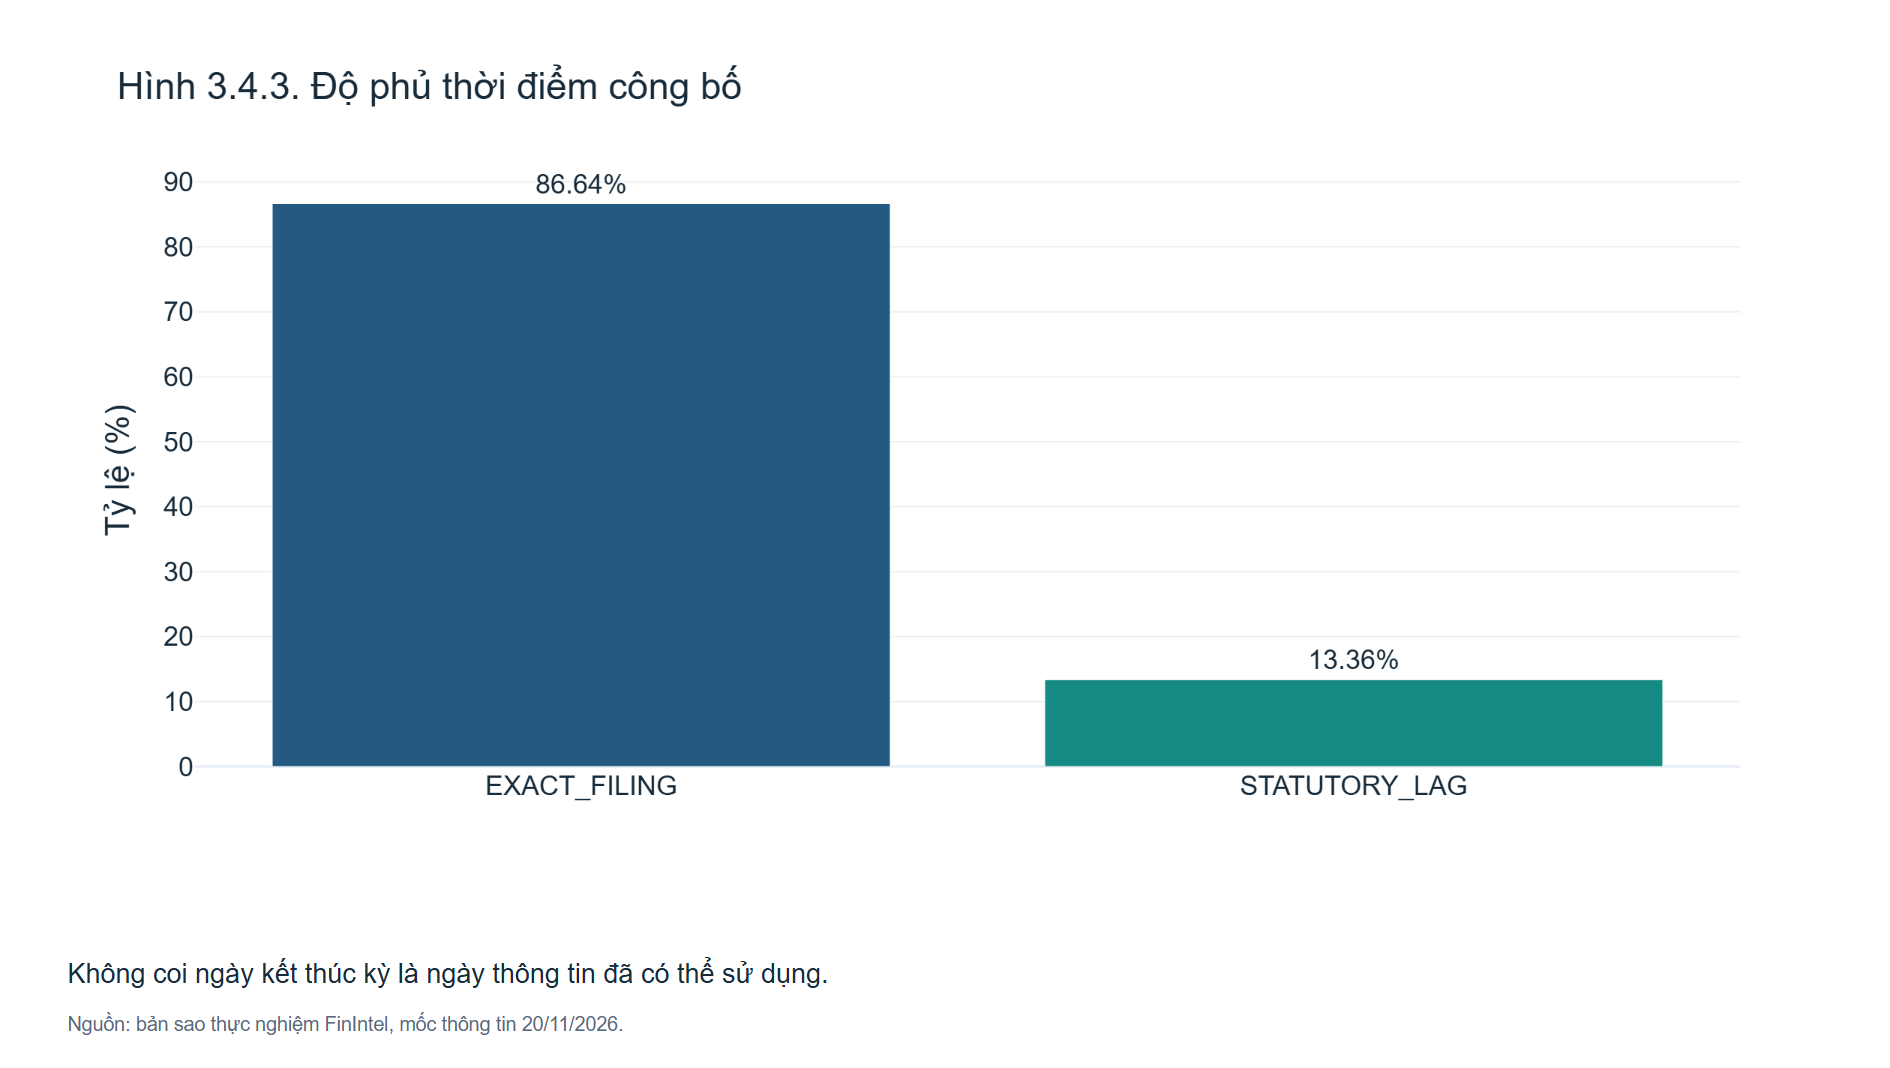

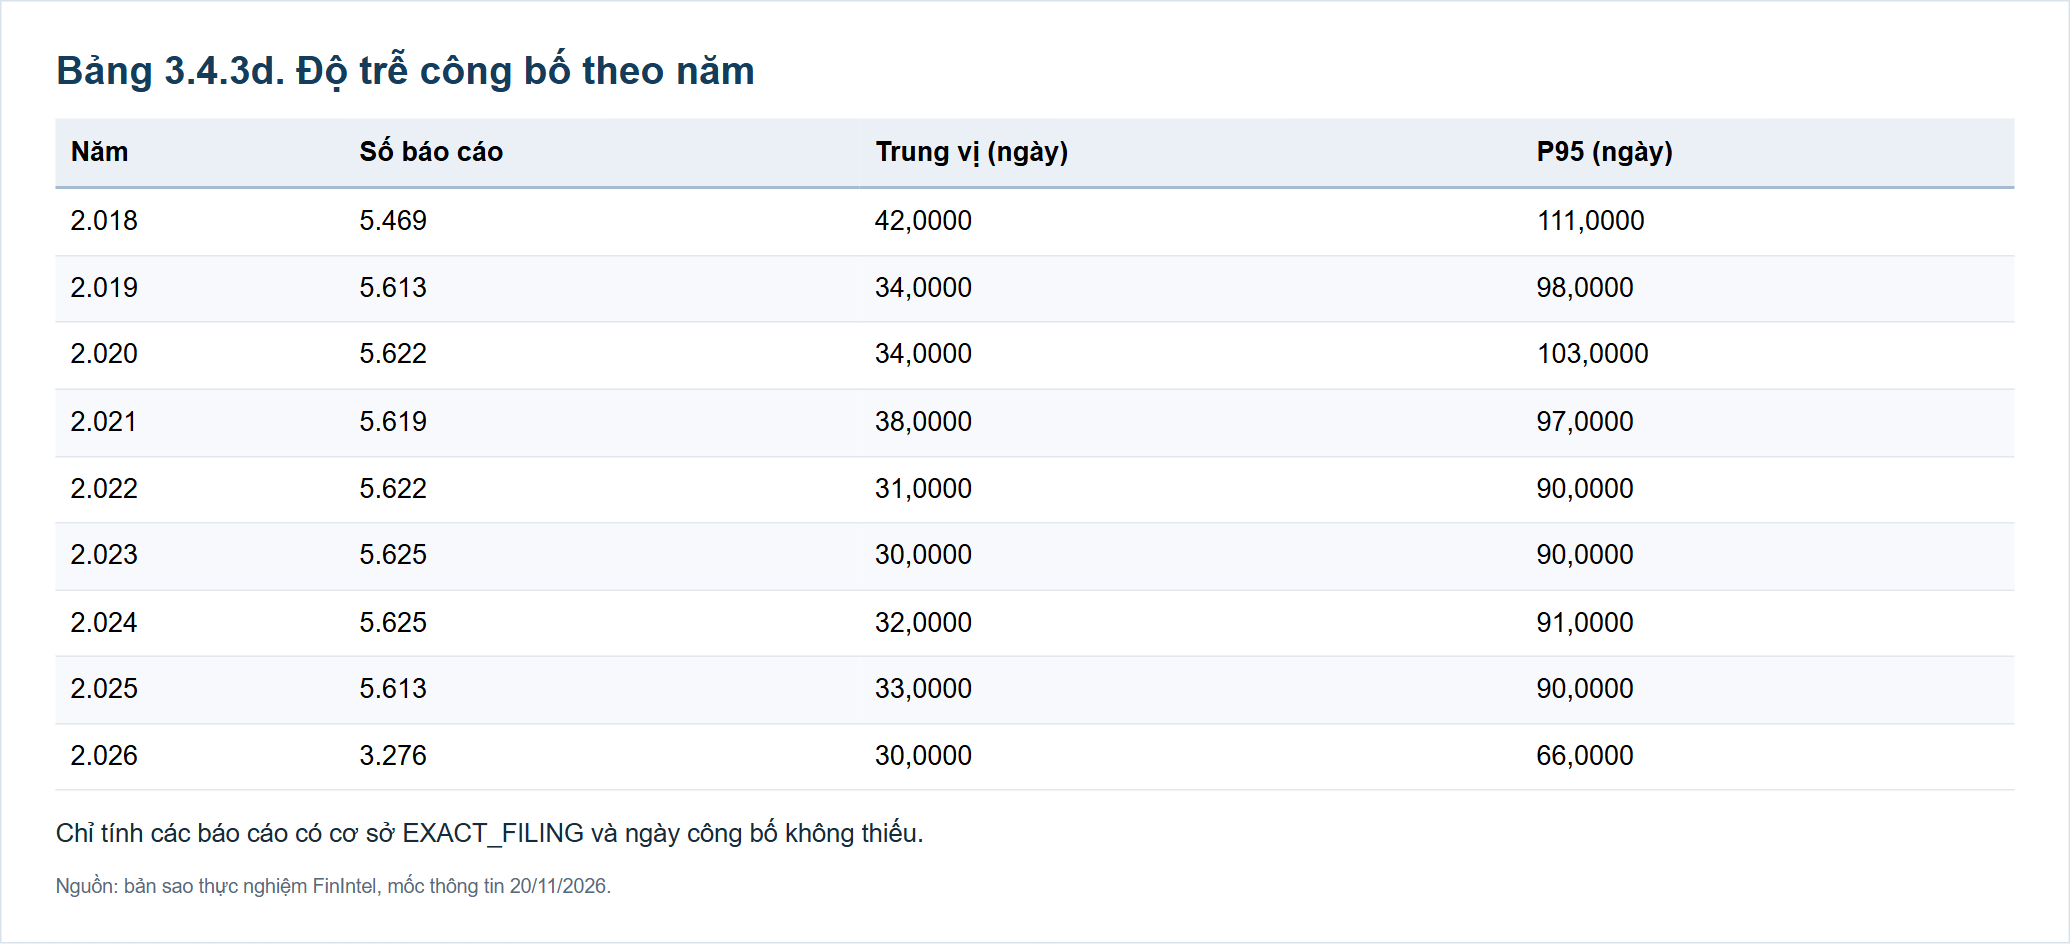

In [4]:
revision_key = [
    "source_provider",
    "issuer_id",
    "statement_type",
    "statement_scope",
    "period_type",
    "period_end_date",
]
revision_groups = manifest.group_by(revision_key).agg(
    pl.len().alias("Số phiên bản"),
    pl.col("revision_no").max().alias("Revision lớn nhất"),
)
revision_dist = manifest.group_by("revision_reason").len().sort("len", descending=True)
show_table(
    "Bảng 3.4.3a. Lịch sử phiên bản báo cáo",
    revision_dist,
    f"Có {revision_groups.filter(pl.col('Số phiên bản') > 1).height:,} nhóm báo cáo có nhiều hơn một phiên bản. Khóa nhóm có xét loại và phạm vi báo cáo.",
)
revised = revision_groups.filter(pl.col("Số phiên bản") > 1).sort(
    "Số phiên bản", descending=True
)
if revised.height:
    k = revised.row(0, named=True)
    expr = pl.all_horizontal(*(pl.col(c) == k[c] for c in revision_key))
    history = (
        manifest.filter(expr)
        .sort("revision_no")
        .select(
            "ticker_at_filing",
            "statement_type",
            "period_end_date",
            "revision_no",
            "revision_reason",
            "audit_status",
            "published_at",
            "effective_available_at",
        )
    )
    show_table(
        "Bảng 3.4.3b. Một lịch sử phiên bản thực tế",
        history,
        "Ví dụ được chọn từ nhóm có nhiều phiên bản trong dữ liệu, giữ nguyên mọi phiên bản.",
    )
else:
    show_table(
        "Bảng 3.4.3b. Kiểm tra phiên bản điều chỉnh trong tập dữ liệu",
        [
            {"Chỉ tiêu": "Nhóm báo cáo có nhiều phiên bản", "Kết quả": 0},
            {
                "Chỉ tiêu": "Revision lớn nhất trong manifest",
                "Kết quả": manifest["revision_no"].max(),
            },
        ],
        "Trong bản dữ liệu được kiểm tra chưa ghi nhận nhóm báo cáo có nhiều phiên bản. Kết quả này chỉ mô tả tập đang có; khả năng lưu lịch sử của hệ thống không thay thế bằng chứng dữ liệu điều chỉnh thực tế.",
    )
disclosure = (
    manifest.group_by("published_at_basis")
    .len()
    .with_columns((pl.col("len") / manifest.height * 100).alias("Tỷ lệ (%)"))
    .sort("len", descending=True)
)
show_table(
    "Bảng 3.4.3c. Cơ sở xác định thời điểm sẵn có",
    disclosure,
    "Mẫu số là manifest thu thập. Điều kiện EXACT_FILING của tập ML được kiểm tra riêng ở mục 3.4.6.",
)
bar(
    "Hình 3.4.3. Độ phủ thời điểm công bố",
    disclosure["published_at_basis"].to_list(),
    disclosure["Tỷ lệ (%)"].to_list(),
    "Không coi ngày kết thúc kỳ là ngày thông tin đã có thể sử dụng.",
    percent=True,
)
lag = manifest.filter(
    (pl.col("published_at_basis") == "EXACT_FILING")
    & pl.col("published_at").is_not_null()
).with_columns(
    (pl.col("published_at") - pl.col("period_end_date"))
    .dt.total_days()
    .alias("Độ trễ (ngày)")
)
lag_year = (
    lag.group_by(pl.col("period_end_date").dt.year().alias("Năm"))
    .agg(
        pl.len().alias("Số báo cáo"),
        pl.col("Độ trễ (ngày)").median().alias("Trung vị (ngày)"),
        pl.col("Độ trễ (ngày)").quantile(0.95).alias("P95 (ngày)"),
    )
    .sort("Năm")
)
show_table(
    "Bảng 3.4.3d. Độ trễ công bố theo năm",
    lag_year,
    "Chỉ tính các báo cáo có cơ sở EXACT_FILING và ngày công bố không thiếu.",
)


## 3.4.4. Tính toán chỉ số và xây dựng đặc trưng

Chạy lại `prepare_periods`, `calculate_ratios`, `add_classical_scores` trên clean facts
tại mốc as_of. TTM, phạm vi báo cáo, điều kiện mẫu số và taxonomy dùng đúng hàm
nghiệp vụ. Việc bù thiếu và chuẩn hóa đặc trưng ML chỉ diễn ra sau khi chia tập.


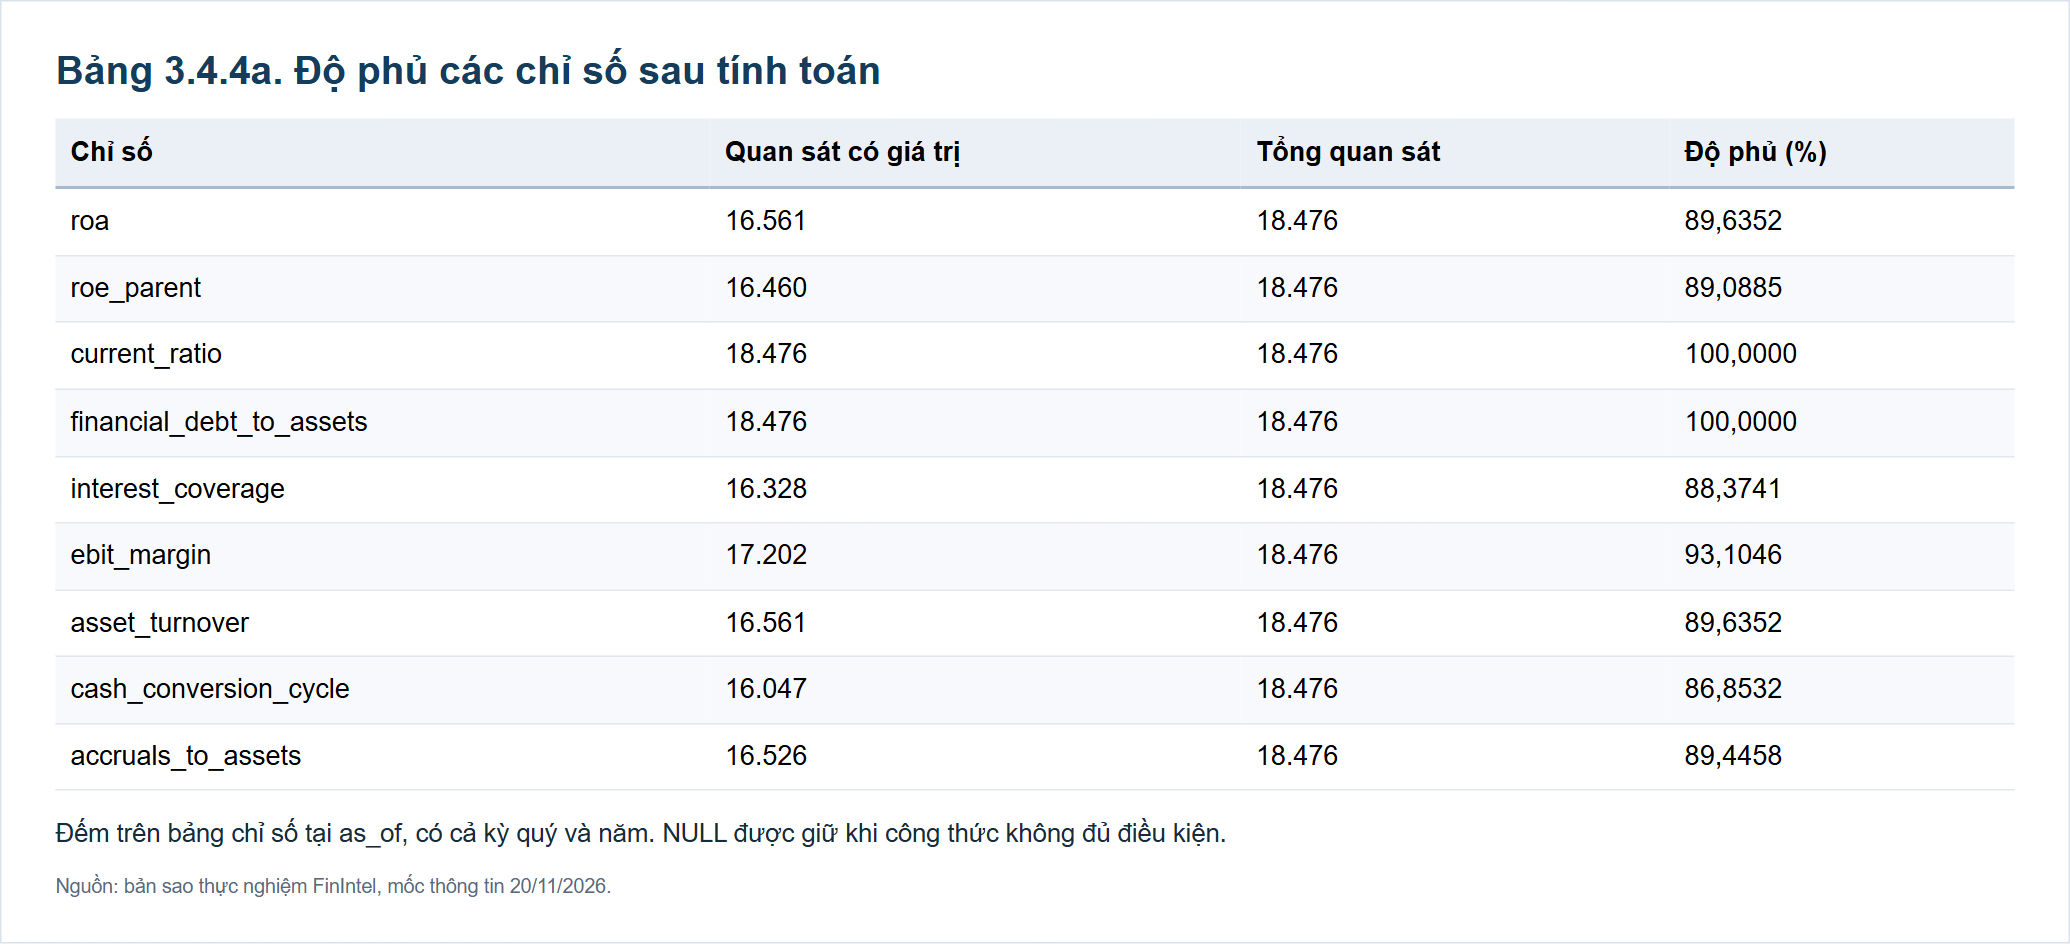

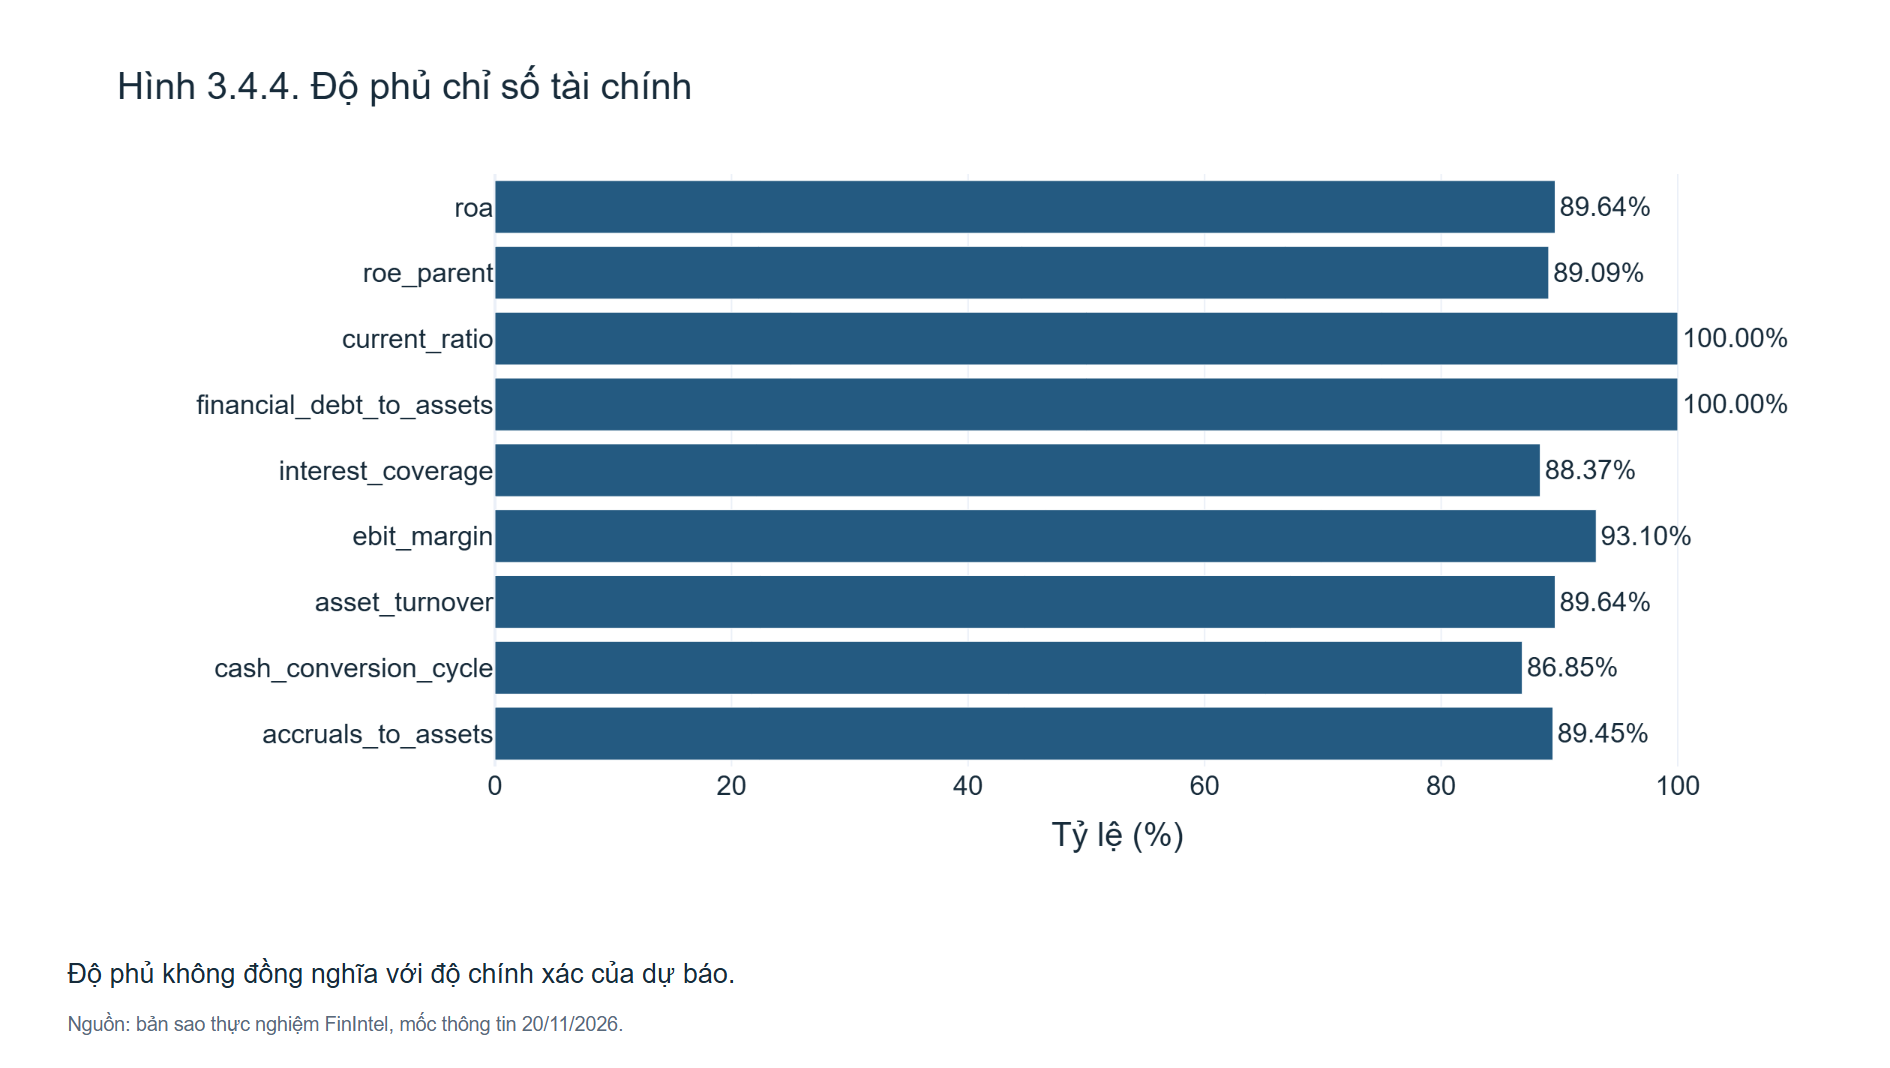

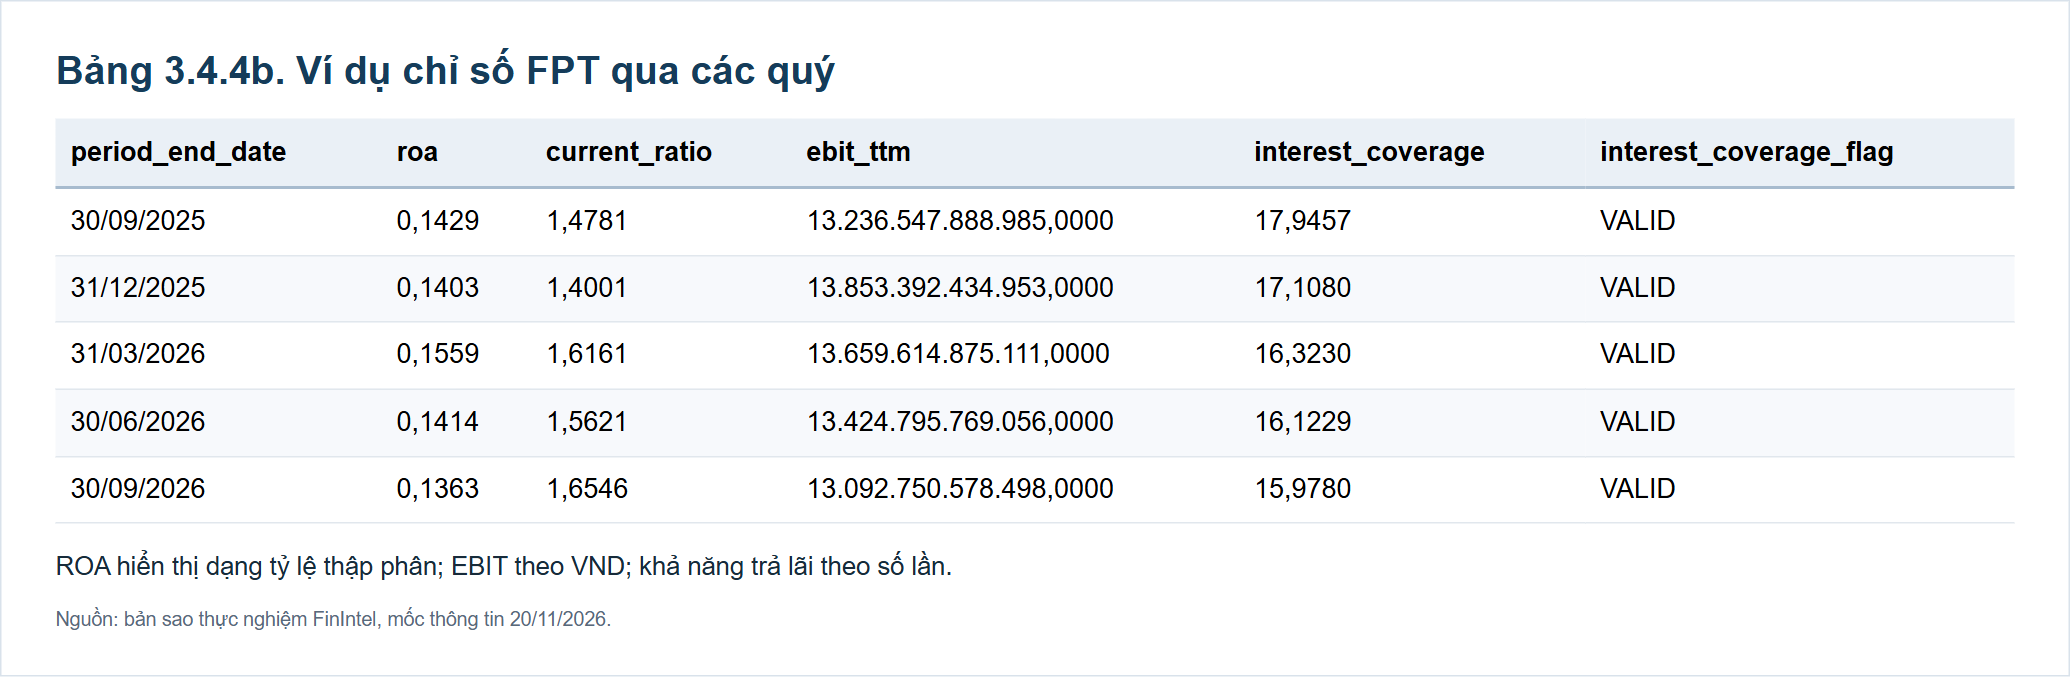

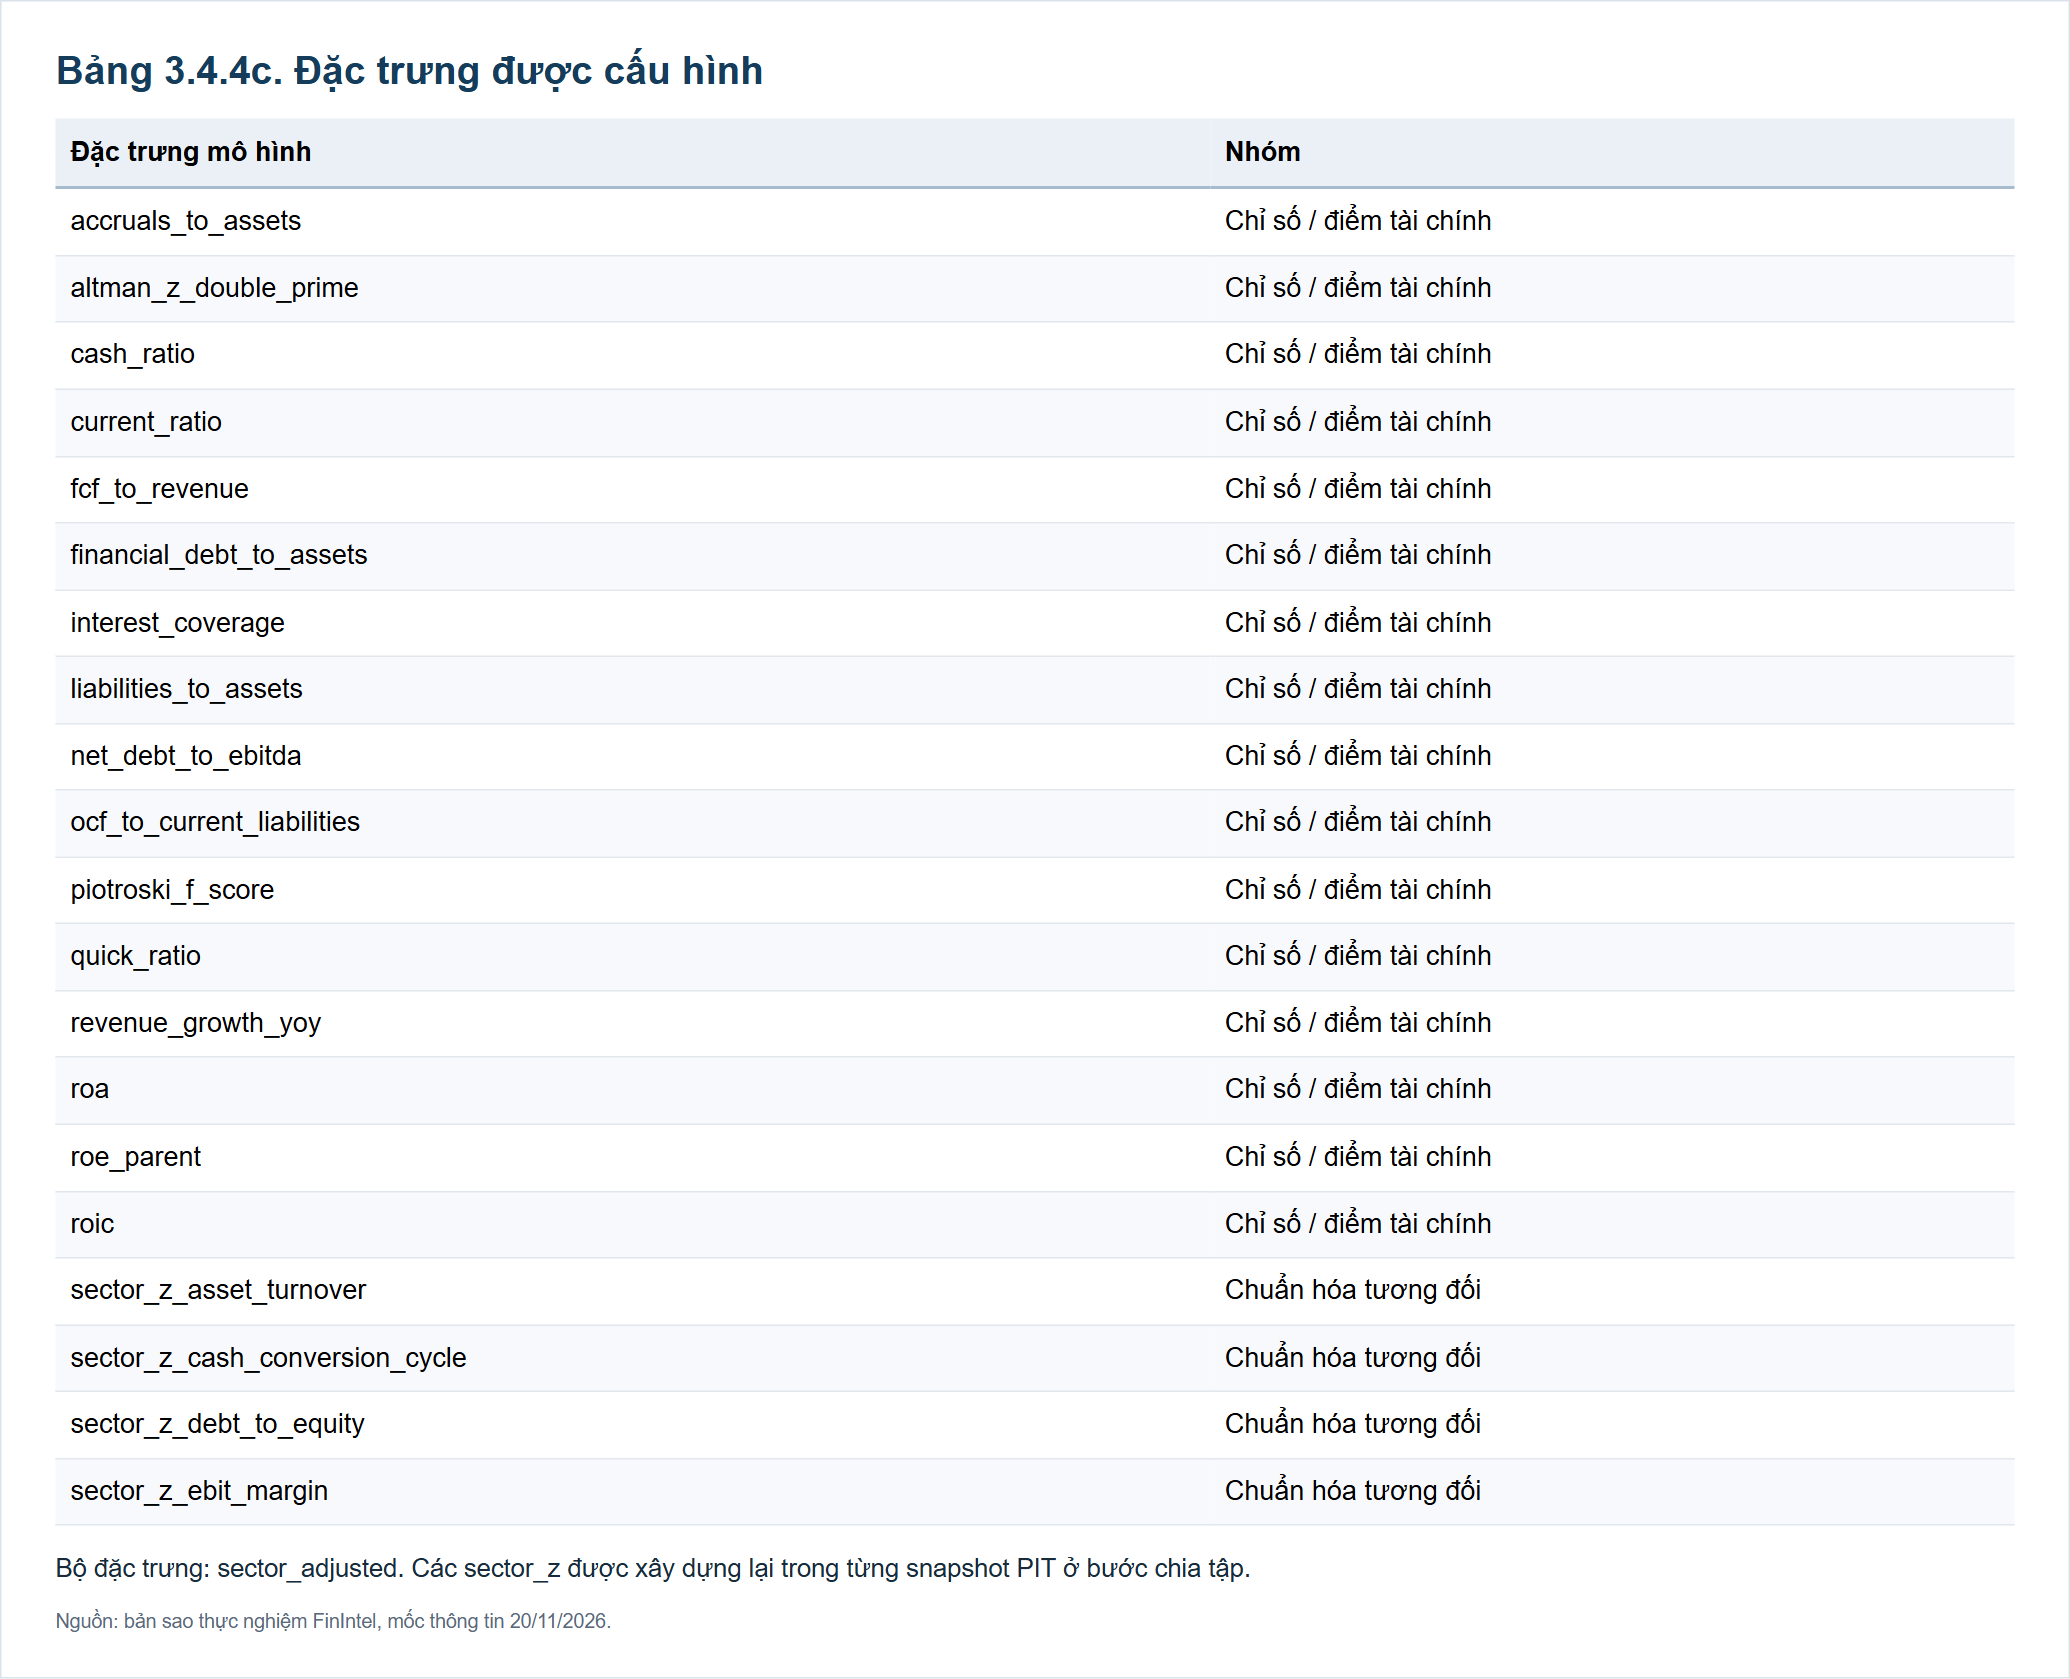

In [5]:
periods = prepare_periods(clean_facts, issuers, as_of=AS_OF, include_ml_inputs=True)
ratios = calculate_ratios(periods)
classical = add_classical_scores(ratios)
DISPLAY_METRICS = [
    "roa",
    "roe_parent",
    "current_ratio",
    "financial_debt_to_assets",
    "interest_coverage",
    "ebit_margin",
    "asset_turnover",
    "cash_conversion_cycle",
    "accruals_to_assets",
]
coverage = []
for name in DISPLAY_METRICS:
    coverage.append(
        {
            "Chỉ số": name,
            "Quan sát có giá trị": ratios[name].is_not_null().sum(),
            "Tổng quan sát": ratios.height,
            "Độ phủ (%)": 100 * ratios[name].is_not_null().sum() / ratios.height,
        }
    )
show_table(
    "Bảng 3.4.4a. Độ phủ các chỉ số sau tính toán",
    coverage,
    "Đếm trên bảng chỉ số tại as_of, có cả kỳ quý và năm. NULL được giữ khi công thức không đủ điều kiện.",
)
bar(
    "Hình 3.4.4. Độ phủ chỉ số tài chính",
    [r["Chỉ số"] for r in coverage],
    [r["Độ phủ (%)"] for r in coverage],
    "Độ phủ không đồng nghĩa với độ chính xác của dự báo.",
    horizontal=True,
    percent=True,
)
fpt_ratios = (
    ratios.filter(
        (pl.col("ticker") == "FPT")
        & (pl.col("statement_scope") == SCOPE)
        & (pl.col("period_type") == "QUARTER")
    )
    .sort("period_end_date")
    .tail(5)
)
show_table(
    "Bảng 3.4.4b. Ví dụ chỉ số FPT qua các quý",
    fpt_ratios.select(
        "period_end_date",
        "roa",
        "current_ratio",
        "ebit_ttm",
        "interest_coverage",
        "interest_coverage_flag",
    ),
    "ROA hiển thị dạng tỷ lệ thập phân; EBIT theo VND; khả năng trả lãi theo số lần.",
)
feature_table = pl.DataFrame(
    {
        "Đặc trưng mô hình": list(FEATURES),
        "Nhóm": [
            "Chuẩn hóa tương đối"
            if n.startswith("sector_z_")
            else "Chỉ số / điểm tài chính"
            for n in FEATURES
        ],
    }
)
show_table(
    "Bảng 3.4.4c. Đặc trưng được cấu hình",
    feature_table,
    f"Bộ đặc trưng: {RUN_MANIFEST['feature_set']}. Các sector_z được xây dựng lại trong từng snapshot PIT ở bước chia tập.",
    limit=30,
)


## 3.4.5. Xây dựng nhãn mục tiêu

Sử dụng `build_distress_targets(mode='FUNDAMENTAL_DISTRESS')` với chân trời bốn quý.
Nhãn 1 phản ánh quy tắc tài chính của đề tài, không phải xác nhận phá sản pháp lý.
Nhãn NULL được giữ riêng khi chưa đủ dữ liệu hoặc điều kiện xác định nhãn.
Thống kê ở mục này là toàn bộ nhãn tại as_of, chưa phải tập Train/Validation/Test.


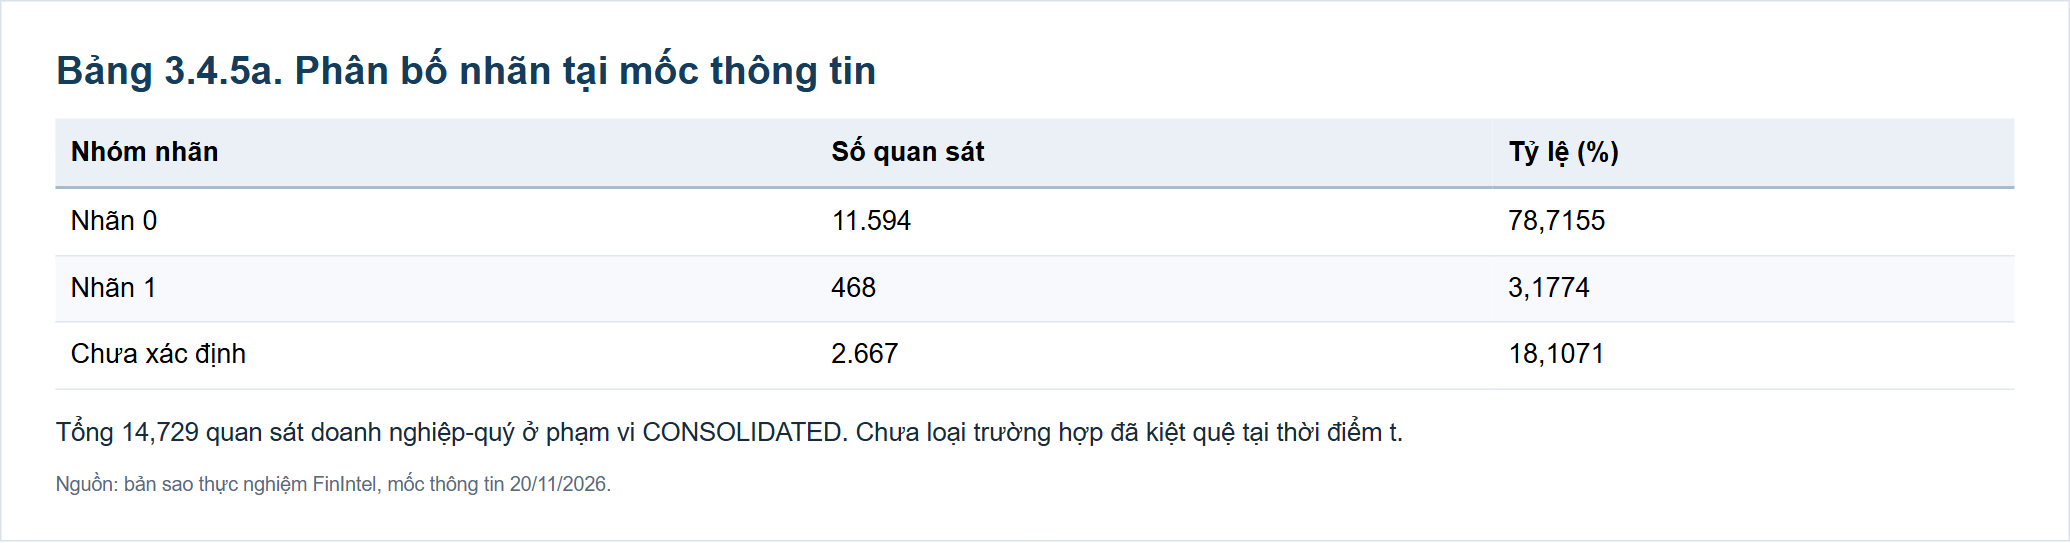

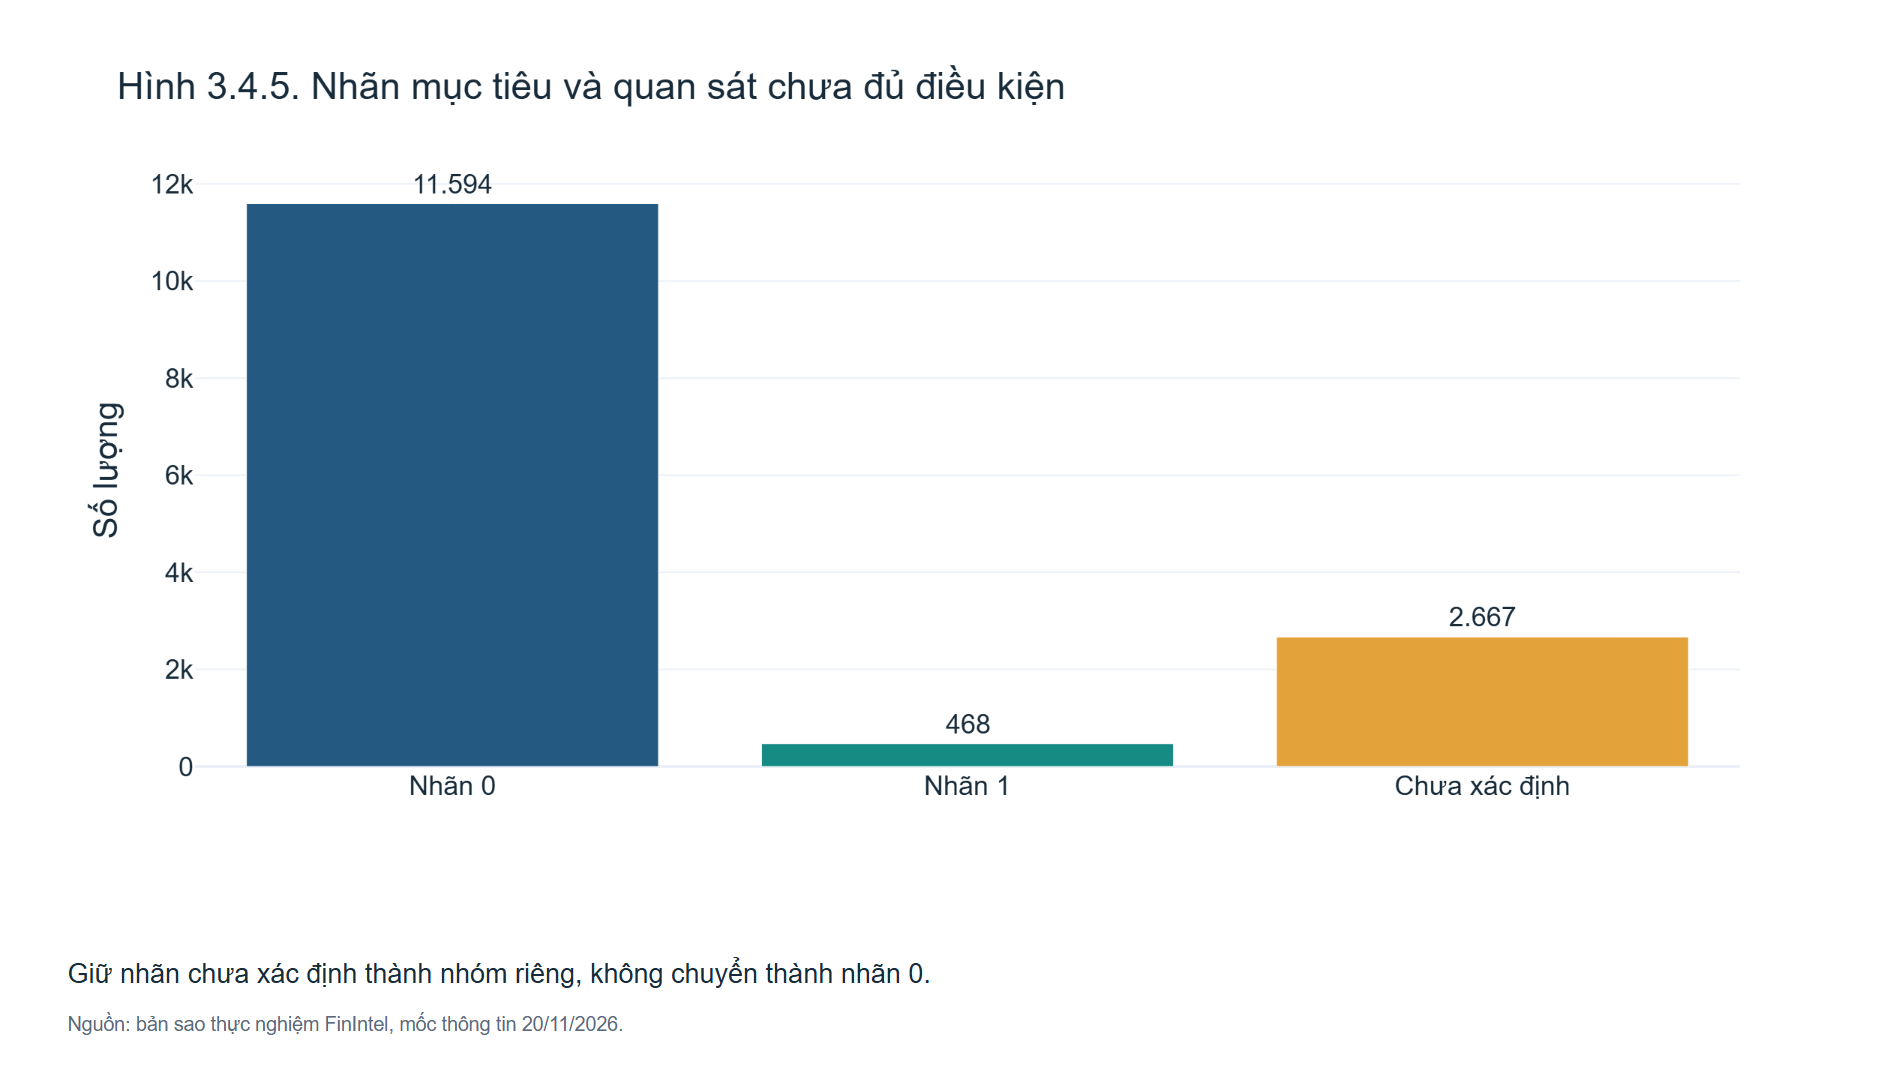

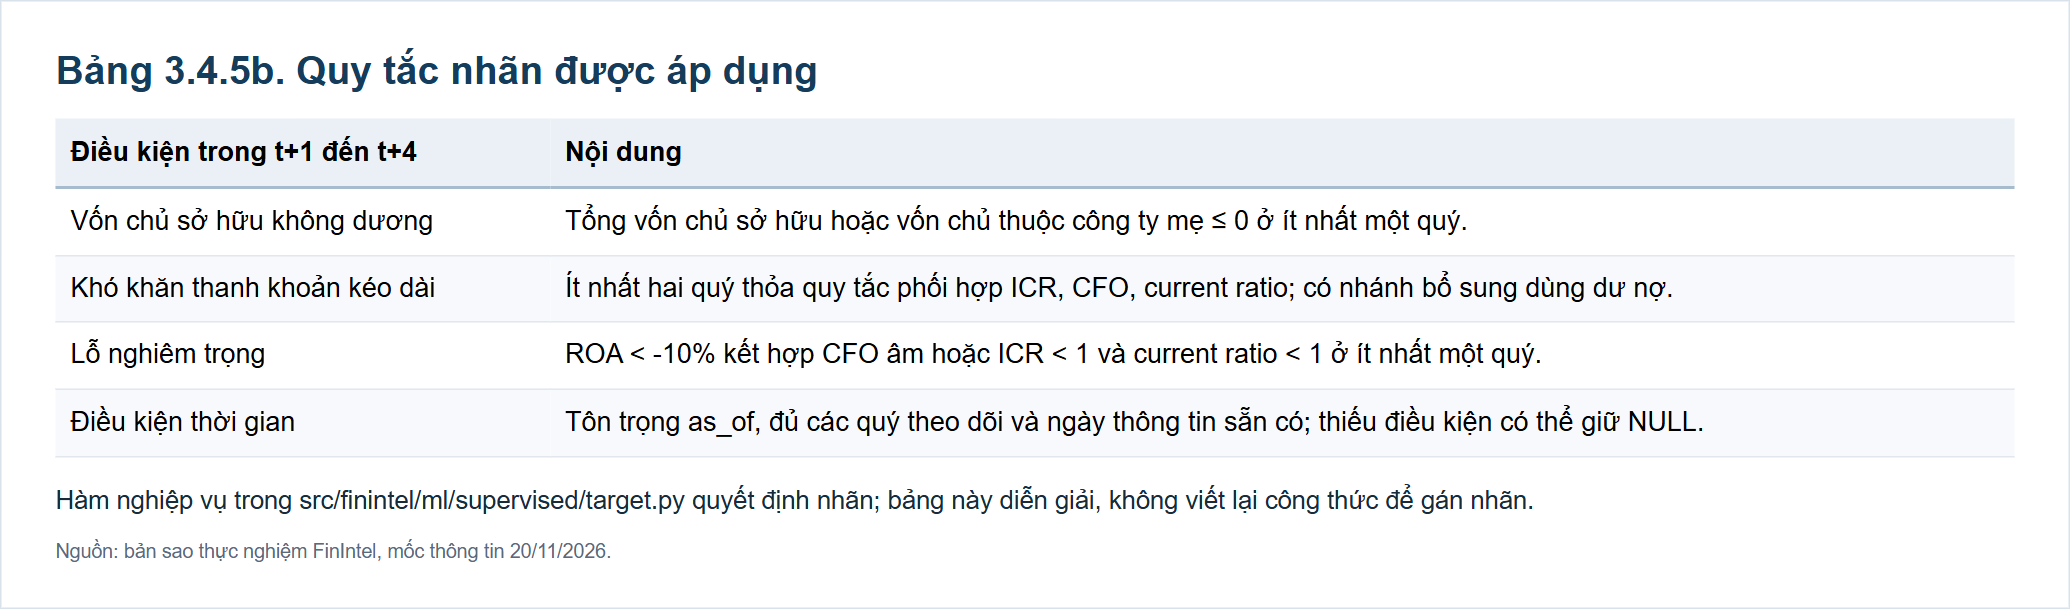

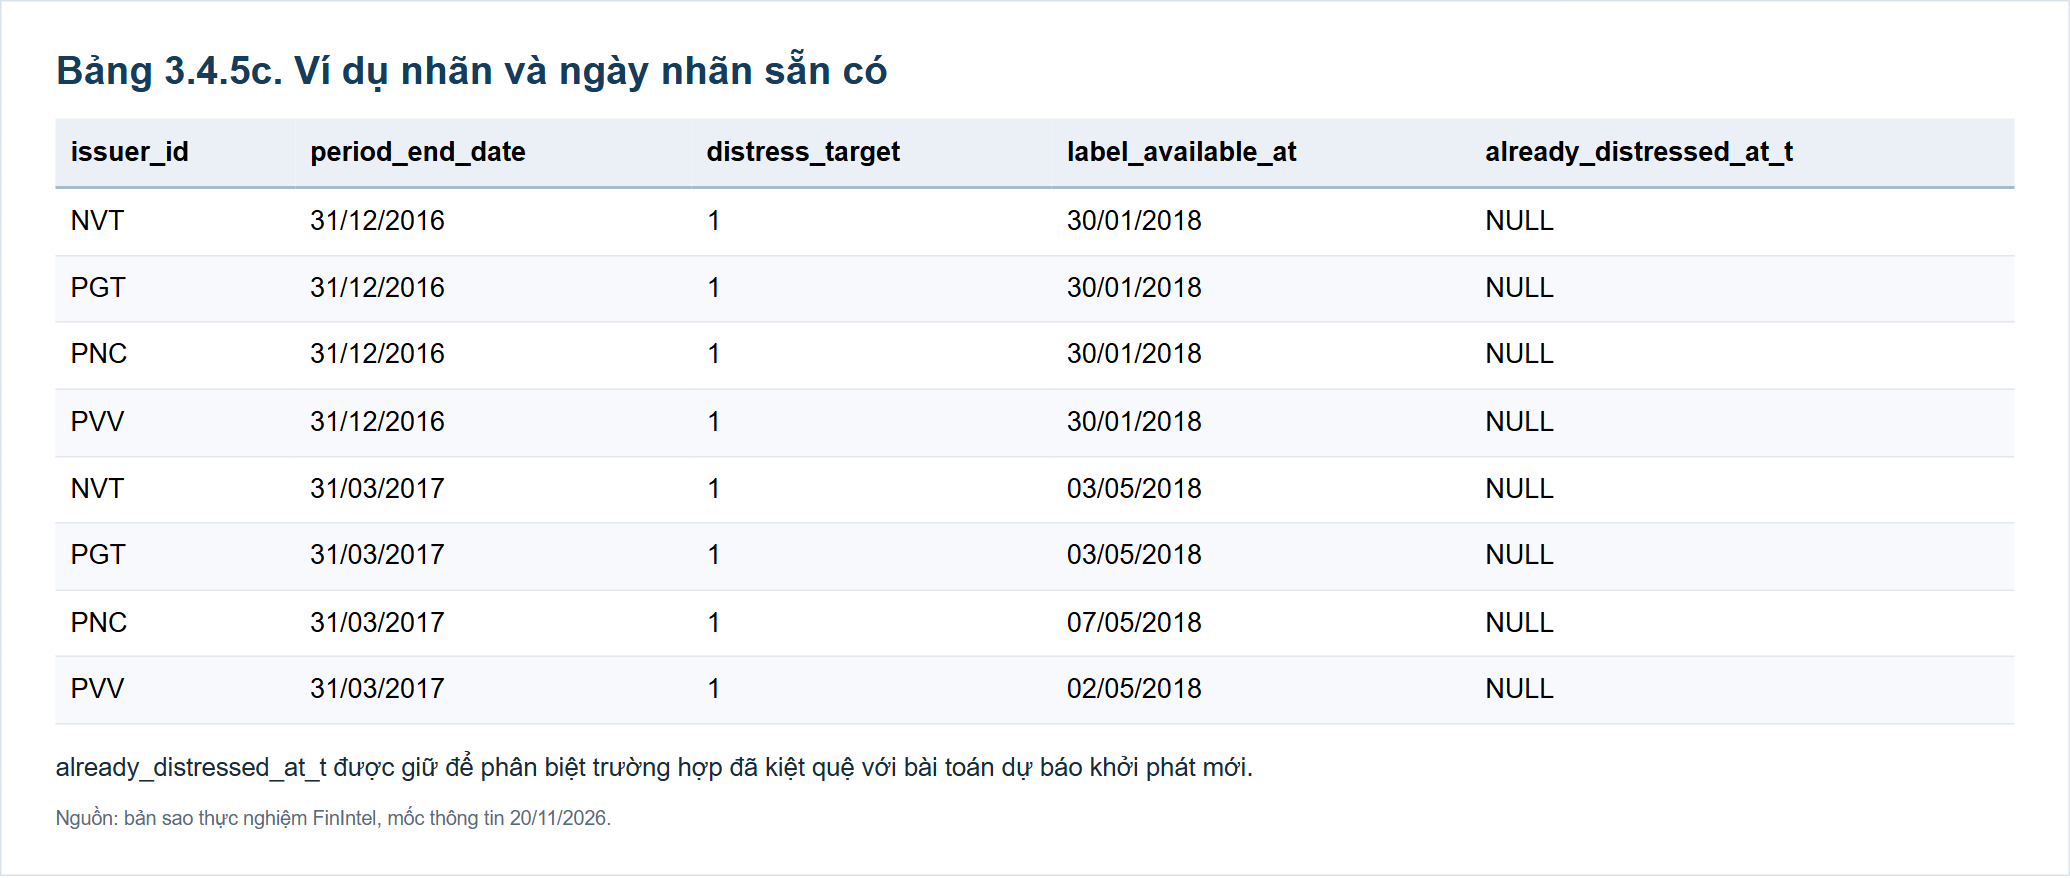

In [6]:
labels = build_distress_targets(
    classical.filter(pl.col("statement_scope") == SCOPE),
    mode=RUN_MANIFEST["target_mode"],
    as_of=AS_OF,
)
label_counts = []
for value, name in [(0, "Nhãn 0"), (1, "Nhãn 1"), (None, "Chưa xác định")]:
    count = labels.filter(
        pl.col("distress_target").is_null()
        if value is None
        else pl.col("distress_target") == value
    ).height
    label_counts.append(
        {
            "Nhóm nhãn": name,
            "Số quan sát": count,
            "Tỷ lệ (%)": 100 * count / labels.height if labels.height else 0.0,
        }
    )
show_table(
    "Bảng 3.4.5a. Phân bố nhãn tại mốc thông tin",
    label_counts,
    f"Tổng {labels.height:,} quan sát doanh nghiệp-quý ở phạm vi {SCOPE}. Chưa loại trường hợp đã kiệt quệ tại thời điểm t.",
)
bar(
    "Hình 3.4.5. Nhãn mục tiêu và quan sát chưa đủ điều kiện",
    [r["Nhóm nhãn"] for r in label_counts],
    [r["Số quan sát"] for r in label_counts],
    "Giữ nhãn chưa xác định thành nhóm riêng, không chuyển thành nhãn 0.",
)
show_table(
    "Bảng 3.4.5b. Quy tắc nhãn được áp dụng",
    [
        {
            "Điều kiện trong t+1 đến t+4": "Vốn chủ sở hữu không dương",
            "Nội dung": "Tổng vốn chủ sở hữu hoặc vốn chủ thuộc công ty mẹ ≤ 0 ở ít nhất một quý.",
        },
        {
            "Điều kiện trong t+1 đến t+4": "Khó khăn thanh khoản kéo dài",
            "Nội dung": "Ít nhất hai quý thỏa quy tắc phối hợp ICR, CFO, current ratio; có nhánh bổ sung dùng dư nợ.",
        },
        {
            "Điều kiện trong t+1 đến t+4": "Lỗ nghiêm trọng",
            "Nội dung": "ROA < -10% kết hợp CFO âm hoặc ICR < 1 và current ratio < 1 ở ít nhất một quý.",
        },
        {
            "Điều kiện trong t+1 đến t+4": "Điều kiện thời gian",
            "Nội dung": "Tôn trọng as_of, đủ các quý theo dõi và ngày thông tin sẵn có; thiếu điều kiện có thể giữ NULL.",
        },
    ],
    "Hàm nghiệp vụ trong src/finintel/ml/supervised/target.py quyết định nhãn; bảng này diễn giải, không viết lại công thức để gán nhãn.",
)
show_table(
    "Bảng 3.4.5c. Ví dụ nhãn và ngày nhãn sẵn có",
    labels.filter(pl.col("distress_target") == 1)
    .select(
        "issuer_id",
        "period_end_date",
        "distress_target",
        "label_available_at",
        "already_distressed_at_t",
    )
    .sort("period_end_date")
    .head(8),
    "already_distressed_at_t được giữ để phân biệt trường hợp đã kiệt quệ với bài toán dự báo khởi phát mới.",
)


## 3.4.6. Phân chia tập huấn luyện, xác thực và kiểm thử

Sử dụng `build_pit_ml_splits` của dự án. Train được dựng tại validation_start,
Validation tại test_start, Test tại as_of. Ngoài ngày quan sát, ngày đặc trưng và
ngày nhãn sẵn có phải thỏa điều kiện từng biên. Chỉ dùng provenance EXACT_FILING.
Không chia ngẫu nhiên các dòng rồi báo cáo là kiểm thử theo thời gian.

Các tập sau chia PIT được phân biệt với tập so sánh mô hình khởi phát mới:
tập sau loại already_distressed_at_t và loại Altman thiếu có mẫu số nhỏ hơn.


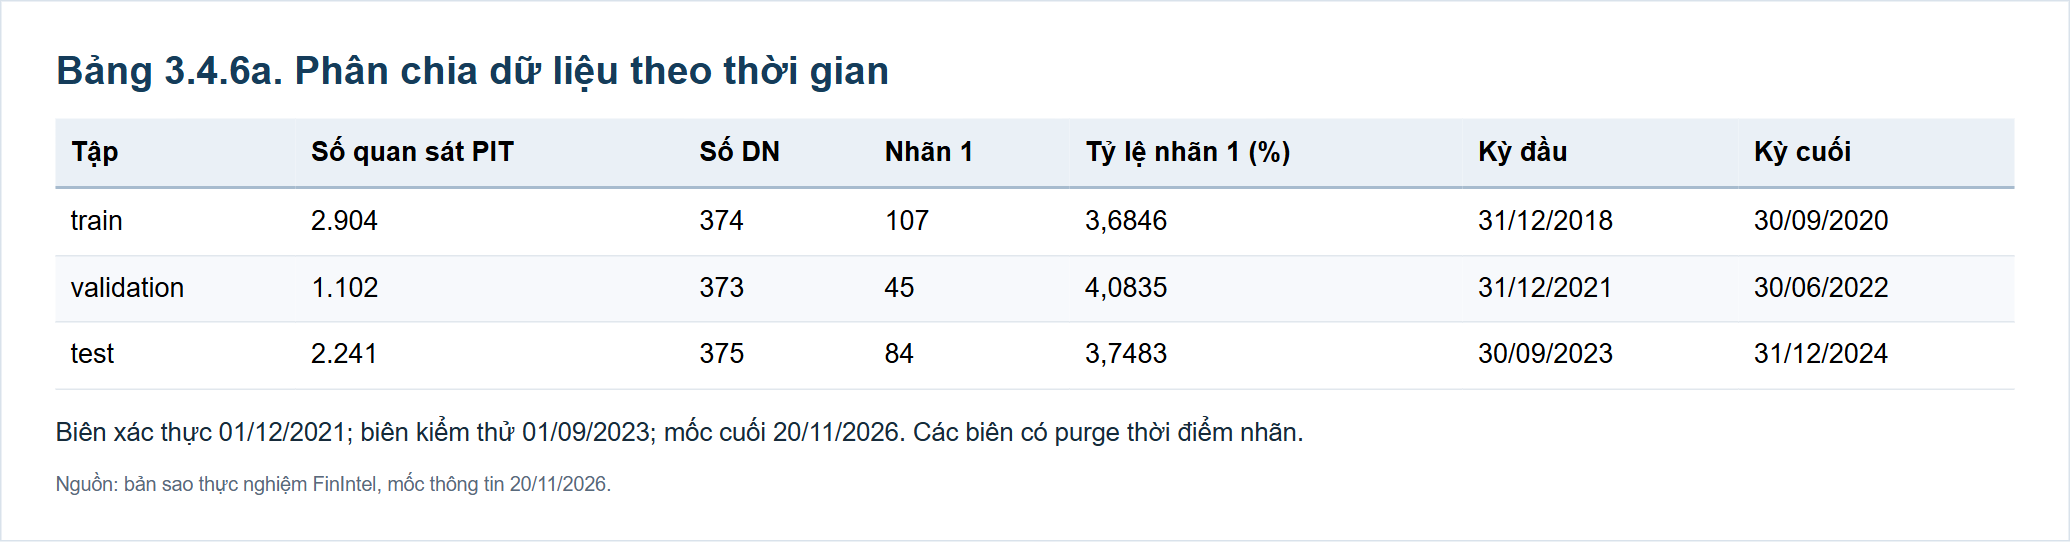

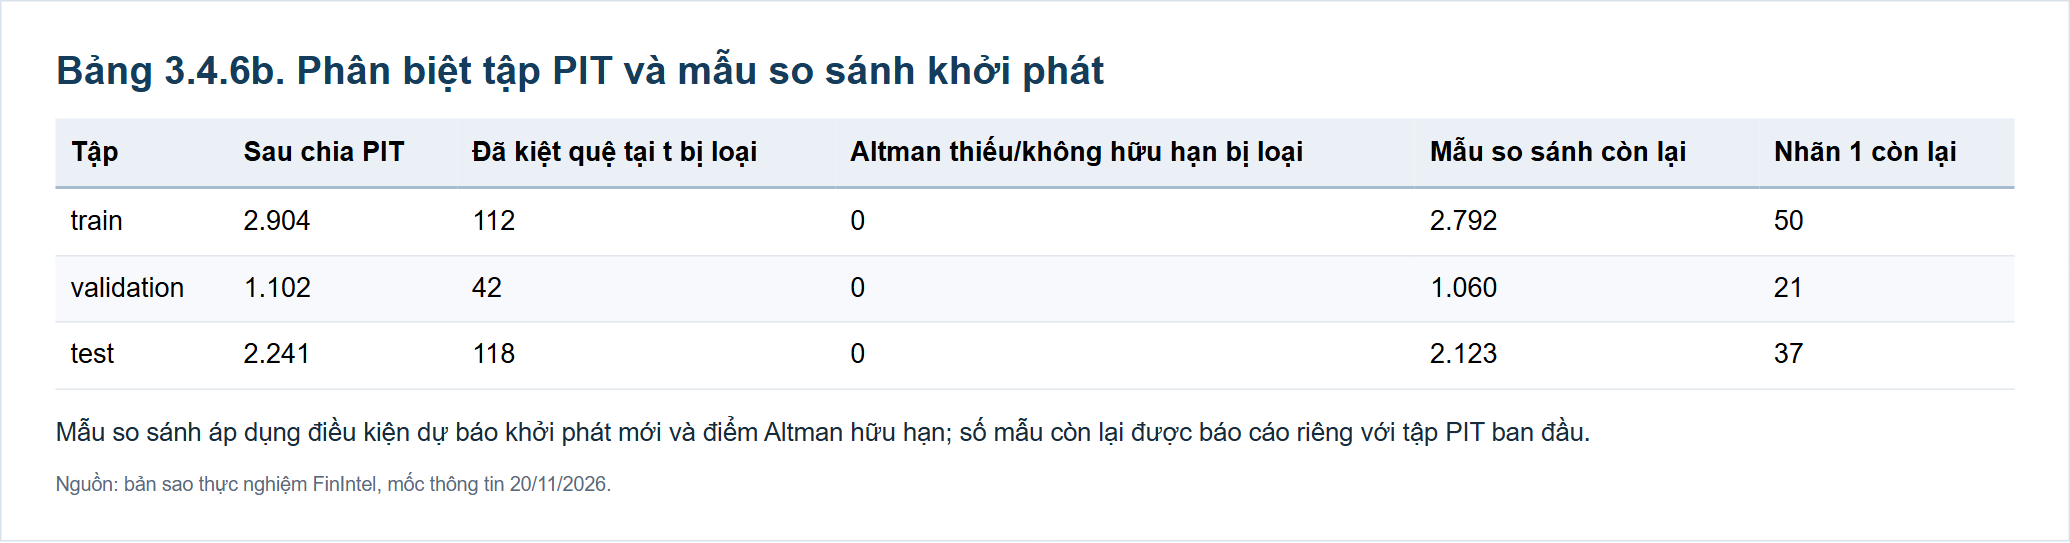

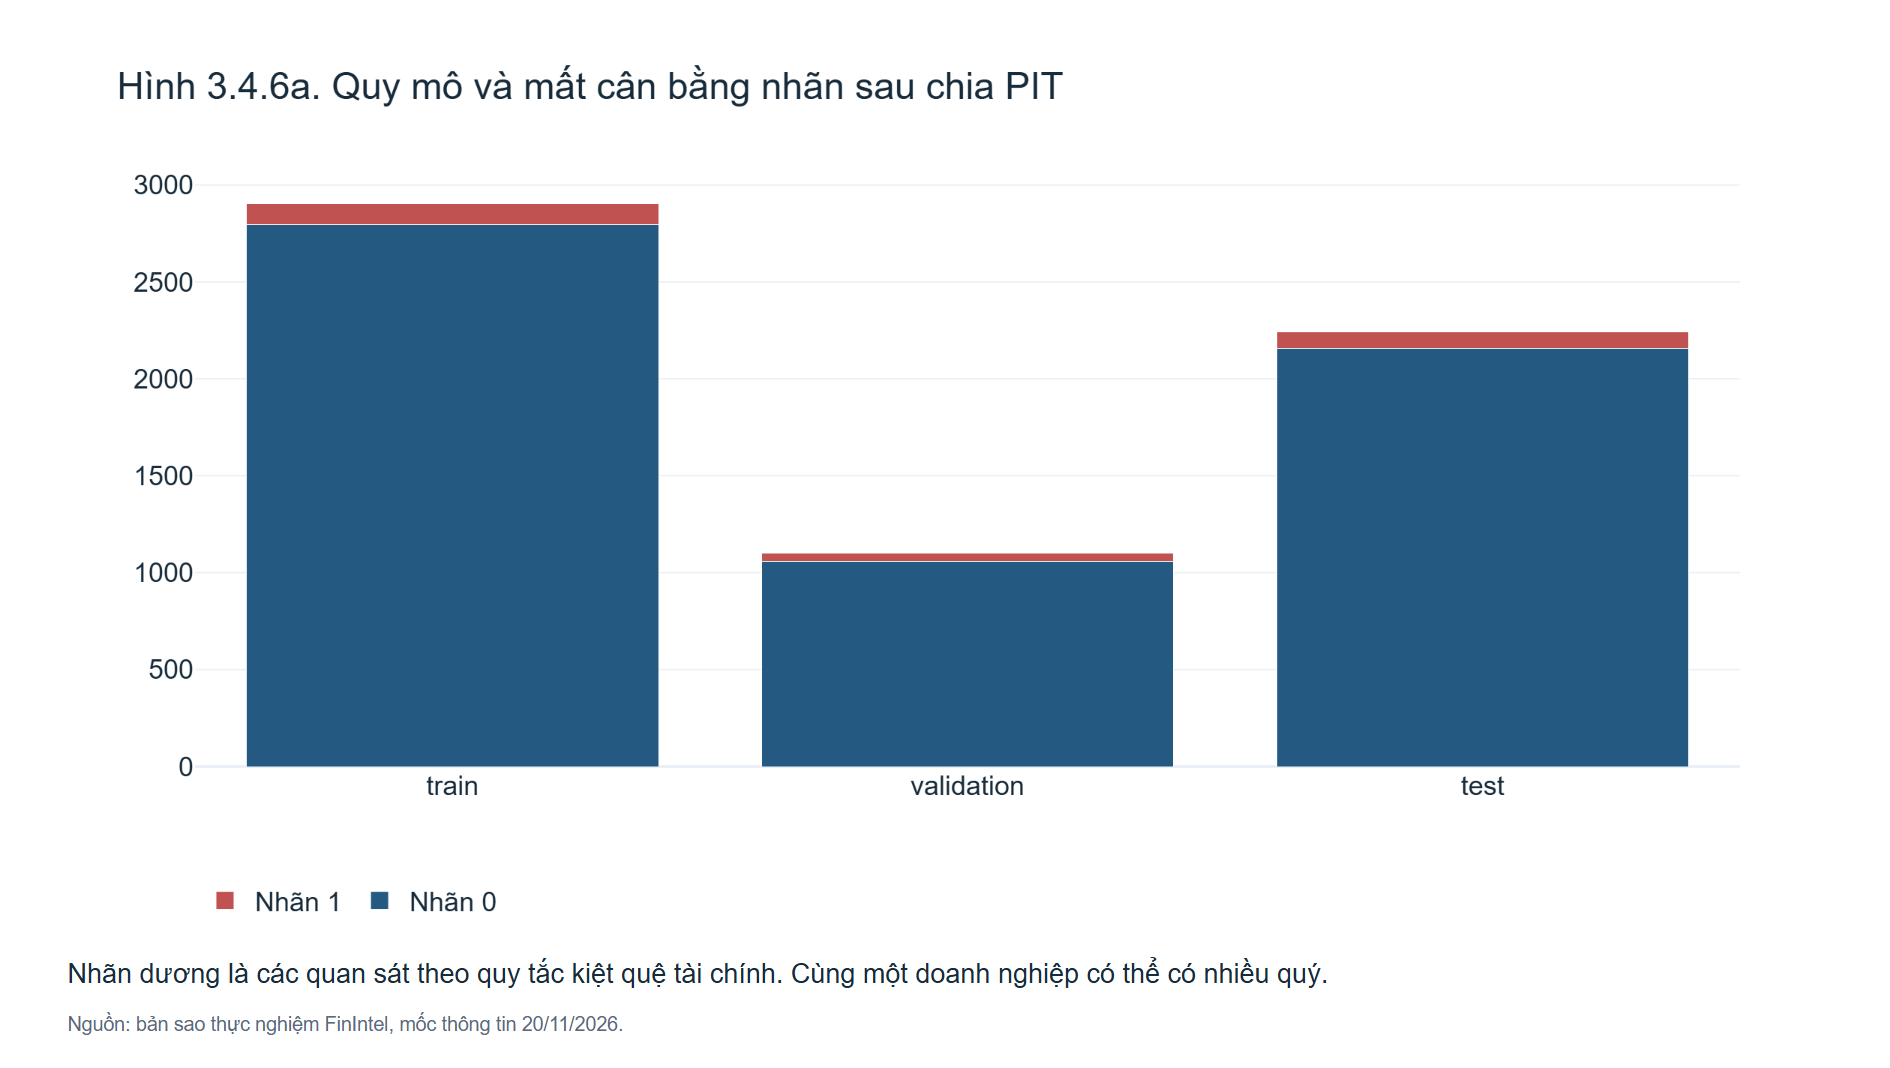

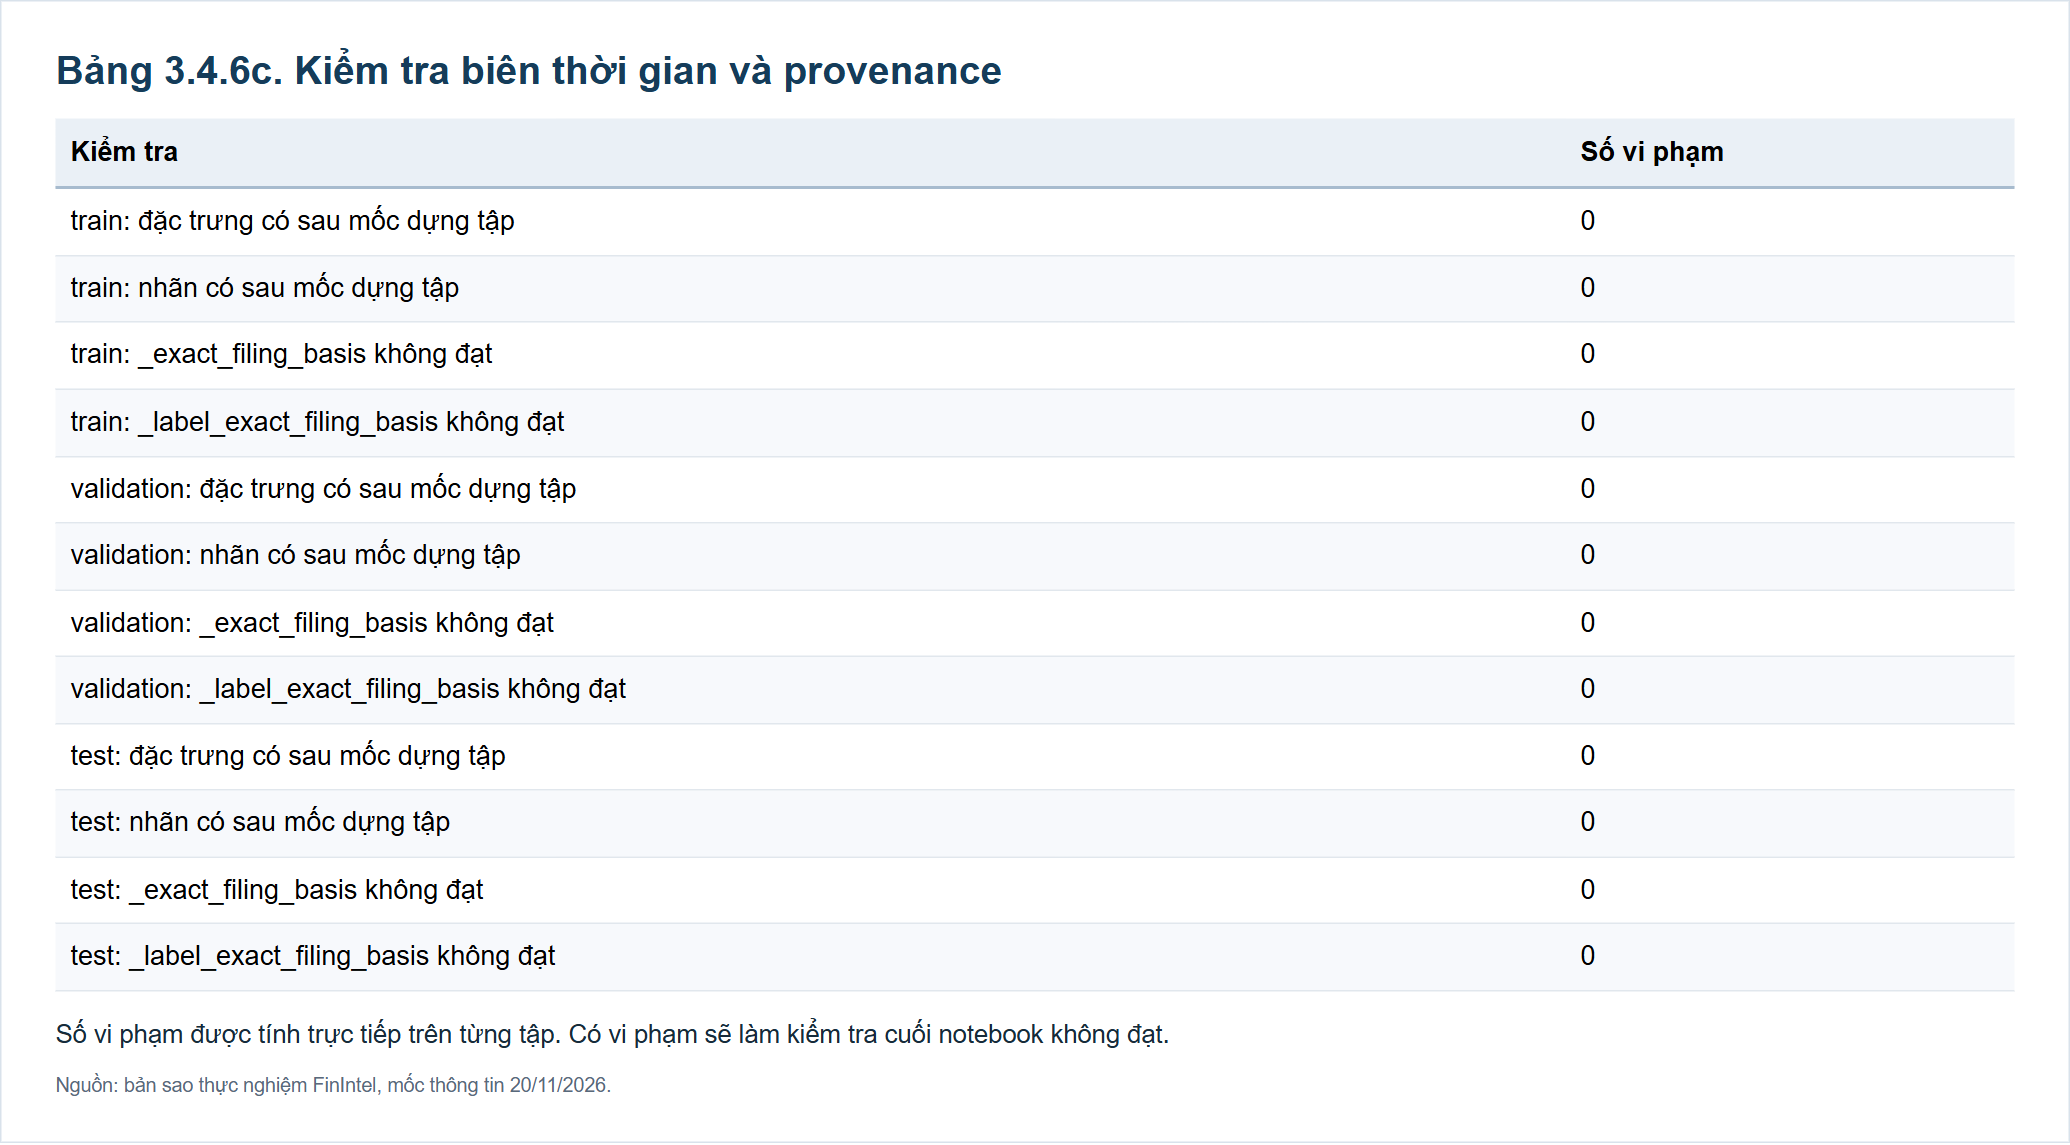

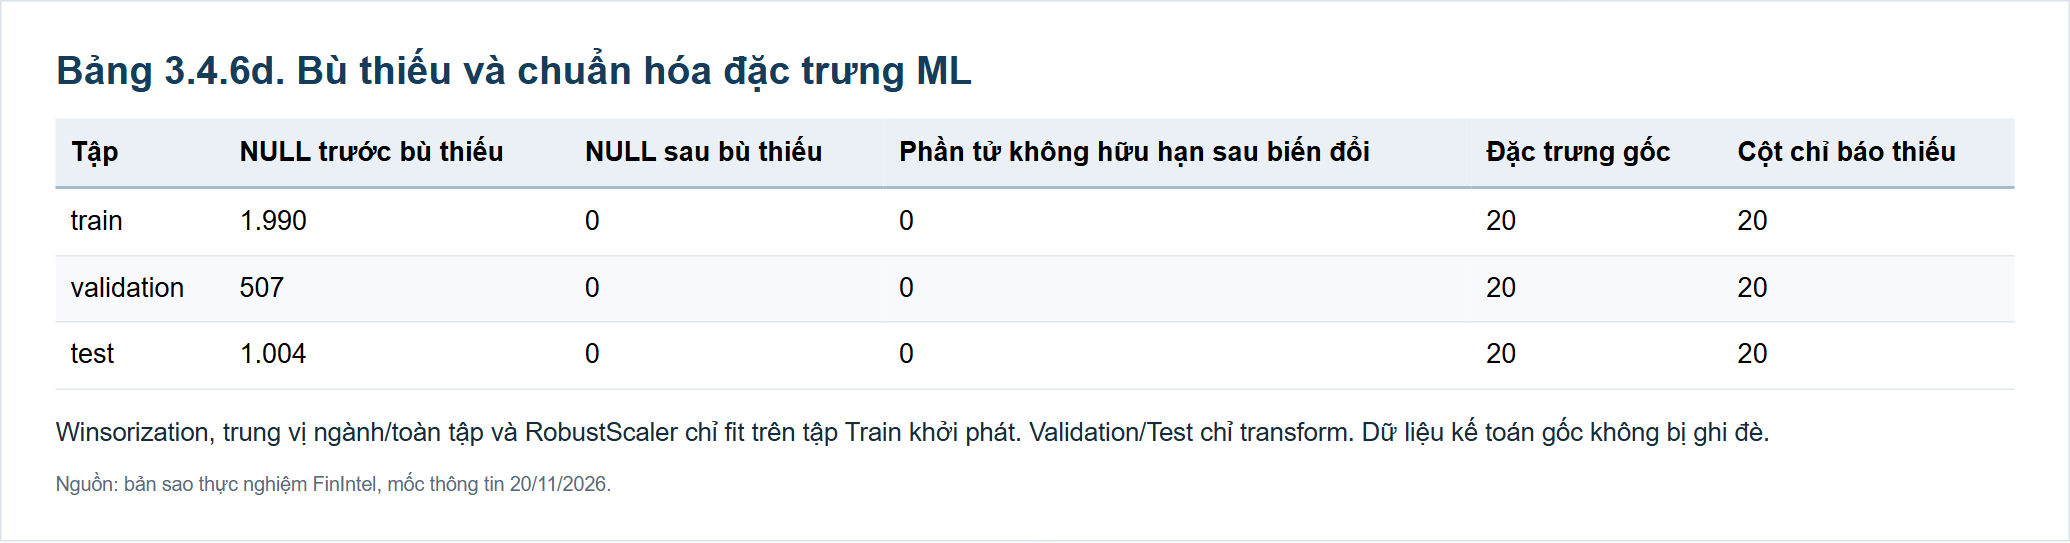

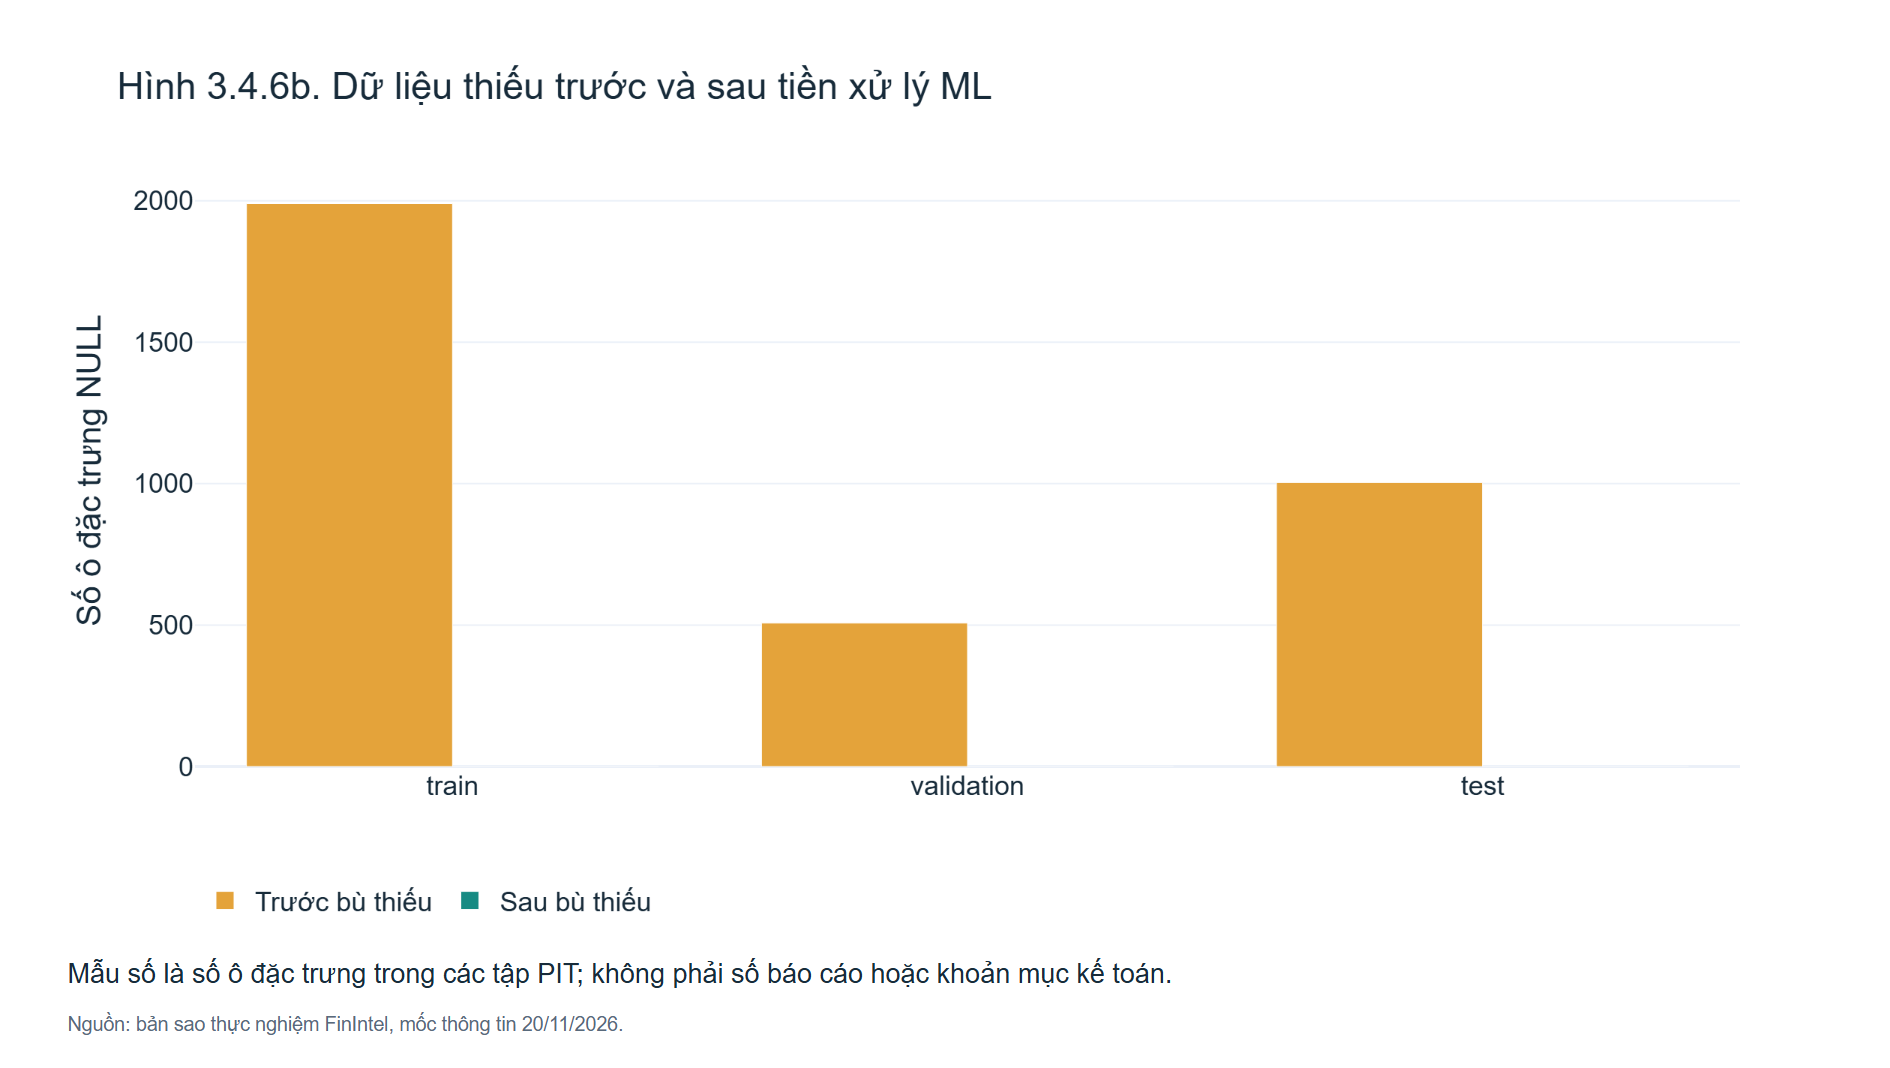

In [7]:
splits = build_pit_ml_splits(
    clean_facts,
    issuers,
    validation_start=VALIDATION_START,
    test_start=TEST_START,
    as_of=AS_OF,
    require_exact_filing=True,
    statement_scope=SCOPE,
    taxonomy_version=RUN_MANIFEST["taxonomy_version"],
    target_mode=RUN_MANIFEST["target_mode"],
    precomputed_as_of_scored=classical,
)
split_rows = []
comparisons = {}
checks = []
for name, frame in splits.items():
    first = frame["period_end_date"].min()
    last = frame["period_end_date"].max()
    pos = frame.filter(pl.col("distress_target") == 1).height
    split_rows.append(
        {
            "Tập": name,
            "Số quan sát PIT": frame.height,
            "Số DN": frame["issuer_id"].n_unique(),
            "Nhãn 1": pos,
            "Tỷ lệ nhãn 1 (%)": 100 * pos / frame.height if frame.height else 0.0,
            "Kỳ đầu": first,
            "Kỳ cuối": last,
        }
    )
    # Cùng tiêu chí chuẩn bị tập đánh giá trong train._prepare_eval_fold.
    incident = frame.filter(
        pl.col("distress_target").is_not_null()
        & pl.col("label_available_at").is_not_null()
        & ~pl.col("already_distressed_at_t").fill_null(True)
    )
    common = incident.filter(
        pl.col("altman_z_double_prime").is_not_null()
        & pl.col("altman_z_double_prime").is_finite()
    )
    comparisons[name] = {
        "Tập": name,
        "Sau chia PIT": frame.height,
        "Đã kiệt quệ tại t bị loại": frame.height - incident.height,
        "Altman thiếu/không hữu hạn bị loại": incident.height - common.height,
        "Mẫu so sánh còn lại": common.height,
        "Nhãn 1 còn lại": common.filter(pl.col("distress_target") == 1).height,
    }
    cutoff = (
        VALIDATION_START
        if name == "train"
        else TEST_START
        if name == "validation"
        else AS_OF
    )
    checks.append(
        {
            "Kiểm tra": f"{name}: đặc trưng có sau mốc dựng tập",
            "Số vi phạm": frame.filter(pl.col("_period_available_at") > cutoff).height,
        }
    )
    checks.append(
        {
            "Kiểm tra": f"{name}: nhãn có sau mốc dựng tập",
            "Số vi phạm": frame.filter(pl.col("label_available_at") > cutoff).height,
        }
    )
    for col in ("_exact_filing_basis", "_label_exact_filing_basis"):
        if col in frame.columns:
            checks.append(
                {
                    "Kiểm tra": f"{name}: {col} không đạt",
                    "Số vi phạm": frame.filter(~pl.col(col).fill_null(False)).height,
                }
            )
show_table(
    "Bảng 3.4.6a. Phân chia dữ liệu theo thời gian",
    split_rows,
    f"Biên xác thực {VALIDATION_START:%d/%m/%Y}; biên kiểm thử {TEST_START:%d/%m/%Y}; mốc cuối {AS_OF:%d/%m/%Y}. Các biên có purge thời điểm nhãn.",
)
show_table(
    "Bảng 3.4.6b. Phân biệt tập PIT và mẫu so sánh khởi phát",
    list(comparisons.values()),
    "Mẫu so sánh áp dụng điều kiện dự báo khởi phát mới và điểm Altman hữu hạn; số mẫu còn lại được báo cáo riêng với tập PIT ban đầu.",
)
fig = go.Figure()
fig.add_bar(
    name="Nhãn 0",
    x=list(splits),
    y=[f.filter(pl.col("distress_target") == 0).height for f in splits.values()],
    marker_color=COLORS[0],
)
fig.add_bar(
    name="Nhãn 1",
    x=list(splits),
    y=[f.filter(pl.col("distress_target") == 1).height for f in splits.values()],
    marker_color=COLORS[3],
)
fig.update_layout(barmode="stack")
show_figure(
    "Hình 3.4.6a. Quy mô và mất cân bằng nhãn sau chia PIT",
    fig,
    "Nhãn dương là các quan sát theo quy tắc kiệt quệ tài chính. Cùng một doanh nghiệp có thể có nhiều quý.",
)
show_table(
    "Bảng 3.4.6c. Kiểm tra biên thời gian và provenance",
    checks,
    "Số vi phạm được tính trực tiếp trên từng tập. Có vi phạm sẽ làm kiểm tra cuối notebook không đạt.",
    limit=20,
)

train_for_fit = splits["train"].filter(
    ~pl.col("already_distressed_at_t").fill_null(True)
)
preprocessor = CrossSectionalPreprocessor(tuple(FEATURES)).fit(train_for_fit)
matrices = {name: preprocessor.transform(frame) for name, frame in splits.items()}
feature_missing = []
for name, frame in splits.items():
    matrix = matrices[name]
    finite = sum(matrix[c].is_finite().sum() for c in FEATURES)
    expected = matrix.height * len(FEATURES)
    feature_missing.append(
        {
            "Tập": name,
            "NULL trước bù thiếu": sum(frame[c].null_count() for c in FEATURES),
            "NULL sau bù thiếu": sum(matrix[c].null_count() for c in FEATURES),
            "Phần tử không hữu hạn sau biến đổi": expected - finite,
            "Đặc trưng gốc": len(FEATURES),
            "Cột chỉ báo thiếu": len(preprocessor.indicators),
        }
    )
show_table(
    "Bảng 3.4.6d. Bù thiếu và chuẩn hóa đặc trưng ML",
    feature_missing,
    "Winsorization, trung vị ngành/toàn tập và RobustScaler chỉ fit trên tập Train khởi phát. Validation/Test chỉ transform. Dữ liệu kế toán gốc không bị ghi đè.",
)
missing_before = [r["NULL trước bù thiếu"] for r in feature_missing]
fig = go.Figure()
fig.add_bar(
    name="Trước bù thiếu", x=list(splits), y=missing_before, marker_color=COLORS[2]
)
fig.add_bar(
    name="Sau bù thiếu",
    x=list(splits),
    y=[r["NULL sau bù thiếu"] for r in feature_missing],
    marker_color=COLORS[1],
)
fig.update_layout(barmode="group", yaxis_title="Số ô đặc trưng NULL")
show_figure(
    "Hình 3.4.6b. Dữ liệu thiếu trước và sau tiền xử lý ML",
    fig,
    "Mẫu số là số ô đặc trưng trong các tập PIT; không phải số báo cáo hoặc khoản mục kế toán.",
)


## 3.4.7. Đánh giá dữ liệu sau tiền xử lý

Tổng hợp kết quả từ các bước đã thực thi. Bảng kiểm tra cuối chỉ đạt khi từng
điều kiện đo được thỏa mãn. Cảnh báo, quan sát thiếu đầu vào và phần bị cách ly
vẫn được giữ trong báo cáo, không biến thành thông báo 'toàn bộ dữ liệu sạch'.


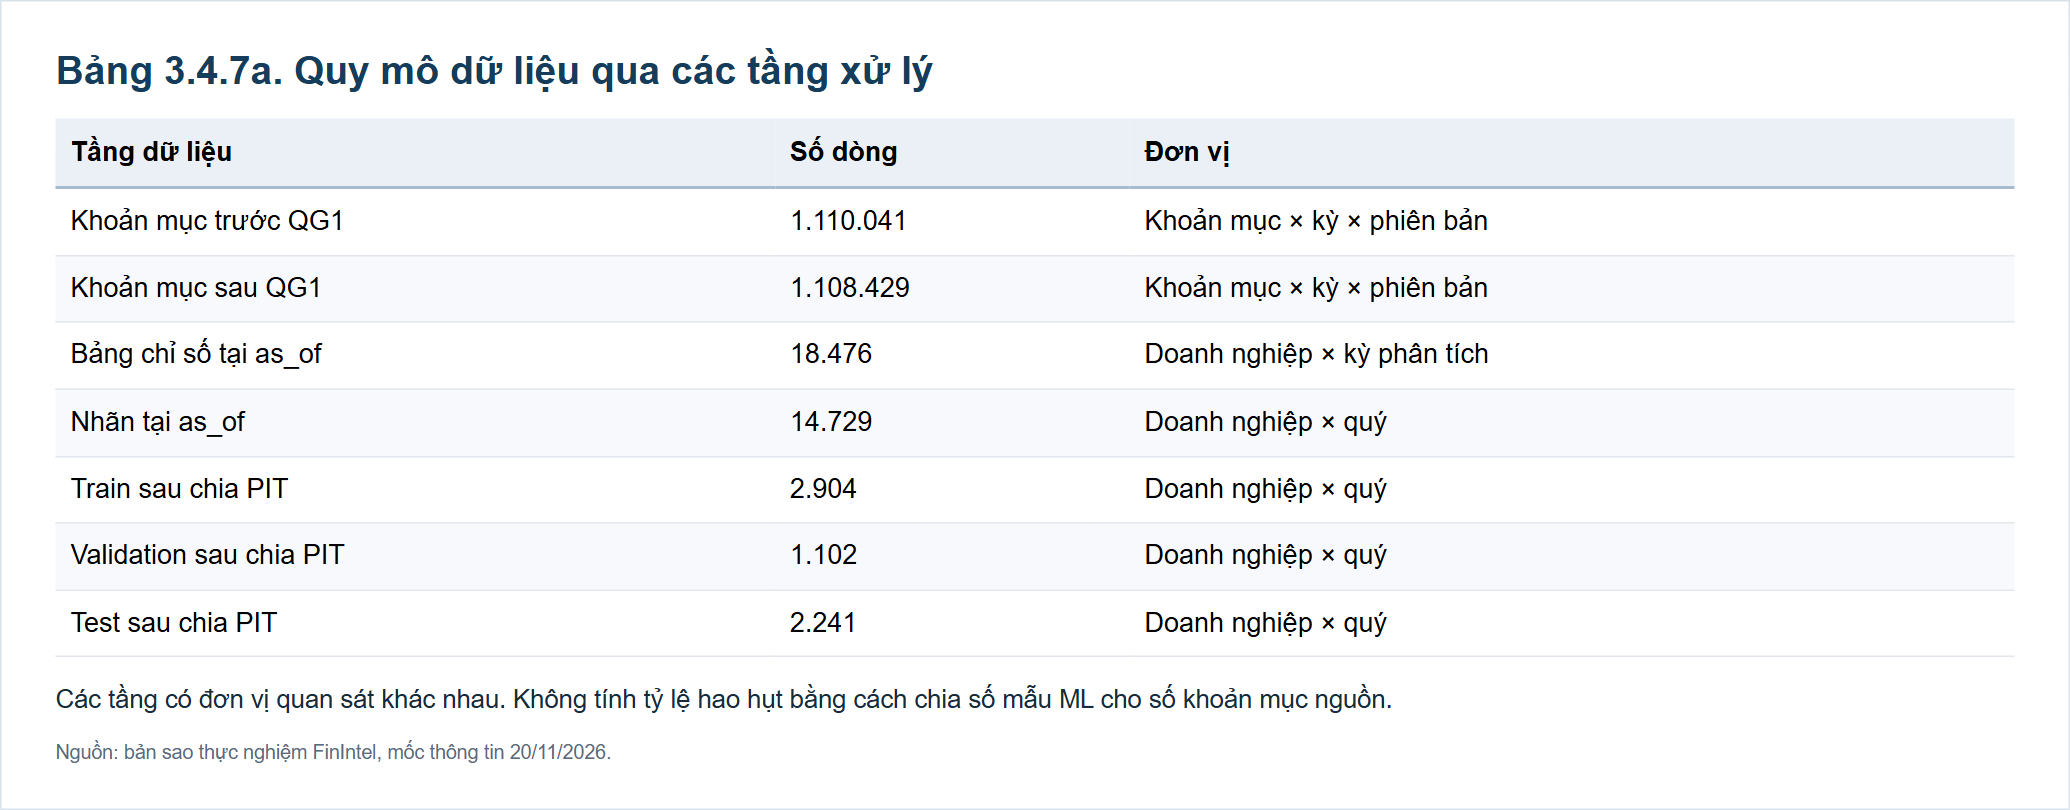

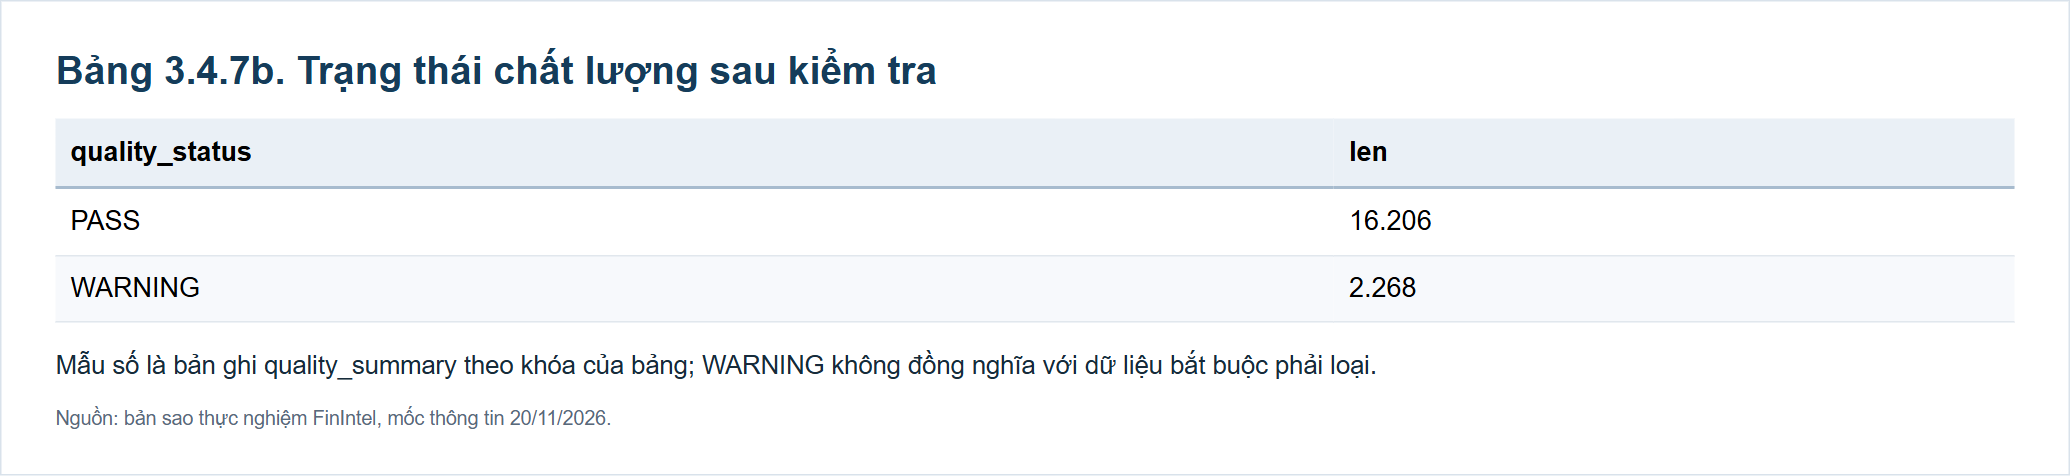

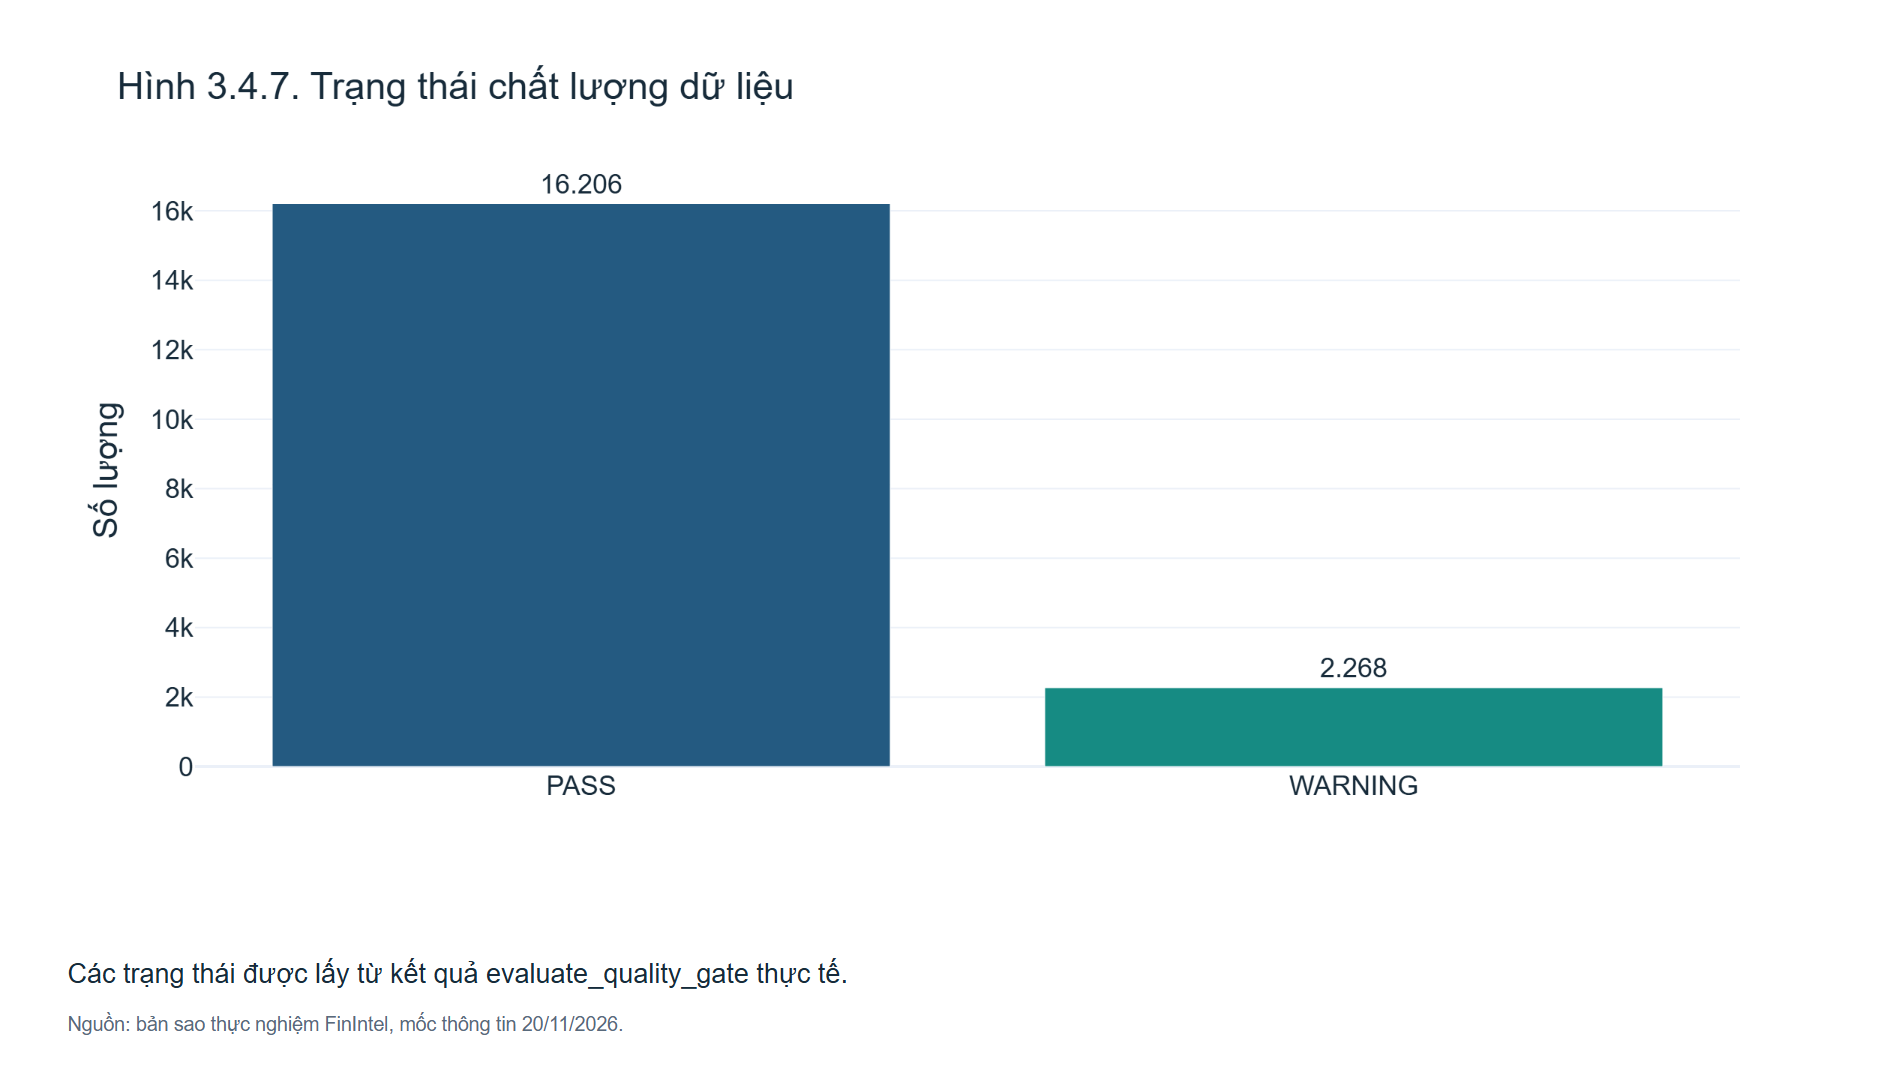

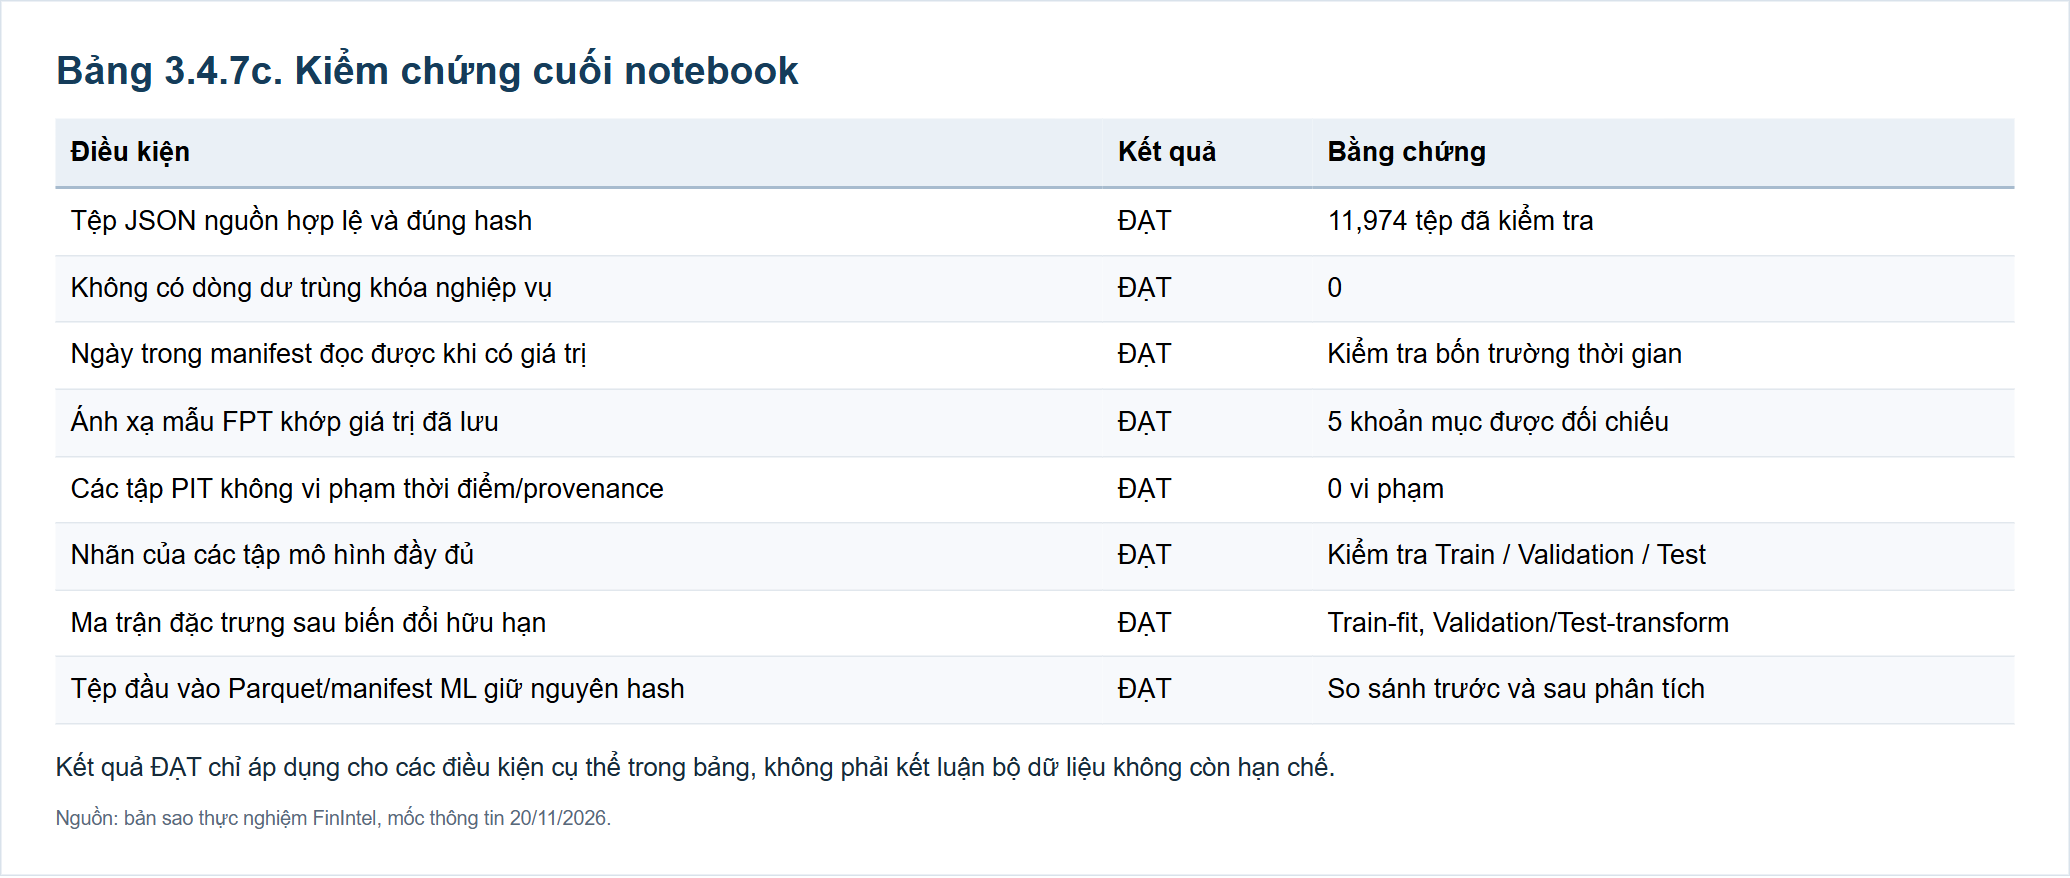

In [8]:
stages = [
    {
        "Tầng dữ liệu": "Khoản mục trước QG1",
        "Số dòng": canonical.height,
        "Đơn vị": "Khoản mục × kỳ × phiên bản",
    },
    {
        "Tầng dữ liệu": "Khoản mục sau QG1",
        "Số dòng": clean_facts.height,
        "Đơn vị": "Khoản mục × kỳ × phiên bản",
    },
    {
        "Tầng dữ liệu": "Bảng chỉ số tại as_of",
        "Số dòng": ratios.height,
        "Đơn vị": "Doanh nghiệp × kỳ phân tích",
    },
    {
        "Tầng dữ liệu": "Nhãn tại as_of",
        "Số dòng": labels.height,
        "Đơn vị": "Doanh nghiệp × quý",
    },
    {
        "Tầng dữ liệu": "Train sau chia PIT",
        "Số dòng": splits["train"].height,
        "Đơn vị": "Doanh nghiệp × quý",
    },
    {
        "Tầng dữ liệu": "Validation sau chia PIT",
        "Số dòng": splits["validation"].height,
        "Đơn vị": "Doanh nghiệp × quý",
    },
    {
        "Tầng dữ liệu": "Test sau chia PIT",
        "Số dòng": splits["test"].height,
        "Đơn vị": "Doanh nghiệp × quý",
    },
]
show_table(
    "Bảng 3.4.7a. Quy mô dữ liệu qua các tầng xử lý",
    stages,
    "Các tầng có đơn vị quan sát khác nhau. Không tính tỷ lệ hao hụt bằng cách chia số mẫu ML cho số khoản mục nguồn.",
)
quality_counts = quality.group_by("quality_status").len().sort("quality_status")
show_table(
    "Bảng 3.4.7b. Trạng thái chất lượng sau kiểm tra",
    quality_counts,
    "Mẫu số là bản ghi quality_summary theo khóa của bảng; WARNING không đồng nghĩa với dữ liệu bắt buộc phải loại.",
)
bar(
    "Hình 3.4.7. Trạng thái chất lượng dữ liệu",
    quality_counts["quality_status"].to_list(),
    quality_counts["len"].to_list(),
    "Các trạng thái được lấy từ kết quả evaluate_quality_gate thực tế.",
)
integrity = [
    (
        "Tệp JSON nguồn hợp lệ và đúng hash",
        len(raw_errors) == 0,
        f"{len(raw_paths):,} tệp đã kiểm tra",
    ),
    (
        "Không có dòng dư trùng khóa nghiệp vụ",
        duplicate_excess == 0,
        str(duplicate_excess),
    ),
    (
        "Ngày trong manifest đọc được khi có giá trị",
        all(
            row["Số lượng"] == 0
            for row in format_checks
            if row["Kiểm tra"].startswith("Ngày không đọc được")
        ),
        "Kiểm tra bốn trường thời gian",
    ),
    (
        "Ánh xạ mẫu FPT khớp giá trị đã lưu",
        len(compare) >= 3
        and all(
            row["Lệch so với dữ liệu lưu"] is not None
            and abs(row["Lệch so với dữ liệu lưu"]) < 0.5
            for row in compare
        ),
        f"{len(compare)} khoản mục được đối chiếu",
    ),
    (
        "Các tập PIT không vi phạm thời điểm/provenance",
        all(r["Số vi phạm"] == 0 for r in checks),
        f"{sum(r['Số vi phạm'] for r in checks)} vi phạm",
    ),
    (
        "Nhãn của các tập mô hình đầy đủ",
        all(f["distress_target"].null_count() == 0 for f in splits.values()),
        "Kiểm tra Train / Validation / Test",
    ),
    (
        "Ma trận đặc trưng sau biến đổi hữu hạn",
        all(
            r["Phần tử không hữu hạn sau biến đổi"] == 0 and r["NULL sau bù thiếu"] == 0
            for r in feature_missing
        ),
        "Train-fit, Validation/Test-transform",
    ),
    (
        "Tệp đầu vào Parquet/manifest ML giữ nguyên hash",
        all(
            hashlib.sha256((ROOT / p).read_bytes()).hexdigest() == h
            for p, h in SOURCE_HASHES.items()
        ),
        "So sánh trước và sau phân tích",
    ),
]
show_table(
    "Bảng 3.4.7c. Kiểm chứng cuối notebook",
    [
        {
            "Điều kiện": label,
            "Kết quả": "ĐẠT" if ok else "KHÔNG ĐẠT",
            "Bằng chứng": detail,
        }
        for label, ok, detail in integrity
    ],
    "Kết quả ĐẠT chỉ áp dụng cho các điều kiện cụ thể trong bảng, không phải kết luận bộ dữ liệu không còn hạn chế.",
)
assert all(ok for _, ok, _ in integrity), (
    "Có điều kiện kiểm chứng không đạt. Xem bảng kết quả, không dùng báo cáo như bằng chứng đạt toàn bộ."
)
